In [5]:

from pathlib import Path

# The notebook is inside /notebooks, so its parent is the project root.
PROJECT_ROOT = Path.cwd().parent

print("Project root:", PROJECT_ROOT)
print("Project root exists:", PROJECT_ROOT.exists())
print("Data directory exists:", (PROJECT_ROOT / "data").exists())
print("Raw data directory exists:", (PROJECT_ROOT / "data" / "raw").exists())


Project root: c:\Users\amitb\Desktop\ME\Projects\Data_Analysis_Practice\cricket-analytics-lab
Project root exists: True
Data directory exists: True
Raw data directory exists: True


In [6]:

# Find YAML files in the raw data directory
raw_dir = PROJECT_ROOT / "data" / "raw"

yaml_files = list(raw_dir.glob("*.yaml"))
yml_files = list(raw_dir.glob("*.yml"))

all_yaml_files = yaml_files + yml_files

print("Raw data directory:", raw_dir)
print("Number of .yaml files:", len(yaml_files))
print("Number of .yml files:", len(yml_files))
print("Total YAML files:", len(all_yaml_files))


Raw data directory: c:\Users\amitb\Desktop\ME\Projects\Data_Analysis_Practice\cricket-analytics-lab\data\raw
Number of .yaml files: 1243
Number of .yml files: 0
Total YAML files: 1243


In [7]:

print("First 10 filenames:")

for file_path in sorted(all_yaml_files)[:10]:
    print(file_path.name)


First 10 filenames:
1082591.yaml
1082592.yaml
1082593.yaml
1082594.yaml
1082595.yaml
1082596.yaml
1082597.yaml
1082598.yaml
1082599.yaml
1082600.yaml


In [8]:

import yaml

# Select the first match file
sample_file = sorted(all_yaml_files)[0]

print("Selected file:", sample_file.name)

with open(sample_file, "r", encoding="utf-8") as file:
    match_data = yaml.safe_load(file)

print("Data type:", type(match_data))
print("Top-level keys:", list(match_data.keys()))


Selected file: 1082591.yaml
Data type: <class 'dict'>
Top-level keys: ['meta', 'info', 'innings']


In [9]:

print("Metadata keys:")
print(list(match_data.get("meta", {}).keys()))

print("\nMatch information keys:")
print(list(match_data.get("info", {}).keys()))

print("\nInnings data type:")
print(type(match_data.get("innings")))

print("\nNumber of innings:")
print(len(match_data.get("innings", [])))


Metadata keys:
['data_version', 'created', 'revision']

Match information keys:
['balls_per_over', 'city', 'competition', 'dates', 'gender', 'match_type', 'outcome', 'overs', 'player_of_match', 'players', 'registry', 'teams', 'toss', 'umpires', 'venue', 'team_type']

Innings data type:
<class 'list'>

Number of innings:
2


In [10]:

for innings_number, innings_data in enumerate(
    match_data["innings"], start=1
):
    print(f"\nInnings {innings_number}")
    print("Type:", type(innings_data))
    print("Keys:", list(innings_data.keys()))

    # The Cricsheet format stores the innings label
    # as the key of the innings dictionary.
    innings_label = next(iter(innings_data))
    innings_details = innings_data[innings_label]

    print("Label:", innings_label)
    print("Details keys:", list(innings_details.keys()))
    print("Batting team:", innings_details.get("team"))
    print("Number of delivery entries:",
          len(innings_details.get("deliveries", [])))



Innings 1
Type: <class 'dict'>
Keys: ['1st innings']
Label: 1st innings
Details keys: ['team', 'deliveries']
Batting team: Sunrisers Hyderabad
Number of delivery entries: 125

Innings 2
Type: <class 'dict'>
Keys: ['2nd innings']
Label: 2nd innings
Details keys: ['team', 'deliveries', 'target']
Batting team: Royal Challengers Bangalore
Number of delivery entries: 123


In [11]:

# Get the first innings
first_innings = match_data["innings"][0]

# Get the innings label and its details
innings_label = next(iter(first_innings))
innings_details = first_innings[innings_label]

# Get the first delivery entry
first_delivery_entry = innings_details["deliveries"][0]

print("Delivery entry:")
print(first_delivery_entry)

print("\nEntry type:", type(first_delivery_entry))


Delivery entry:
{0.1: {'actual_delivery': '0.1', 'batsman': 'DA Warner', 'bowler': 'TS Mills', 'non_striker': 'S Dhawan', 'runs': {'batsman': 0, 'extras': 0, 'total': 0}}}

Entry type: <class 'dict'>


In [12]:

# Each delivery entry uses its delivery identifier as a key
delivery_identifier = next(iter(first_delivery_entry))
delivery_details = first_delivery_entry[delivery_identifier]

print("Delivery identifier:", delivery_identifier)
print("Delivery fields:", list(delivery_details.keys()))

print("\nFull delivery details:")
print(delivery_details)


Delivery identifier: 0.1
Delivery fields: ['actual_delivery', 'batsman', 'bowler', 'non_striker', 'runs']

Full delivery details:
{'actual_delivery': '0.1', 'batsman': 'DA Warner', 'bowler': 'TS Mills', 'non_striker': 'S Dhawan', 'runs': {'batsman': 0, 'extras': 0, 'total': 0}}


In [13]:

# Inspect all deliveries in the sample match
first_innings = match_data["innings"][0]
innings_label = next(iter(first_innings))
innings_details = first_innings[innings_label]

deliveries = innings_details["deliveries"]

# Count which optional event fields appear
extras_count = 0
wicket_count = 0

for delivery_entry in deliveries:
    delivery_id = next(iter(delivery_entry))
    delivery = delivery_entry[delivery_id]

    if "extras" in delivery:
        extras_count += 1

    if "wicket" in delivery:
        wicket_count += 1

print("Total delivery entries:", len(deliveries))
print("Deliveries with extras:", extras_count)
print("Deliveries with wicket records:", wicket_count)


Total delivery entries: 125
Deliveries with extras: 6
Deliveries with wicket records: 4


In [14]:

extras_count = 0
wicket_count = 0
both_count = 0

for delivery_entry in deliveries:
    delivery_id = next(iter(delivery_entry))
    delivery = delivery_entry[delivery_id]

    has_extras = "extras" in delivery
    has_wicket = "wicket" in delivery

    if has_extras:
        extras_count += 1

    if has_wicket:
        wicket_count += 1

    if has_extras and has_wicket:
        both_count += 1

print("Deliveries with extras:", extras_count)
print("Deliveries with wickets:", wicket_count)
print("Deliveries with both:", both_count)
print(
    "Unique deliveries with extras or wickets:",
    extras_count + wicket_count - both_count
)


Deliveries with extras: 6
Deliveries with wickets: 4
Deliveries with both: 0
Unique deliveries with extras or wickets: 10


In [15]:

from collections import Counter

extras_types = Counter()

for delivery_entry in deliveries:
    delivery_id = next(iter(delivery_entry))
    delivery = delivery_entry[delivery_id]

    for extra_type, runs in delivery.get("extras", {}).items():
        extras_types[extra_type] += 1

print("Extras types and their occurrence counts:")
print(extras_types)


Extras types and their occurrence counts:
Counter({'wides': 4, 'legbyes': 1, 'noballs': 1})


In [16]:

from collections import Counter

extras_occurrences = Counter()
extras_runs = Counter()

for delivery_entry in deliveries:
    delivery_id = next(iter(delivery_entry))
    delivery = delivery_entry[delivery_id]

    for extra_type, runs in delivery.get("extras", {}).items():
        extras_occurrences[extra_type] += 1
        extras_runs[extra_type] += runs

print("Extras analysis")
print("-" * 40)

for extra_type in sorted(extras_occurrences):
    print(
        f"{extra_type}: "
        f"{extras_occurrences[extra_type]} occurrences, "
        f"{extras_runs[extra_type]} runs"
    )

print("-" * 40)
print("Total extras runs:", sum(extras_runs.values()))


Extras analysis
----------------------------------------
legbyes: 1 occurrences, 1 runs
noballs: 1 occurrences, 1 runs
wides: 4 occurrences, 5 runs
----------------------------------------
Total extras runs: 7


In [17]:

from collections import Counter

wicket_types = Counter()
dismissed_players = Counter()

for delivery_entry in deliveries:
    delivery_id = next(iter(delivery_entry))
    delivery = delivery_entry[delivery_id]

    wicket = delivery.get("wicket")

    if wicket:
        wicket_types[wicket["kind"]] += 1
        dismissed_players[wicket["player_out"]] += 1

print("Wicket types:")
print(wicket_types)

print("\nDismissed players:")
print(dismissed_players)


Wicket types:
Counter({'caught': 3, 'bowled': 1})

Dismissed players:
Counter({'DA Warner': 1, 'S Dhawan': 1, 'MC Henriques': 1, 'Yuvraj Singh': 1})


In [18]:
# Dismissal types generally not credited to the bowler
non_bowler_wicket_types = {
    "run out",
    "retired hurt",
    "obstructing the field"
}

total_dismissals = 0
bowler_wickets = 0

for delivery_entry in deliveries:
    delivery_id = next(iter(delivery_entry))
    delivery = delivery_entry[delivery_id]

    wicket = delivery.get("wicket")

    if wicket:
        total_dismissals += 1

        if wicket["kind"] not in non_bowler_wicket_types:
            bowler_wickets += 1

print("Total dismissals:", total_dismissals)
print("Bowler-credit wickets:", bowler_wickets)

Total dismissals: 4
Bowler-credit wickets: 4


In [19]:
delivery_rows = []

for innings_number, innings_entry in enumerate(match_data["innings"], start=1):
    innings_label = next(iter(innings_entry))
    innings_data = innings_entry[innings_label]

    for delivery_entry in innings_data["deliveries"]:
        delivery_id = next(iter(delivery_entry))
        delivery = delivery_entry[delivery_id]
        runs = delivery["runs"]

        row = {
            "innings": innings_number,
            "delivery": delivery_id,
            "batter": delivery["batsman"],
            "bowler": delivery["bowler"],
            "batter_runs": runs["batsman"],
            "extras_runs": runs["extras"],
            "total_runs": runs["total"],
            "wicket": delivery.get("wicket") is not None,
        }

        delivery_rows.append(row)

print("Rows:", len(delivery_rows))
print("First row:", delivery_rows[0])

Rows: 248
First row: {'innings': 1, 'delivery': 0.1, 'batter': 'DA Warner', 'bowler': 'TS Mills', 'batter_runs': 0, 'extras_runs': 0, 'total_runs': 0, 'wicket': False}


In [20]:
import pandas as pd

deliveries_df = pd.DataFrame(delivery_rows)

print("Shape:", deliveries_df.shape)
print("\nMissing values:")
print(deliveries_df.isna().sum())

print("\nRun consistency:")
print(
    "All rows consistent:",
    (
        deliveries_df["batter_runs"] + deliveries_df["extras_runs"]
        == deliveries_df["total_runs"]
    ).all()
)

print("\nRun totals:")
print(deliveries_df[["batter_runs", "extras_runs", "total_runs"]].sum())

display(deliveries_df.head(10))

Shape: (248, 8)

Missing values:
innings        0
delivery       0
batter         0
bowler         0
batter_runs    0
extras_runs    0
total_runs     0
wicket         0
dtype: int64

Run consistency:
All rows consistent: True

Run totals:
batter_runs    366
extras_runs     13
total_runs     379
dtype: int64


,innings,delivery,batter,bowler,batter_runs,extras_runs,total_runs,wicket
0,1,0.1,DA Warner,TS Mills,0,0,0,False
1,1,0.2,DA Warner,TS Mills,0,0,0,False
2,1,0.3,DA Warner,TS Mills,4,0,4,False
3,1,0.4,DA Warner,TS Mills,0,0,0,False
4,1,0.5,DA Warner,TS Mills,0,2,2,False
5,1,0.6,S Dhawan,TS Mills,0,0,0,False
6,1,0.7,S Dhawan,TS Mills,0,1,1,False
7,1,1.1,S Dhawan,A Choudhary,1,0,1,False
8,1,1.2,DA Warner,A Choudhary,4,0,4,False
9,1,1.3,DA Warner,A Choudhary,0,1,1,False


In [21]:
# Validate the flattened delivery dataset

print("Shape:", deliveries_df.shape)

print(
    "Run consistency:",
    (
        deliveries_df["batter_runs"] + deliveries_df["extras_runs"]
        == deliveries_df["total_runs"]
    ).all()
)

print("Missing values:")
print(deliveries_df.isna().sum())

print("Total runs:", deliveries_df["total_runs"].sum())
print("Batter runs:", deliveries_df["batter_runs"].sum())
print("Extras runs:", deliveries_df["extras_runs"].sum())
print("Recorded wicket deliveries:", deliveries_df["wicket"].sum())

Shape: (248, 8)
Run consistency: True
Missing values:
innings        0
delivery       0
batter         0
bowler         0
batter_runs    0
extras_runs    0
total_runs     0
wicket         0
dtype: int64
Total runs: 379
Batter runs: 366
Extras runs: 13
Recorded wicket deliveries: 14


In [22]:

delivery_rows_detailed = []

for innings_number, innings_entry in enumerate(match_data["innings"], start=1):
    innings_label = next(iter(innings_entry))
    innings_data = innings_entry[innings_label]

    for delivery_entry in innings_data["deliveries"]:
        delivery_id = next(iter(delivery_entry))
        delivery = delivery_entry[delivery_id]

        runs = delivery["runs"]
        extras = delivery.get("extras", {})
        wicket = delivery.get("wicket", {})

        row = {
            "innings": innings_number,
            "delivery": delivery_id,
            "batter": delivery["batsman"],
            "bowler": delivery["bowler"],
            "batter_runs": runs["batsman"],
            "extras_runs": runs["extras"],
            "total_runs": runs["total"],
            "wides": extras.get("wides", 0),
            "noballs": extras.get("noballs", 0),
            "byes": extras.get("byes", 0),
            "legbyes": extras.get("legbyes", 0),
            "wicket": bool(wicket),
            "wicket_kind": wicket.get("kind"),
            "player_out": wicket.get("player_out"),
        }

        delivery_rows_detailed.append(row)

deliveries_detailed_df = pd.DataFrame(delivery_rows_detailed)

print("Shape:", deliveries_detailed_df.shape)
display(deliveries_detailed_df.head(10))


Shape: (248, 14)


,innings,delivery,batter,bowler,batter_runs,extras_runs,total_runs,wides,noballs,byes,legbyes,wicket,wicket_kind,player_out
0,1,0.1,DA Warner,TS Mills,0,0,0,0,0,0,0,False,NaN,NaN
1,1,0.2,DA Warner,TS Mills,0,0,0,0,0,0,0,False,NaN,NaN
2,1,0.3,DA Warner,TS Mills,4,0,4,0,0,0,0,False,NaN,NaN
3,1,0.4,DA Warner,TS Mills,0,0,0,0,0,0,0,False,NaN,NaN
4,1,0.5,DA Warner,TS Mills,0,2,2,2,0,0,0,False,NaN,NaN
5,1,0.6,S Dhawan,TS Mills,0,0,0,0,0,0,0,False,NaN,NaN
6,1,0.7,S Dhawan,TS Mills,0,1,1,0,0,0,1,False,NaN,NaN
7,1,1.1,S Dhawan,A Choudhary,1,0,1,0,0,0,0,False,NaN,NaN
8,1,1.2,DA Warner,A Choudhary,4,0,4,0,0,0,0,False,NaN,NaN
9,1,1.3,DA Warner,A Choudhary,0,1,1,0,1,0,0,False,NaN,NaN


In [23]:
# 1. Check whether batter runs + extras runs = total runs
run_check = (
    deliveries_detailed_df["batter_runs"]
    + deliveries_detailed_df["extras_runs"]
    == deliveries_detailed_df["total_runs"]
)

# 2. Check whether the four extras columns sum to extras_runs
extras_check = (
    deliveries_detailed_df["wides"]
    + deliveries_detailed_df["noballs"]
    + deliveries_detailed_df["byes"]
    + deliveries_detailed_df["legbyes"]
    == deliveries_detailed_df["extras_runs"]
)

# 3. Summarize validation results
print("All run totals consistent:", run_check.all())
print("All extras totals consistent:", extras_check.all())
print("Recorded wicket deliveries:", deliveries_detailed_df["wicket"].sum())
print("Missing batter names:", deliveries_detailed_df["batter"].isna().sum())
print("Missing bowler names:", deliveries_detailed_df["bowler"].isna().sum())
print("Dismissal types:")
print(deliveries_detailed_df["wicket_kind"].value_counts(dropna=False))

All run totals consistent: True
All extras totals consistent: True
Recorded wicket deliveries: 14
Missing batter names: 0
Missing bowler names: 0
Dismissal types:
wicket_kind
NaN        234
caught       9
bowled       3
run out      2
Name: count, dtype: int64


In [24]:
# Group deliveries by batter and calculate basic batting metrics

batting_stats = deliveries_detailed_df.groupby("batter").agg(
    runs=("batter_runs", "sum"),
    fours=("batter_runs", lambda x: (x == 4).sum()),
    sixes=("batter_runs", lambda x: (x == 6).sum()),
    deliveries_faced=("wides", lambda x: 0)  # placeholder, corrected below
)

# A batter does not face a wide delivery
legal_to_batter = deliveries_detailed_df["wides"] == 0

balls_faced = (
    deliveries_detailed_df.assign(
        ball_faced=legal_to_batter.astype(int)
    )
    .groupby("batter")["ball_faced"]
    .sum()
)

batting_stats["balls_faced"] = balls_faced
batting_stats["strike_rate"] = (
    batting_stats["runs"] / batting_stats["balls_faced"] * 100
).round(2)

batting_stats = batting_stats.drop(columns=["deliveries_faced"])
batting_stats = batting_stats.sort_values("runs", ascending=False)

display(batting_stats)

,runs,fours,sixes,balls_faced,strike_rate
batter,,,,,
Yuvraj Singh,62,7,3,27,229.63
MC Henriques,52,3,2,37,140.54
S Dhawan,40,5,0,31,129.03
CH Gayle,32,2,3,21,152.38
KM Jadhav,31,4,1,16,193.75
TM Head,30,3,0,22,136.36
Mandeep Singh,24,5,0,16,150.00
SR Watson,22,1,1,17,129.41
DJ Hooda,16,0,1,12,133.33


In [25]:
# Final batting analysis for this sample match

# A batter is not charged a ball faced for a wide or a delivery
# recorded as a no-ball, unless the delivery also has a specific
# exception that requires more detailed cricket-rule handling.
balls_faced_mask = (
    (deliveries_detailed_df["wides"] == 0)
    & (deliveries_detailed_df["noballs"] == 0)
)

deliveries_detailed_df["ball_faced"] = balls_faced_mask.astype(int)

batting_stats = deliveries_detailed_df.groupby("batter").agg(
    runs=("batter_runs", "sum"),
    balls_faced=("ball_faced", "sum"),
    fours=("batter_runs", lambda x: (x == 4).sum()),
    sixes=("batter_runs", lambda x: (x == 6).sum()),
)

batting_stats["strike_rate"] = (
    batting_stats["runs"] / batting_stats["balls_faced"] * 100
).round(2)

batting_stats["boundary_runs"] = (
    batting_stats["fours"] * 4 + batting_stats["sixes"] * 6
)

batting_stats["boundary_percentage"] = (
    batting_stats["boundary_runs"] / batting_stats["runs"].replace(0, float("nan")) * 100
).round(2)

batting_stats = batting_stats.sort_values("runs", ascending=False)

display(batting_stats)

,runs,balls_faced,fours,sixes,strike_rate,boundary_runs,boundary_percentage
batter,,,,,,,
Yuvraj Singh,62,27,7,3,229.63,46,74.19
MC Henriques,52,37,3,2,140.54,24,46.15
S Dhawan,40,31,5,0,129.03,20,50.00
CH Gayle,32,21,2,3,152.38,26,81.25
KM Jadhav,31,15,4,1,206.67,22,70.97
TM Head,30,22,3,0,136.36,12,40.00
Mandeep Singh,24,16,5,0,150.00,20,83.33
SR Watson,22,17,1,1,129.41,10,45.45
DJ Hooda,16,12,0,1,133.33,6,37.50


In [26]:
# Bowling analysis for the sample match

non_bowler_wickets = {
    "run out",
    "retired hurt",
    "obstructing the field",
}

deliveries_detailed_df["bowler_runs_conceded"] = (
    deliveries_detailed_df["total_runs"]
    - deliveries_detailed_df["byes"]
    - deliveries_detailed_df["legbyes"]
)

deliveries_detailed_df["bowler_wicket"] = (
    deliveries_detailed_df["wicket"]
    & ~deliveries_detailed_df["wicket_kind"].isin(non_bowler_wickets)
)

bowling_stats = deliveries_detailed_df.groupby("bowler").agg(
    runs_conceded=("bowler_runs_conceded", "sum"),
    wickets=("bowler_wicket", "sum"),
    deliveries_recorded=("delivery", "count"),
)

# Legal balls: exclude wides and no-balls
legal_balls = deliveries_detailed_df[
    (deliveries_detailed_df["wides"] == 0)
    & (deliveries_detailed_df["noballs"] == 0)
].groupby("bowler").size()

bowling_stats["legal_balls"] = legal_balls
bowling_stats["overs"] = (
    bowling_stats["legal_balls"] // 6
    + (bowling_stats["legal_balls"] % 6) / 10
)

bowling_stats["economy"] = (
    bowling_stats["runs_conceded"] / bowling_stats["legal_balls"] * 6
).round(2)

bowling_stats = bowling_stats.sort_values(
    ["wickets", "economy"], ascending=[False, True]
)

display(bowling_stats)

,runs_conceded,wickets,deliveries_recorded,legal_balls,overs,economy
bowler,,,,,,
B Kumar,27,2,25,24,4.0,6.75
Rashid Khan,36,2,24,24,4.0,9.00
A Nehra,42,2,25,24,4.0,10.50
Bipul Sharma,4,1,6,6,1.0,4.00
YS Chahal,22,1,24,24,4.0,5.50
DJ Hooda,7,1,6,6,1.0,7.00
TS Mills,31,1,25,24,4.0,7.75
STR Binny,10,1,6,6,1.0,10.00
A Choudhary,55,1,28,24,4.0,13.75


In [27]:
# Validate bowling statistics

print(
    "Total runs in delivery data:",
    deliveries_detailed_df["total_runs"].sum()
)

print(
    "Total bowler runs conceded:",
    deliveries_detailed_df["bowler_runs_conceded"].sum()
)

print(
    "Total recorded dismissals:",
    deliveries_detailed_df["wicket"].sum()
)

print(
    "Total bowler-credit wickets:",
    deliveries_detailed_df["bowler_wicket"].sum()
)

print("\nDismissal types:")
print(deliveries_detailed_df["wicket_kind"].value_counts())

Total runs in delivery data: 379
Total bowler runs conceded: 377
Total recorded dismissals: 14
Total bowler-credit wickets: 12

Dismissal types:
wicket_kind
caught     9
bowled     3
run out    2
Name: count, dtype: int64


In [28]:
# Investigate runs not charged to bowlers

deliveries_detailed_df["non_bowler_runs"] = (
    deliveries_detailed_df["byes"]
    + deliveries_detailed_df["legbyes"]
)

print("Runs from byes and leg-byes:",
      deliveries_detailed_df["non_bowler_runs"].sum())

print("\nDeliveries containing byes or leg-byes:")
display(
    deliveries_detailed_df.loc[
        deliveries_detailed_df["non_bowler_runs"] > 0,
        [
            "innings", "delivery", "batter", "bowler",
            "total_runs", "byes", "legbyes",
            "bowler_runs_conceded"
        ]
    ]
)

Runs from byes and leg-byes: 2

Deliveries containing byes or leg-byes:


,innings,delivery,batter,bowler,total_runs,byes,legbyes,bowler_runs_conceded
6,1,0.7,S Dhawan,TS Mills,1,0,1,0
238,2,18.1,TS Mills,B Kumar,1,0,1,0


In [29]:
# Inspect all recorded wicket events

wicket_details = deliveries_detailed_df.loc[
    deliveries_detailed_df["wicket"],
    [
        "innings",
        "delivery",
        "batter",
        "bowler",
        "wicket_kind",
        "player_out",
    ],
]

print("Total wicket events:", len(wicket_details))
print("\nDismissal types:")
print(wicket_details["wicket_kind"].value_counts())

print("\nFull wicket details:")
display(wicket_details)

Total wicket events: 14

Dismissal types:
wicket_kind
caught     9
bowled     3
run out    2
Name: count, dtype: int64

Full wicket details:


,innings,delivery,batter,bowler,wicket_kind,player_out
11,1,1.5,DA Warner,A Choudhary,caught,DA Warner
64,1,10.3,S Dhawan,STR Binny,caught,S Dhawan
94,1,15.2,MC Henriques,YS Chahal,caught,MC Henriques
116,1,18.4,Yuvraj Singh,TS Mills,bowled,Yuvraj Singh
160,2,5.4,Mandeep Singh,Rashid Khan,bowled,Mandeep Singh
165,2,6.3,CH Gayle,DJ Hooda,caught,CH Gayle
199,2,11.4,KM Jadhav,MC Henriques,run out,KM Jadhav
206,2,12.5,TM Head,Rashid Khan,caught,TM Head
211,2,13.4,Sachin Baby,Bipul Sharma,caught,Sachin Baby
230,2,16.5,STR Binny,B Kumar,caught,STR Binny


In [30]:
# Final bowling analysis

non_bowler_wickets = {
    "run out",
    "retired hurt",
    "obstructing the field",
}

deliveries_detailed_df["bowler_wicket"] = (
    deliveries_detailed_df["wicket"]
    & ~deliveries_detailed_df["wicket_kind"].isin(non_bowler_wickets)
)

bowling_stats = deliveries_detailed_df.groupby("bowler").agg(
    runs_conceded=("bowler_runs_conceded", "sum"),
    wickets=("bowler_wicket", "sum"),
    legal_balls=("bowler_wicket", "size"),
)

# Recalculate legal balls correctly: wides and no-balls do not count
legal_ball_counts = (
    deliveries_detailed_df.loc[
        (deliveries_detailed_df["wides"] == 0)
        & (deliveries_detailed_df["noballs"] == 0)
    ]
    .groupby("bowler")
    .size()
)

bowling_stats["legal_balls"] = legal_ball_counts
bowling_stats["overs"] = (
    bowling_stats["legal_balls"] // 6
    + (bowling_stats["legal_balls"] % 6) / 10
)

bowling_stats["economy"] = (
    bowling_stats["runs_conceded"] * 6
    / bowling_stats["legal_balls"]
).round(2)

bowling_stats = bowling_stats.drop(columns="legal_balls", errors="ignore")
bowling_stats["legal_balls"] = legal_ball_counts
bowling_stats = bowling_stats.sort_values(
    ["wickets", "economy"], ascending=[False, True]
)

display(bowling_stats)

,runs_conceded,wickets,overs,economy,legal_balls
bowler,,,,,
B Kumar,27,2,4.0,6.75,24
Rashid Khan,36,2,4.0,9.00,24
A Nehra,42,2,4.0,10.50,24
Bipul Sharma,4,1,1.0,4.00,6
YS Chahal,22,1,4.0,5.50,24
DJ Hooda,7,1,1.0,7.00,6
TS Mills,31,1,4.0,7.75,24
STR Binny,10,1,1.0,10.00,6
A Choudhary,55,1,4.0,13.75,24


In [31]:
# Match-level innings summary

innings_summary = []

for innings_number, innings_entry in enumerate(match_data["innings"], start=1):
    innings_label = next(iter(innings_entry))
    innings_data = innings_entry[innings_label]

    innings_df = deliveries_detailed_df[
        deliveries_detailed_df["innings"] == innings_number
    ]

    innings_summary.append({
        "innings": innings_number,
        "batting_team": innings_data["team"],
        "delivery_entries": len(innings_df),
        "total_runs": innings_df["total_runs"].sum(),
        "extras_runs": innings_df["extras_runs"].sum(),
        "recorded_dismissals": innings_df["wicket"].sum(),
    })

innings_summary_df = pd.DataFrame(innings_summary)

display(innings_summary_df)

,innings,batting_team,delivery_entries,total_runs,extras_runs,recorded_dismissals
0,1,Sunrisers Hyderabad,125,207,7,4
1,2,Royal Challengers Bangalore,123,172,6,10


In [32]:
# Match result

first_innings = innings_summary_df.iloc[0]
second_innings = innings_summary_df.iloc[1]

if first_innings["total_runs"] > second_innings["total_runs"]:
    winner = first_innings["batting_team"]
    margin = first_innings["total_runs"] - second_innings["total_runs"]
    result = f"{winner} won by {margin} runs"

elif second_innings["total_runs"] > first_innings["total_runs"]:
    winner = second_innings["batting_team"]
    wickets_remaining = 10 - second_innings["recorded_dismissals"]
    result = f"{winner} won by {wickets_remaining} wickets"

else:
    result = "Match tied"

print(result)

Sunrisers Hyderabad won by 35 runs


In [33]:
# Team batting performance

team_performance = []

for innings_number, innings_entry in enumerate(match_data["innings"], start=1):
    innings_label = next(iter(innings_entry))
    team = innings_entry[innings_label]["team"]

    df = deliveries_detailed_df[
        deliveries_detailed_df["innings"] == innings_number
    ]

    total_runs = df["total_runs"].sum()
    batter_runs = df["batter_runs"].sum()
    extras = df["extras_runs"].sum()

    fours = (df["batter_runs"] == 4).sum()
    sixes = (df["batter_runs"] == 6).sum()

    team_performance.append({
        "team": team,
        "total_runs": total_runs,
        "batter_runs": batter_runs,
        "extras": extras,
        "fours": fours,
        "sixes": sixes,
        "boundary_runs": fours * 4 + sixes * 6,
        "extras_percentage": round(extras / total_runs * 100, 2)
    })

team_performance_df = pd.DataFrame(team_performance)
display(team_performance_df)

,team,total_runs,batter_runs,extras,fours,sixes,boundary_runs,extras_percentage
0,Sunrisers Hyderabad,207,200,7,17,9,122,3.38
1,Royal Challengers Bangalore,172,166,6,15,8,108,3.49


In [ ]:
# Runs scored in each innings phase

phase_rows = []

for innings_number, innings_entry in enumerate(match_data["innings"], start=1):
    innings_label = next(iter(innings_entry))
    team = innings_entry[innings_label]["team"]

    df = deliveries_detailed_df[
        deliveries_detailed_df["innings"] == innings_number
    ].copy()

    # YAML delivery identifiers are like 0.1, 5.6, 16.3
    df["over_number"] = df["delivery"].astype(str).str.split(".").str[0].astype(int) + 1

    df["phase"] = pd.cut(
        df["over_number"],
        bins=[0, 6, 15, 20],
        labels=["Powerplay", "Middle", "Death"]
    )

    for phase, group in df.groupby("phase", observed=False):
        phase_rows.append({
            "team": team,
            "phase": phase,
            "runs": group["total_runs"].sum(),
            "delivery_entries": len(group),
            "wickets": group["wicket"].sum()
        })

phase_df = pd.DataFrame(phase_rows)
display(phase_df)

In [34]:
# Runs scored in each innings phase

phase_rows = []

for innings_number, innings_entry in enumerate(match_data["innings"], start=1):
    innings_label = next(iter(innings_entry))
    team = innings_entry[innings_label]["team"]

    df = deliveries_detailed_df[
        deliveries_detailed_df["innings"] == innings_number
    ].copy()

    # YAML delivery identifiers are like 0.1, 5.6, 16.3
    df["over_number"] = df["delivery"].astype(str).str.split(".").str[0].astype(int) + 1

    df["phase"] = pd.cut(
        df["over_number"],
        bins=[0, 6, 15, 20],
        labels=["Powerplay", "Middle", "Death"]
    )

    for phase, group in df.groupby("phase", observed=False):
        phase_rows.append({
            "team": team,
            "phase": phase,
            "runs": group["total_runs"].sum(),
            "delivery_entries": len(group),
            "wickets": group["wicket"].sum()
        })

phase_df = pd.DataFrame(phase_rows)
display(phase_df)

,team,phase,runs,delivery_entries,wickets
0,Sunrisers Hyderabad,Powerplay,59,38,1
1,Sunrisers Hyderabad,Middle,92,55,1
2,Sunrisers Hyderabad,Death,56,32,2
3,Royal Challengers Bangalore,Powerplay,54,38,1
4,Royal Challengers Bangalore,Middle,85,57,4
5,Royal Challengers Bangalore,Death,33,28,5


In [35]:
# Runs scored in each innings phase

phase_rows = []

for innings_number, innings_entry in enumerate(match_data["innings"], start=1):
    innings_label = next(iter(innings_entry))
    team = innings_entry[innings_label]["team"]

    df = deliveries_detailed_df[
        deliveries_detailed_df["innings"] == innings_number
    ].copy()

    # YAML delivery identifiers are like 0.1, 5.6, 16.3
    df["over_number"] = df["delivery"].astype(str).str.split(".").str[0].astype(int) + 1

    df["phase"] = pd.cut(
        df["over_number"],
        bins=[0, 6, 15, 20],
        labels=["Powerplay", "Middle", "Death"]
    )

    for phase, group in df.groupby("phase", observed=False):
        phase_rows.append({
            "team": team,
            "phase": phase,
            "runs": group["total_runs"].sum(),
            "delivery_entries": len(group),
            "wickets": group["wicket"].sum()
        })

phase_df = pd.DataFrame(phase_rows)
display(phase_df)

,team,phase,runs,delivery_entries,wickets
0,Sunrisers Hyderabad,Powerplay,59,38,1
1,Sunrisers Hyderabad,Middle,92,55,1
2,Sunrisers Hyderabad,Death,56,32,2
3,Royal Challengers Bangalore,Powerplay,54,38,1
4,Royal Challengers Bangalore,Middle,85,57,4
5,Royal Challengers Bangalore,Death,33,28,5


In [36]:
# Phase run rates

phase_df["overs_approx"] = phase_df["delivery_entries"] / 6

phase_df["run_rate_approx"] = (
    phase_df["runs"] / phase_df["overs_approx"]
).round(2)

display(phase_df)

,team,phase,runs,delivery_entries,wickets,overs_approx,run_rate_approx
0,Sunrisers Hyderabad,Powerplay,59,38,1,6.333333,9.32
1,Sunrisers Hyderabad,Middle,92,55,1,9.166667,10.04
2,Sunrisers Hyderabad,Death,56,32,2,5.333333,10.50
3,Royal Challengers Bangalore,Powerplay,54,38,1,6.333333,8.53
4,Royal Challengers Bangalore,Middle,85,57,4,9.500000,8.95
5,Royal Challengers Bangalore,Death,33,28,5,4.666667,7.07


In [37]:
# Accurate phase run rates

legal_delivery_df = deliveries_detailed_df.copy()

legal_delivery_df["over_number"] = (
    legal_delivery_df["delivery"].astype(str)
    .str.split(".").str[0].astype(int) + 1
)

legal_delivery_df["phase"] = pd.cut(
    legal_delivery_df["over_number"],
    bins=[0, 6, 15, 20],
    labels=["Powerplay", "Middle", "Death"]
)

legal_delivery_df["is_legal_ball"] = (
    (legal_delivery_df["wides"] == 0) &
    (legal_delivery_df["noballs"] == 0)
)

accurate_phase_rows = []

for (innings, phase), group in legal_delivery_df.groupby(
    ["innings", "phase"], observed=False
):
    legal_balls = group["is_legal_ball"].sum()

    accurate_phase_rows.append({
        "innings": innings,
        "phase": phase,
        "runs": group["total_runs"].sum(),
        "legal_balls": int(legal_balls),
        "wickets": int(group["wicket"].sum()),
        "run_rate": round(
            group["total_runs"].sum() / (legal_balls / 6), 2
        ) if legal_balls else None
    })

accurate_phase_df = pd.DataFrame(accurate_phase_rows)

display(accurate_phase_df)

,innings,phase,runs,legal_balls,wickets,run_rate
0,1,Powerplay,59,36,1,9.83
1,1,Middle,92,54,1,10.22
2,1,Death,56,30,2,11.20
3,2,Powerplay,54,36,1,9.00
4,2,Middle,85,54,4,9.44
5,2,Death,33,28,5,7.07


In [38]:
# Wickets lost in each over

wicket_df = deliveries_detailed_df[
    deliveries_detailed_df["wicket"] == True
].copy()

wicket_df["over_number"] = (
    wicket_df["delivery"].astype(str)
    .str.split(".").str[0].astype(int) + 1
)

wicket_summary = (
    wicket_df.groupby(["innings", "over_number"])
    .agg(
        wickets=("wicket", "sum"),
        dismissed_players=("player_out", lambda x: ", ".join(x.dropna()))
    )
    .reset_index()
)

display(wicket_summary)

,innings,over_number,wickets,dismissed_players
0,1,2,1,DA Warner
1,1,11,1,S Dhawan
2,1,16,1,MC Henriques
3,1,19,1,Yuvraj Singh
4,2,6,1,Mandeep Singh
5,2,7,1,CH Gayle
6,2,12,1,KM Jadhav
7,2,13,1,TM Head
8,2,14,1,Sachin Baby
9,2,17,1,STR Binny


In [39]:
# Over-by-over innings progression

over_rows = []

for innings_number, innings_entry in enumerate(match_data["innings"], start=1):
    innings_label = next(iter(innings_entry))
    team = innings_entry[innings_label]["team"]

    df = deliveries_detailed_df[
        deliveries_detailed_df["innings"] == innings_number
    ].copy()

    df["over_number"] = (
        df["delivery"].astype(str)
        .str.split(".").str[0].astype(int) + 1
    )

    over_summary = (
        df.groupby("over_number")
        .agg(
            runs=("total_runs", "sum"),
            wickets=("wicket", "sum")
        )
        .reset_index()
        .sort_values("over_number")
    )

    over_summary["cumulative_runs"] = over_summary["runs"].cumsum()
    over_summary["cumulative_wickets"] = over_summary["wickets"].cumsum()
    over_summary["team"] = team

    over_rows.append(over_summary)

over_progression_df = pd.concat(over_rows, ignore_index=True)

display(over_progression_df)

,over_number,runs,wickets,cumulative_runs,cumulative_wickets,team
0,1,7,0,7,0,Sunrisers Hyderabad
1,2,16,1,23,1,Sunrisers Hyderabad
2,3,6,0,29,1,Sunrisers Hyderabad
3,4,4,0,33,1,Sunrisers Hyderabad
4,5,9,0,42,1,Sunrisers Hyderabad
5,6,17,0,59,1,Sunrisers Hyderabad
6,7,5,0,64,1,Sunrisers Hyderabad
7,8,11,0,75,1,Sunrisers Hyderabad
8,9,9,0,84,1,Sunrisers Hyderabad
9,10,4,0,88,1,Sunrisers Hyderabad


In [40]:
# Over-by-over innings progression

over_rows = []

for innings_number, innings_entry in enumerate(match_data["innings"], start=1):
    innings_label = next(iter(innings_entry))
    team = innings_entry[innings_label]["team"]

    df = deliveries_detailed_df[
        deliveries_detailed_df["innings"] == innings_number
    ].copy()

    df["over_number"] = (
        df["delivery"].astype(str)
        .str.split(".").str[0].astype(int) + 1
    )

    over_summary = (
        df.groupby("over_number")
        .agg(
            runs=("total_runs", "sum"),
            wickets=("wicket", "sum")
        )
        .reset_index()
        .sort_values("over_number")
    )

    over_summary["cumulative_runs"] = over_summary["runs"].cumsum()
    over_summary["cumulative_wickets"] = over_summary["wickets"].cumsum()
    over_summary["team"] = team

    over_rows.append(over_summary)

over_progression_df = pd.concat(over_rows, ignore_index=True)

display(over_progression_df)

,over_number,runs,wickets,cumulative_runs,cumulative_wickets,team
0,1,7,0,7,0,Sunrisers Hyderabad
1,2,16,1,23,1,Sunrisers Hyderabad
2,3,6,0,29,1,Sunrisers Hyderabad
3,4,4,0,33,1,Sunrisers Hyderabad
4,5,9,0,42,1,Sunrisers Hyderabad
5,6,17,0,59,1,Sunrisers Hyderabad
6,7,5,0,64,1,Sunrisers Hyderabad
7,8,11,0,75,1,Sunrisers Hyderabad
8,9,9,0,84,1,Sunrisers Hyderabad
9,10,4,0,88,1,Sunrisers Hyderabad


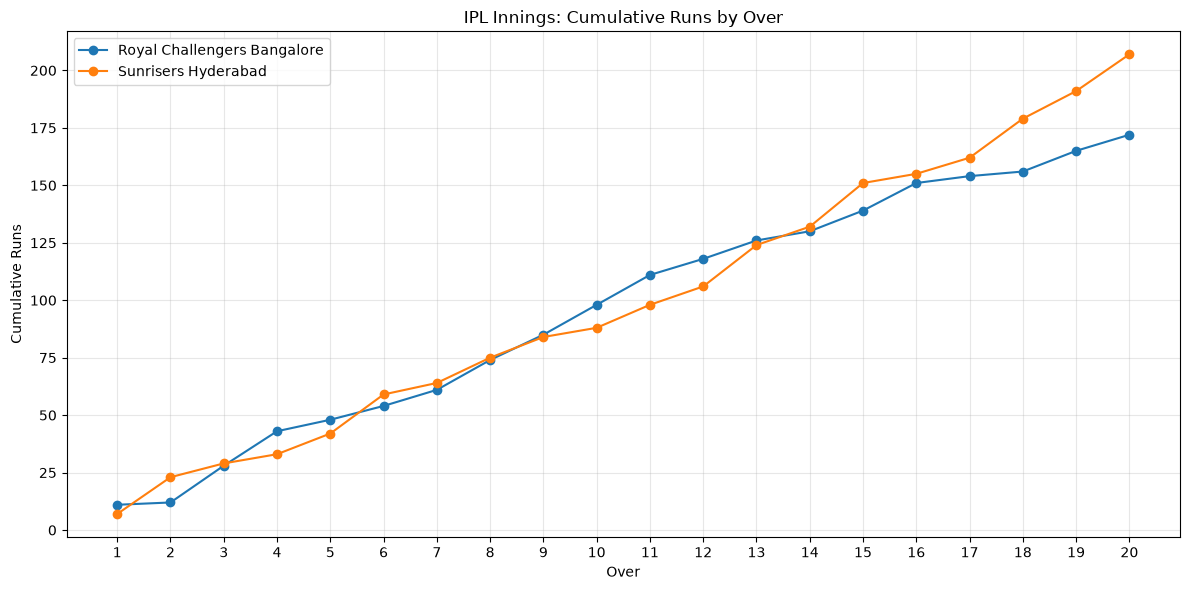

In [41]:
# Compare cumulative scoring progression

import matplotlib.pyplot as plt

plt.figure(figsize=(12, 6))

for team, group in over_progression_df.groupby("team"):
    plt.plot(
        group["over_number"],
        group["cumulative_runs"],
        marker="o",
        label=team
    )

plt.title("IPL Innings: Cumulative Runs by Over")
plt.xlabel("Over")
plt.ylabel("Cumulative Runs")
plt.xticks(range(1, 21))
plt.grid(True, alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()

In [42]:
# Partnership analysis

partnership_rows = []

for innings_number, innings_entry in enumerate(match_data["innings"], start=1):
    innings_label = next(iter(innings_entry))
    team = innings_entry[innings_label]["team"]

    df = deliveries_detailed_df[
        deliveries_detailed_df["innings"] == innings_number
    ].copy()

    current_batters = []
    partnership_runs = 0
    partnership_balls = 0

    for _, row in df.iterrows():
        batter = row["batter"]

        if batter not in current_batters:
            current_batters.append(batter)

        partnership_runs += row["total_runs"]
        partnership_balls += 1

        if row["wicket"]:
            partnership_rows.append({
                "innings": innings_number,
                "team": team,
                "batters": " & ".join(current_batters[-2:]),
                "partnership_runs": partnership_runs,
                "delivery_entries": partnership_balls,
                "wicket_fell": row["player_out"]
            })

            partnership_runs = 0
            partnership_balls = 0
            current_batters = [
                name for name in current_batters
                if name != row["player_out"]
            ]

partnership_df = pd.DataFrame(partnership_rows)
display(partnership_df)

,innings,team,batters,partnership_runs,delivery_entries,wicket_fell
0,1,Sunrisers Hyderabad,DA Warner & S Dhawan,19,12,DA Warner
1,1,Sunrisers Hyderabad,S Dhawan & MC Henriques,74,53,S Dhawan
2,1,Sunrisers Hyderabad,MC Henriques & Yuvraj Singh,58,30,MC Henriques
3,1,Sunrisers Hyderabad,Yuvraj Singh & DJ Hooda,39,22,Yuvraj Singh
4,2,Royal Challengers Bangalore,CH Gayle & Mandeep Singh,52,36,Mandeep Singh
5,2,Royal Challengers Bangalore,CH Gayle & TM Head,8,5,CH Gayle
6,2,Royal Challengers Bangalore,TM Head & KM Jadhav,56,34,KM Jadhav
7,2,Royal Challengers Bangalore,TM Head & SR Watson,10,7,TM Head
8,2,Royal Challengers Bangalore,SR Watson & Sachin Baby,2,5,Sachin Baby
9,2,Royal Challengers Bangalore,SR Watson & STR Binny,26,19,STR Binny


In [44]:
# Inspect the first raw delivery

first_innings_data = match_data["innings"][0]
first_delivery_entry = first_innings_data["1st innings"]["deliveries"][0]

print(first_delivery_entry)

{0.1: {'actual_delivery': '0.1', 'batsman': 'DA Warner', 'bowler': 'TS Mills', 'non_striker': 'S Dhawan', 'runs': {'batsman': 0, 'extras': 0, 'total': 0}}}


In [45]:
# Corrected partnership analysis using Cricsheet field names

partnership_rows = []

for innings_number, innings_entry in enumerate(match_data["innings"], start=1):
    innings_label = next(iter(innings_entry))
    innings_data = innings_entry[innings_label]
    team = innings_data["team"]

    partnership_runs = 0
    partnership_balls = 0
    current_pair = None

    for delivery_entry in innings_data["deliveries"]:
        delivery_data = next(iter(delivery_entry.values()))

        striker = delivery_data["batsman"]
        non_striker = delivery_data["non_striker"]
        pair = tuple(sorted([striker, non_striker]))

        if current_pair is None:
            current_pair = pair

        # A new pair starts after a dismissal
        if pair != current_pair and partnership_runs == 0:
            current_pair = pair

        partnership_runs += delivery_data["runs"]["total"]

        extras = delivery_data.get("extras", {})
        if "wides" not in extras:
            partnership_balls += 1

        wicket_data = delivery_data.get("wicket")

        if wicket_data:
            partnership_rows.append({
                "innings": innings_number,
                "team": team,
                "batters": " & ".join(current_pair),
                "partnership_runs": partnership_runs,
                "delivery_entries": partnership_balls,
                "wicket_fell": wicket_data["player_out"]
            })

            partnership_runs = 0
            partnership_balls = 0
            current_pair = None

partnership_df = pd.DataFrame(partnership_rows)
display(partnership_df)

,innings,team,batters,partnership_runs,delivery_entries,wicket_fell
0,1,Sunrisers Hyderabad,DA Warner & S Dhawan,19,11,DA Warner
1,1,Sunrisers Hyderabad,MC Henriques & S Dhawan,74,53,S Dhawan
2,1,Sunrisers Hyderabad,MC Henriques & Yuvraj Singh,58,29,MC Henriques
3,1,Sunrisers Hyderabad,DJ Hooda & Yuvraj Singh,39,20,Yuvraj Singh
4,2,Royal Challengers Bangalore,CH Gayle & Mandeep Singh,52,34,Mandeep Singh
5,2,Royal Challengers Bangalore,CH Gayle & TM Head,8,5,CH Gayle
6,2,Royal Challengers Bangalore,KM Jadhav & TM Head,56,32,KM Jadhav
7,2,Royal Challengers Bangalore,SR Watson & TM Head,10,7,TM Head
8,2,Royal Challengers Bangalore,SR Watson & Sachin Baby,2,5,Sachin Baby
9,2,Royal Challengers Bangalore,SR Watson & STR Binny,26,19,STR Binny


In [46]:
# Inspect the final delivery of each innings

for innings_number, innings_entry in enumerate(match_data["innings"], start=1):
    innings_label = next(iter(innings_entry))
    deliveries = innings_entry[innings_label]["deliveries"]

    print(f"\nInnings {innings_number}")
    print("Final delivery:")
    print(deliveries[-1])


Innings 1
Final delivery:
{19.6: {'actual_delivery': '19.6', 'batsman': 'BCJ Cutting', 'bowler': 'SR Watson', 'non_striker': 'DJ Hooda', 'runs': {'batsman': 6, 'extras': 0, 'total': 6}}}

Innings 2
Final delivery:
{19.4: {'actual_delivery': '19.4', 'batsman': 'A Choudhary', 'bowler': 'BCJ Cutting', 'non_striker': 'YS Chahal', 'runs': {'batsman': 0, 'extras': 0, 'total': 0}, 'wicket': {'fielders': ['CJ Jordan (sub)'], 'kind': 'run out', 'player_out': 'YS Chahal'}}}


In [47]:
# Complete partnership table, including the final unbroken partnership

partnership_rows = []

for innings_number, innings_entry in enumerate(match_data["innings"], start=1):
    innings_label = next(iter(innings_entry))
    innings_data = innings_entry[innings_label]
    team = innings_data["team"]

    partnership_runs = 0
    partnership_balls = 0
    current_pair = None

    for delivery_entry in innings_data["deliveries"]:
        delivery_data = next(iter(delivery_entry.values()))

        striker = delivery_data["batsman"]
        non_striker = delivery_data["non_striker"]
        pair = tuple(sorted([striker, non_striker]))

        if current_pair is None:
            current_pair = pair

        partnership_runs += delivery_data["runs"]["total"]

        extras = delivery_data.get("extras", {})
        if "wides" not in extras:
            partnership_balls += 1

        wicket_data = delivery_data.get("wicket")

        if wicket_data:
            partnership_rows.append({
                "innings": innings_number,
                "team": team,
                "batters": " & ".join(current_pair),
                "partnership_runs": partnership_runs,
                "delivery_entries": partnership_balls,
                "ended_by": f"Wicket: {wicket_data['player_out']}"
            })

            partnership_runs = 0
            partnership_balls = 0
            current_pair = None

    # Capture any partnership remaining when the innings ends
    if partnership_runs > 0 or current_pair is not None:
        partnership_rows.append({
            "innings": innings_number,
            "team": team,
            "batters": " & ".join(current_pair) if current_pair else "Unknown",
            "partnership_runs": partnership_runs,
            "delivery_entries": partnership_balls,
            "ended_by": "Innings ended"
        })

partnership_df = pd.DataFrame(partnership_rows)
display(partnership_df)

,innings,team,batters,partnership_runs,delivery_entries,ended_by
0,1,Sunrisers Hyderabad,DA Warner & S Dhawan,19,11,Wicket: DA Warner
1,1,Sunrisers Hyderabad,MC Henriques & S Dhawan,74,53,Wicket: S Dhawan
2,1,Sunrisers Hyderabad,MC Henriques & Yuvraj Singh,58,29,Wicket: MC Henriques
3,1,Sunrisers Hyderabad,DJ Hooda & Yuvraj Singh,39,20,Wicket: Yuvraj Singh
4,1,Sunrisers Hyderabad,BCJ Cutting & DJ Hooda,17,8,Innings ended
5,2,Royal Challengers Bangalore,CH Gayle & Mandeep Singh,52,34,Wicket: Mandeep Singh
6,2,Royal Challengers Bangalore,CH Gayle & TM Head,8,5,Wicket: CH Gayle
7,2,Royal Challengers Bangalore,KM Jadhav & TM Head,56,32,Wicket: KM Jadhav
8,2,Royal Challengers Bangalore,SR Watson & TM Head,10,7,Wicket: TM Head
9,2,Royal Challengers Bangalore,SR Watson & Sachin Baby,2,5,Wicket: Sachin Baby


In [48]:
# Partnership contribution analysis

team_totals = innings_summary_df.set_index("innings")["total_runs"]

partnership_df["run_rate_approx"] = (
    partnership_df["partnership_runs"] /
    (partnership_df["delivery_entries"] / 6)
).round(2)

partnership_df["team_score_percentage"] = partnership_df.apply(
    lambda row: round(
        row["partnership_runs"] / team_totals.loc[row["innings"]] * 100, 2
    ),
    axis=1
)

display(
    partnership_df.sort_values(
        ["innings", "partnership_runs"],
        ascending=[True, False]
    )
)

,innings,team,batters,partnership_runs,delivery_entries,ended_by,run_rate_approx,team_score_percentage
1,1,Sunrisers Hyderabad,MC Henriques & S Dhawan,74,53,Wicket: S Dhawan,8.38,35.75
2,1,Sunrisers Hyderabad,MC Henriques & Yuvraj Singh,58,29,Wicket: MC Henriques,12.00,28.02
3,1,Sunrisers Hyderabad,DJ Hooda & Yuvraj Singh,39,20,Wicket: Yuvraj Singh,11.70,18.84
0,1,Sunrisers Hyderabad,DA Warner & S Dhawan,19,11,Wicket: DA Warner,10.36,9.18
4,1,Sunrisers Hyderabad,BCJ Cutting & DJ Hooda,17,8,Innings ended,12.75,8.21
7,2,Royal Challengers Bangalore,KM Jadhav & TM Head,56,32,Wicket: KM Jadhav,10.50,32.56
5,2,Royal Challengers Bangalore,CH Gayle & Mandeep Singh,52,34,Wicket: Mandeep Singh,9.18,30.23
10,2,Royal Challengers Bangalore,SR Watson & STR Binny,26,19,Wicket: STR Binny,8.21,15.12
8,2,Royal Challengers Bangalore,SR Watson & TM Head,10,7,Wicket: TM Head,8.57,5.81
6,2,Royal Challengers Bangalore,CH Gayle & TM Head,8,5,Wicket: CH Gayle,9.60,4.65


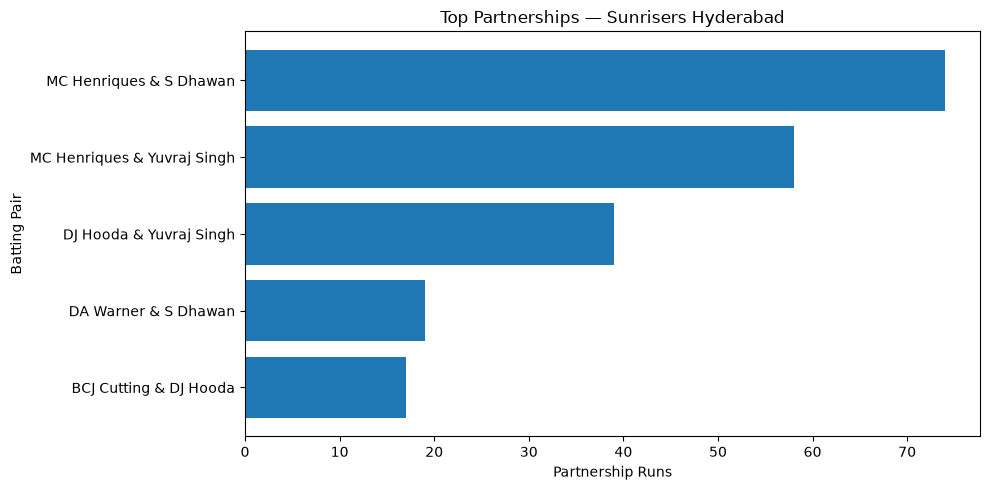

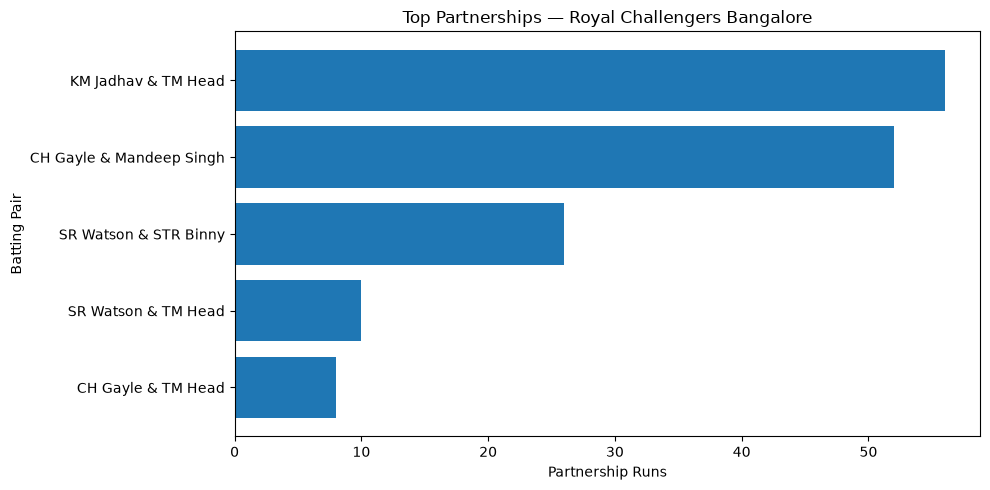

In [49]:
# Visualize the top partnerships in each innings

import matplotlib.pyplot as plt

for innings_number, group in partnership_df.groupby("innings"):
    top_partnerships = group.nlargest(5, "partnership_runs").sort_values(
        "partnership_runs"
    )

    plt.figure(figsize=(10, 5))
    plt.barh(
        top_partnerships["batters"],
        top_partnerships["partnership_runs"]
    )

    plt.title(f"Top Partnerships — {top_partnerships['team'].iloc[0]}")
    plt.xlabel("Partnership Runs")
    plt.ylabel("Batting Pair")
    plt.tight_layout()
    plt.show()

In [50]:
# Inspect metadata available across the dataset

print("Match metadata fields:")
print(sorted(match_data["info"].keys()))

print("\nSample match outcome:")
print(match_data["info"].get("outcome"))

print("\nSample match dates:")
print(match_data["info"].get("dates"))

Match metadata fields:
['balls_per_over', 'city', 'competition', 'dates', 'gender', 'match_type', 'outcome', 'overs', 'player_of_match', 'players', 'registry', 'team_type', 'teams', 'toss', 'umpires', 'venue']

Sample match outcome:
{'by': {'runs': 35}, 'winner': 'Sunrisers Hyderabad'}

Sample match dates:
[datetime.date(2017, 4, 5)]


In [51]:
# Build a match-level dataset from all Cricsheet YAML files

import yaml
import pandas as pd
from pathlib import Path

match_rows = []

for file_path in (PROJECT_ROOT / "data" / "raw").glob("*.yaml"):
    with open(file_path, "r", encoding="utf-8") as file:
        data = yaml.safe_load(file)

    info = data["info"]
    outcome = info.get("outcome", {})
    victory = outcome.get("by", {})

    match_rows.append({
        "match_id": file_path.stem,
        "date": info["dates"][0],
        "season": info["dates"][0].year,
        "team1": info["teams"][0],
        "team2": info["teams"][1],
        "venue": info.get("venue"),
        "city": info.get("city"),
        "toss_winner": info.get("toss", {}).get("winner"),
        "toss_decision": info.get("toss", {}).get("decision"),
        "winner": outcome.get("winner"),
        "win_by_runs": victory.get("runs", 0),
        "win_by_wickets": victory.get("wickets", 0),
        "player_of_match": ", ".join(info.get("player_of_match", []))
    })

matches_df = pd.DataFrame(match_rows)

print("Dataset shape:", matches_df.shape)
display(matches_df.head())

AttributeError: 'str' object has no attribute 'year'

In [52]:
# Build a match-level dataset from all Cricsheet YAML files

match_rows = []

for file_path in (PROJECT_ROOT / "data" / "raw").glob("*.yaml"):
    with open(file_path, "r", encoding="utf-8") as file:
        data = yaml.safe_load(file)

    info = data["info"]
    outcome = info.get("outcome", {})
    victory = outcome.get("by", {})

    match_date = pd.to_datetime(info["dates"][0])

    match_rows.append({
        "match_id": file_path.stem,
        "date": match_date,
        "season": match_date.year,
        "team1": info["teams"][0],
        "team2": info["teams"][1],
        "venue": info.get("venue"),
        "city": info.get("city"),
        "toss_winner": info.get("toss", {}).get("winner"),
        "toss_decision": info.get("toss", {}).get("decision"),
        "winner": outcome.get("winner"),
        "win_by_runs": victory.get("runs", 0),
        "win_by_wickets": victory.get("wickets", 0),
        "player_of_match": ", ".join(info.get("player_of_match", []))
    })

matches_df = pd.DataFrame(match_rows)

print("Dataset shape:", matches_df.shape)
display(matches_df.head())

Dataset shape: (1243, 13)


,match_id,date,season,team1,team2,venue,city,toss_winner,toss_decision,winner,win_by_runs,win_by_wickets,player_of_match
0,1082591,2017-04-05,2017,Sunrisers Hyderabad,Royal Challengers Bangalore,"Rajiv Gandhi International Stadium, Uppal",Hyderabad,Royal Challengers Bangalore,field,Sunrisers Hyderabad,35,0,Yuvraj Singh
1,1082592,2017-04-06,2017,Rising Pune Supergiant,Mumbai Indians,Maharashtra Cricket Association Stadium,Pune,Rising Pune Supergiant,field,Rising Pune Supergiant,0,7,SPD Smith
2,1082593,2017-04-07,2017,Gujarat Lions,Kolkata Knight Riders,Saurashtra Cricket Association Stadium,Rajkot,Kolkata Knight Riders,field,Kolkata Knight Riders,0,10,CA Lynn
3,1082594,2017-04-08,2017,Kings XI Punjab,Rising Pune Supergiant,Holkar Cricket Stadium,Indore,Kings XI Punjab,field,Kings XI Punjab,0,6,GJ Maxwell
4,1082595,2017-04-08,2017,Royal Challengers Bangalore,Delhi Daredevils,M.Chinnaswamy Stadium,Bengaluru,Royal Challengers Bangalore,bat,Royal Challengers Bangalore,15,0,KM Jadhav


In [53]:
# Season-level match analysis

season_summary = (
    matches_df.groupby("season")
    .agg(
        matches=("match_id", "count"),
        distinct_teams=("team1", lambda x: x.nunique()),
        matches_with_winner=("winner", "count")
    )
    .reset_index()
)

season_summary["matches_without_winner"] = (
    season_summary["matches"] - season_summary["matches_with_winner"]
)

display(season_summary)

,season,matches,distinct_teams,matches_with_winner,matches_without_winner
0,2008,58,8,58,0
1,2009,57,7,56,1
2,2010,60,8,59,1
3,2011,73,10,72,1
4,2012,74,9,74,0
5,2013,76,9,74,2
6,2014,60,8,59,1
7,2015,59,8,56,3
8,2016,60,8,60,0
9,2017,59,8,58,1


In [54]:
# Team wins across all seasons

team_wins = (
    matches_df[matches_df["winner"].notna()]
    .groupby("winner")
    .size()
    .reset_index(name="wins")
    .sort_values("wins", ascending=False)
    .reset_index(drop=True)
)

display(team_wins)

,winner,wins
0,Mumbai Indians,155
1,Chennai Super Kings,148
2,Kolkata Knight Riders,140
3,Rajasthan Royals,123
4,Royal Challengers Bangalore,114
5,Sunrisers Hyderabad,102
6,Kings XI Punjab,85
7,Delhi Daredevils,67
8,Delhi Capitals,58
9,Gujarat Titans,47


In [55]:
# Team win percentage

all_teams = pd.concat([
    matches_df[["team1"]].rename(columns={"team1": "team"}),
    matches_df[["team2"]].rename(columns={"team2": "team"})
])

matches_played = (
    all_teams.groupby("team")
    .size()
    .reset_index(name="matches_played")
)

wins = (
    matches_df[matches_df["winner"].notna()]
    .groupby("winner")
    .size()
    .reset_index(name="wins")
    .rename(columns={"winner": "team"})
)

team_win_rate = matches_played.merge(wins, on="team", how="left")
team_win_rate["wins"] = team_win_rate["wins"].fillna(0).astype(int)

team_win_rate["win_percentage"] = (
    team_win_rate["wins"] / team_win_rate["matches_played"] * 100
).round(2)

team_win_rate = team_win_rate.sort_values(
    "win_percentage", ascending=False
).reset_index(drop=True)

display(team_win_rate)

,team,matches_played,wins,win_percentage
0,Royal Challengers Bengaluru,46,29,63.04
1,Rising Pune Supergiant,16,10,62.50
2,Gujarat Titans,77,47,61.04
3,Chennai Super Kings,266,148,55.64
4,Mumbai Indians,291,155,53.26
5,Kolkata Knight Riders,278,140,50.36
6,Rajasthan Royals,251,123,49.00
7,Sunrisers Hyderabad,211,102,48.34
8,Delhi Capitals,120,58,48.33
9,Royal Challengers Bangalore,240,114,47.50


In [56]:
# Inspect competitions and match types in the raw YAML files

competition_rows = []

for file_path in (PROJECT_ROOT / "data" / "raw").glob("*.yaml"):
    with open(file_path, "r", encoding="utf-8") as file:
        data = yaml.safe_load(file)

    info = data["info"]
    competition = info.get("competition", {})

    competition_rows.append({
        "match_id": file_path.stem,
        "competition": competition.get("name") if isinstance(competition, dict) else None,
        "official_season": info.get("season"),
        "match_type": info.get("match_type")
    })

competition_df = pd.DataFrame(competition_rows)

display(
    competition_df.groupby(
        ["competition", "match_type"], dropna=False
    ).size().reset_index(name="matches")
    .sort_values("matches", ascending=False)
)

,competition,match_type,matches
0,NaN,T20,1243


In [57]:
# Inspect metadata fields and season values across raw matches

metadata_rows = []

for file_path in (PROJECT_ROOT / "data" / "raw").glob("*.yaml"):
    with open(file_path, "r", encoding="utf-8") as file:
        data = yaml.safe_load(file)

    info = data["info"]

    metadata_rows.append({
        "match_id": file_path.stem,
        "info_keys": tuple(sorted(info.keys())),
        "season": str(info.get("season")),
        "teams": " vs ".join(info.get("teams", [])),
        "dates": str(info.get("dates", []))
    })

metadata_df = pd.DataFrame(metadata_rows)

print("Metadata key combinations:")
display(
    metadata_df["info_keys"]
    .value_counts()
    .rename_axis("info_keys")
    .reset_index(name="matches")
)

print("Season values:")
display(
    metadata_df["season"]
    .value_counts(dropna=False)
    .sort_index()
    .rename_axis("season")
    .reset_index(name="matches")
)

print("Sample match metadata:")
display(metadata_df.head(10))

Metadata key combinations:


,info_keys,matches
0,"(balls_per_over, city, competition, dates, gen...",1119
1,"(balls_per_over, city, competition, dates, gen...",64
2,"(balls_per_over, competition, dates, gender, m...",38
3,"(balls_per_over, competition, dates, gender, m...",13
4,"(balls_per_over, city, competition, dates, gen...",9


Season values:


,season,matches
0,None,1243


Sample match metadata:


,match_id,info_keys,season,teams,dates
0,1082591,"(balls_per_over, city, competition, dates, gen...",None,Sunrisers Hyderabad vs Royal Challengers Banga...,"[datetime.date(2017, 4, 5)]"
1,1082592,"(balls_per_over, city, competition, dates, gen...",None,Rising Pune Supergiant vs Mumbai Indians,"[datetime.date(2017, 4, 6)]"
2,1082593,"(balls_per_over, city, competition, dates, gen...",None,Gujarat Lions vs Kolkata Knight Riders,['2017-04-07']
3,1082594,"(balls_per_over, city, competition, dates, gen...",None,Kings XI Punjab vs Rising Pune Supergiant,"[datetime.date(2017, 4, 8)]"
4,1082595,"(balls_per_over, city, competition, dates, gen...",None,Royal Challengers Bangalore vs Delhi Daredevils,['2017-04-08']
5,1082596,"(balls_per_over, city, competition, dates, gen...",None,Sunrisers Hyderabad vs Gujarat Lions,"[datetime.date(2017, 4, 9)]"
6,1082597,"(balls_per_over, city, competition, dates, gen...",None,Mumbai Indians vs Kolkata Knight Riders,"[datetime.date(2017, 4, 9)]"
7,1082598,"(balls_per_over, city, competition, dates, gen...",None,Kings XI Punjab vs Royal Challengers Bangalore,"[datetime.date(2017, 4, 10)]"
8,1082599,"(balls_per_over, city, competition, dates, gen...",None,Rising Pune Supergiant vs Delhi Daredevils,"[datetime.date(2017, 4, 11)]"
9,1082600,"(balls_per_over, city, competition, dates, gen...",None,Mumbai Indians vs Sunrisers Hyderabad,"[datetime.date(2017, 4, 12)]"


In [60]:
# Season-wise match summary using existing matches_df

season_summary = (
    matches_df.groupby("season")
    .agg(
        matches=("match_id", "count"),
        matches_with_winner=("winner", "count")
    )
    .reset_index()
)

season_summary["matches_without_winner"] = (
    season_summary["matches"] - season_summary["matches_with_winner"]
)

display(season_summary)

,season,matches,matches_with_winner,matches_without_winner
0,2008,58,58,0
1,2009,57,56,1
2,2010,60,59,1
3,2011,73,72,1
4,2012,74,74,0
5,2013,76,74,2
6,2014,60,59,1
7,2015,59,56,3
8,2016,60,60,0
9,2017,59,58,1


In [61]:
# Validate team names and match outcomes

print("Unique team names:", pd.unique(
    pd.concat([matches_df["team1"], matches_df["team2"]])
).size)

print("Missing team names:")
display(matches_df[["team1", "team2"]].isna().sum())

print("Matches where winner is not one of the participating teams:")
invalid_winners = matches_df[
    matches_df["winner"].notna()
    & ~(
        (matches_df["winner"] == matches_df["team1"])
        | (matches_df["winner"] == matches_df["team2"])
    )
]

display(invalid_winners[["match_id", "team1", "team2", "winner"]])

print("Duplicate match IDs:", matches_df["match_id"].duplicated().sum())

Unique team names: 19
Missing team names:


team1    0
team2    0
dtype: int64

Matches where winner is not one of the participating teams:


,match_id,team1,team2,winner


Duplicate match IDs: 0


In [62]:
# Team performance summary

teams_long = pd.concat([
    matches_df[["team1"]].rename(columns={"team1": "team"}),
    matches_df[["team2"]].rename(columns={"team2": "team"})
])

matches_played = (
    teams_long.groupby("team")
    .size()
    .rename("matches_played")
)

wins = (
    matches_df[matches_df["winner"].notna()]
    .groupby("winner")
    .size()
    .rename("wins")
)

team_summary = pd.concat([matches_played, wins], axis=1).fillna(0)
team_summary["wins"] = team_summary["wins"].astype(int)
team_summary["win_percentage"] = (
    team_summary["wins"] / team_summary["matches_played"] * 100
).round(2)

team_summary = (
    team_summary.sort_values("wins", ascending=False)
    .reset_index(names="team")
)

display(team_summary)

,team,matches_played,wins,win_percentage
0,Mumbai Indians,291,155,53.26
1,Chennai Super Kings,266,148,55.64
2,Kolkata Knight Riders,278,140,50.36
3,Rajasthan Royals,251,123,49.00
4,Royal Challengers Bangalore,240,114,47.50
5,Sunrisers Hyderabad,211,102,48.34
6,Kings XI Punjab,190,85,44.74
7,Delhi Daredevils,161,67,41.61
8,Delhi Capitals,120,58,48.33
9,Gujarat Titans,77,47,61.04


In [63]:
# Toss impact analysis

toss_df = matches_df.dropna(
    subset=["toss_winner", "winner", "toss_decision"]
).copy()

toss_df["toss_winner_won_match"] = (
    toss_df["toss_winner"] == toss_df["winner"]
)

print("Toss winner vs match winner:")
display(
    toss_df["toss_winner_won_match"]
    .value_counts()
    .rename(index={True: "Toss winner also won", False: "Toss winner lost"})
    .rename_axis("result")
    .reset_index(name="matches")
    .assign(
        percentage=lambda x: (
            x["matches"] / x["matches"].sum() * 100
        ).round(2)
    )
)

print("Match outcomes by toss decision:")
display(
    toss_df.groupby("toss_decision")
    .agg(
        matches=("match_id", "count"),
        toss_winner_match_wins=("toss_winner_won_match", "sum")
    )
    .assign(
        win_percentage=lambda x: (
            x["toss_winner_match_wins"] / x["matches"] * 100
        ).round(2)
    )
    .reset_index()
)

Toss winner vs match winner:


,result,matches,percentage
0,Toss winner also won,628,51.56
1,Toss winner lost,590,48.44


Match outcomes by toss decision:


,toss_decision,matches,toss_winner_match_wins,win_percentage
0,bat,408,185,45.34
1,field,810,443,54.69


In [64]:
# Toss decision vs match outcome

toss_decision_summary = (
    toss_df.groupby("toss_decision")
    .agg(
        matches=("match_id", "count"),
        toss_winner_wins=("toss_winner_won_match", "sum")
    )
    .reset_index()
)

toss_decision_summary["toss_winner_win_pct"] = (
    toss_decision_summary["toss_winner_wins"]
    / toss_decision_summary["matches"] * 100
).round(2)

display(toss_decision_summary)

,toss_decision,matches,toss_winner_wins,toss_winner_win_pct
0,bat,408,185,45.34
1,field,810,443,54.69


In [65]:
# Match win rate by toss decision

decision_outcomes = (
    toss_df.assign(
        toss_winner_won_match=toss_df["toss_winner"] == toss_df["winner"]
    )
    .groupby("toss_decision")
    .agg(
        matches=("match_id", "count"),
        toss_winner_wins=("toss_winner_won_match", "sum")
    )
    .reset_index()
)

decision_outcomes["toss_winner_losses"] = (
    decision_outcomes["matches"] - decision_outcomes["toss_winner_wins"]
)

decision_outcomes["toss_winner_win_pct"] = (
    decision_outcomes["toss_winner_wins"]
    / decision_outcomes["matches"] * 100
).round(2)

display(decision_outcomes)

,toss_decision,matches,toss_winner_wins,toss_winner_losses,toss_winner_win_pct
0,bat,408,185,223,45.34
1,field,810,443,367,54.69


In [66]:
# Venue analysis: match counts and average first-innings score

venue_matches = (
    matches_df.groupby("venue")
    .agg(matches=("match_id", "nunique"))
    .reset_index()
)

first_innings_scores = []

for file_path in (PROJECT_ROOT / "data" / "raw").glob("*.yaml"):
    with open(file_path, "r", encoding="utf-8") as file:
        data = yaml.safe_load(file)

    innings_list = data.get("innings", [])

    if innings_list:
        innings_data = next(iter(innings_list[0].values()))
        total = sum(
            delivery_data["runs"]["total"]
            for delivery in innings_data.get("deliveries", [])
            for delivery_data in delivery.values()
        )

        first_innings_scores.append({
            "match_id": file_path.stem,
            "first_innings_score": total
        })

first_scores_df = pd.DataFrame(first_innings_scores)

venue_scores = matches_df[["match_id", "venue"]].merge(
    first_scores_df, on="match_id", how="left"
)

venue_summary = (
    venue_scores.groupby("venue")
    .agg(
        matches=("match_id", "nunique"),
        avg_first_innings_score=("first_innings_score", "mean")
    )
    .reset_index()
)

venue_summary["avg_first_innings_score"] = (
    venue_summary["avg_first_innings_score"].round(2)
)

display(
    venue_summary.sort_values("matches", ascending=False).head(20)
)

,venue,matches,avg_first_innings_score
14,Eden Gardens,77,160.18
57,Wankhede Stadium,73,166.03
23,M Chinnaswamy Stadium,65,168.06
16,Feroz Shah Kotla,60,161.63
58,"Wankhede Stadium, Mumbai",59,181.92
43,"Rajiv Gandhi International Stadium, Uppal",49,156.14
27,"MA Chidambaram Stadium, Chepauk",48,166.02
47,Sawai Mansingh Stadium,47,157.68
13,Dubai International Cricket Stadium,46,163.76
33,"Narendra Modi Stadium, Ahmedabad",41,185.80


In [67]:
# Season-wise scoring trends

season_scores = matches_df[["match_id", "season"]].merge(
    first_scores_df,
    on="match_id",
    how="left"
)

season_summary = (
    season_scores.groupby("season")
    .agg(
        matches=("match_id", "nunique"),
        avg_first_innings_score=("first_innings_score", "mean"),
        median_first_innings_score=("first_innings_score", "median"),
        highest_first_innings_score=("first_innings_score", "max")
    )
    .round(2)
    .reset_index()
)

display(season_summary)

,season,matches,avg_first_innings_score,median_first_innings_score,highest_first_innings_score
0,2008,58,160.97,160.0,240
1,2009,57,150.26,149.0,211
2,2010,60,164.78,169.0,246
3,2011,73,152.37,156.0,232
4,2012,74,157.54,159.0,222
5,2013,76,155.89,158.0,263
6,2014,60,163.07,160.0,231
7,2015,59,166.25,167.0,235
8,2016,60,162.60,162.0,248
9,2017,59,165.78,163.0,230


In [68]:
# IPL batting leaderboard

batting_rows = []

for file_path in (PROJECT_ROOT / "data" / "raw").glob("*.yaml"):
    with open(file_path, "r", encoding="utf-8") as file:
        data = yaml.safe_load(file)

    for innings_item in data.get("innings", []):
        innings_name, innings_data = next(iter(innings_item.items()))

        for delivery_item in innings_data.get("deliveries", []):
            delivery = next(iter(delivery_item.values()))
            batter = delivery.get("batsman")
            runs = delivery.get("runs", {})
            batter_runs = runs.get("batsman", 0)
            extras = delivery.get("extras", {})

            # Balls faced exclude wides and no-balls
            legal_for_batter = not (
                "wides" in extras or "noballs" in extras
            )

            batting_rows.append({
                "batter": batter,
                "runs": batter_runs,
                "ball_faced": int(legal_for_batter),
                "fours": int(batter_runs == 4),
                "sixes": int(batter_runs == 6)
            })

batting_df = pd.DataFrame(batting_rows)

batting_summary = (
    batting_df.groupby("batter")
    .agg(
        runs=("runs", "sum"),
        balls_faced=("ball_faced", "sum"),
        fours=("fours", "sum"),
        sixes=("sixes", "sum")
    )
    .reset_index()
)

batting_summary["strike_rate"] = (
    batting_summary["runs"] / batting_summary["balls_faced"] * 100
).round(2)

batting_summary["boundary_runs"] = (
    batting_summary["fours"] * 4 + batting_summary["sixes"] * 6
)

batting_summary["boundary_percentage"] = (
    batting_summary["boundary_runs"] / batting_summary["runs"] * 100
).round(2)

display(
    batting_summary.sort_values("runs", ascending=False).head(20)
)

,batter,runs,balls_faced,fours,sixes,strike_rate,boundary_runs,boundary_percentage
694,V Kohli,9346,6911,847,317,135.23,5290,56.60
527,RG Sharma,7331,5496,661,324,133.39,4588,62.58
564,S Dhawan,6769,5304,768,153,127.62,3990,58.95
159,DA Warner,6567,4680,663,236,140.32,4068,61.95
311,KL Rahul,5828,4175,509,239,139.59,3470,59.54
598,SK Raina,5536,4025,506,204,137.54,3248,58.67
409,MS Dhoni,5439,3935,375,264,138.22,3084,56.70
52,AM Rahane,5367,4269,540,141,125.72,3006,56.01
628,SV Samson,5181,3653,432,243,141.83,3186,61.49
31,AB de Villiers,5181,3400,414,253,152.38,3174,61.26


In [69]:
# IPL bowling leaderboard

bowling_rows = []

NON_BOWLER_WICKETS = {
    "run out",
    "retired hurt",
    "obstructing the field",
    "retired out"
}

for file_path in (PROJECT_ROOT / "data" / "raw").glob("*.yaml"):
    with open(file_path, "r", encoding="utf-8") as file:
        data = yaml.safe_load(file)

    for innings_item in data.get("innings", []):
        innings_data = next(iter(innings_item.values()))

        for delivery_item in innings_data.get("deliveries", []):
            delivery = next(iter(delivery_item.values()))
            extras = delivery.get("extras", {})
            runs = delivery.get("runs", {})

            wickets = delivery.get("wickets", [])
            bowler_wickets = sum(
                wicket.get("kind") not in NON_BOWLER_WICKETS
                for wicket in wickets
            )

            # Bowler-conceded runs exclude byes and leg-byes
            conceded = (
                runs.get("total", 0)
                - extras.get("byes", 0)
                - extras.get("legbyes", 0)
            )

            # Wides and no-balls do not count as legal balls
            legal_ball = not (
                "wides" in extras or "noballs" in extras
            )

            bowling_rows.append({
                "bowler": delivery.get("bowler"),
                "runs_conceded": conceded,
                "legal_balls": int(legal_ball),
                "wickets": bowler_wickets
            })

bowling_df = pd.DataFrame(bowling_rows)

bowling_summary = (
    bowling_df.groupby("bowler")
    .agg(
        runs_conceded=("runs_conceded", "sum"),
        legal_balls=("legal_balls", "sum"),
        wickets=("wickets", "sum")
    )
    .reset_index()
)

bowling_summary["overs"] = (
    bowling_summary["legal_balls"] // 6
    + (bowling_summary["legal_balls"] % 6) / 10
).round(1)

bowling_summary["economy"] = (
    bowling_summary["runs_conceded"] * 6
    / bowling_summary["legal_balls"].replace(0, pd.NA)
).round(2)

display(
    bowling_summary.sort_values(
        ["wickets", "economy"], ascending=[False, True]
    ).head(20)
)

,bowler,runs_conceded,legal_balls,wickets,overs,economy
24,AC Gilchrist,0,1,0,0.1,0.00
396,R Ravindra,7,12,0,2.0,3.50
343,NB Singh,15,24,0,4.0,3.75
497,Sachin Baby,8,10,0,1.4,4.80
39,AM Rahane,5,6,0,1.0,5.00
137,DJ Thornely,40,42,0,7.0,5.71
268,LA Carseldine,6,6,0,1.0,6.00
283,M Manhas,42,42,0,7.0,6.00
490,SS Mundhe,6,6,0,1.0,6.00
306,MJ Clarke,67,66,0,11.0,6.09


In [70]:
sample_path = next((PROJECT_ROOT / "data" / "raw").glob("*.yaml"))

with open(sample_path, "r", encoding="utf-8") as f:
    sample_data = yaml.safe_load(f)

sample_innings = next(iter(sample_data["innings"][0].values()))
sample_delivery = next(iter(sample_innings["deliveries"][0].values()))

print("Delivery keys:", sample_delivery.keys())
print("wicket:", sample_delivery.get("wicket"))

Delivery keys: dict_keys(['actual_delivery', 'batsman', 'bowler', 'non_striker', 'runs'])
wicket: None


In [71]:
for file_path in (PROJECT_ROOT / "data" / "raw").glob("*.yaml"):
    with open(file_path, "r", encoding="utf-8") as f:
        data = yaml.safe_load(f)

    found = False

    for innings_item in data.get("innings", []):
        innings_data = next(iter(innings_item.values()))

        for delivery_item in innings_data.get("deliveries", []):
            delivery = next(iter(delivery_item.values()))

            if "wicket" in delivery or "wickets" in delivery:
                print("File:", file_path.name)
                print("Delivery keys:", delivery.keys())
                print("Wicket:", delivery.get("wicket"))
                print("Wickets:", delivery.get("wickets"))
                found = True
                break

        if found:
            break

    if found:
        break

File: 1082591.yaml
Delivery keys: dict_keys(['actual_delivery', 'batsman', 'bowler', 'non_striker', 'runs', 'wicket'])
Wicket: {'fielders': ['Mandeep Singh'], 'kind': 'caught', 'player_out': 'DA Warner'}
Wickets: None


In [72]:
# IPL bowling leaderboard — corrected wicket extraction

bowling_rows = []

NON_BOWLER_WICKETS = {
    "run out",
    "retired hurt",
    "obstructing the field",
    "retired out"
}

for file_path in (PROJECT_ROOT / "data" / "raw").glob("*.yaml"):
    with open(file_path, "r", encoding="utf-8") as f:
        data = yaml.safe_load(f)

    for innings_item in data.get("innings", []):
        innings_data = next(iter(innings_item.values()))

        for delivery_item in innings_data.get("deliveries", []):
            delivery = next(iter(delivery_item.values()))
            extras = delivery.get("extras", {})
            runs = delivery.get("runs", {})

            wicket = delivery.get("wicket")
            bowler_wickets = int(
                wicket is not None
                and wicket.get("kind", "").lower() not in NON_BOWLER_WICKETS
            )

            conceded = (
                runs.get("total", 0)
                - extras.get("byes", 0)
                - extras.get("legbyes", 0)
            )

            legal_ball = not (
                "wides" in extras or "noballs" in extras
            )

            bowling_rows.append({
                "bowler": delivery.get("bowler"),
                "runs_conceded": conceded,
                "legal_balls": int(legal_ball),
                "wickets": bowler_wickets
            })

bowling_df = pd.DataFrame(bowling_rows)

bowling_summary = (
    bowling_df.groupby("bowler")
    .agg(
        runs_conceded=("runs_conceded", "sum"),
        legal_balls=("legal_balls", "sum"),
        wickets=("wickets", "sum")
    )
    .reset_index()
)

bowling_summary["overs"] = (
    bowling_summary["legal_balls"] // 6
    + (bowling_summary["legal_balls"] % 6) / 10
).round(1)

bowling_summary["economy"] = (
    bowling_summary["runs_conceded"] * 6
    / bowling_summary["legal_balls"].replace(0, pd.NA)
).round(2)

display(
    bowling_summary
    .sort_values(["wickets", "economy"], ascending=[False, True])
    .head(20)
)

,bowler,runs_conceded,legal_balls,wickets,overs,economy
570,YS Chahal,5417,4037,233,672.5,8.05
76,B Kumar,5913,4600,226,766.4,7.71
481,SP Narine,5273,4660,209,776.4,6.79
375,PP Chawla,5108,3850,192,641.4,7.96
214,JJ Bumrah,4469,3653,190,608.5,7.34
387,R Ashwin,5652,4710,187,785.0,7.20
131,DJ Bravo,4360,3120,183,520.0,8.38
406,RA Jadeja,5465,4254,180,709.0,7.71
433,Rashid Khan,4297,3543,179,590.3,7.28
8,A Mishra,4145,3371,174,561.5,7.38


In [73]:
# Inspect the existing single-match delivery structure
print(deliveries_df.columns.tolist())
display(deliveries_df.head())

['innings', 'delivery', 'batter', 'bowler', 'batter_runs', 'extras_runs', 'total_runs', 'wicket']


,innings,delivery,batter,bowler,batter_runs,extras_runs,total_runs,wicket
0,1,0.1,DA Warner,TS Mills,0,0,0,False
1,1,0.2,DA Warner,TS Mills,0,0,0,False
2,1,0.3,DA Warner,TS Mills,4,0,4,False
3,1,0.4,DA Warner,TS Mills,0,0,0,False
4,1,0.5,DA Warner,TS Mills,0,2,2,False


In [74]:
# Add over number and match phase

deliveries_df["over_number"] = deliveries_df["delivery"].astype(int) + 1

deliveries_df["phase"] = pd.cut(
    deliveries_df["over_number"],
    bins=[0, 6, 15, 20],
    labels=["Powerplay", "Middle", "Death"]
)

display(
    deliveries_df[
        ["innings", "delivery", "over_number", "phase",
         "total_runs", "wicket"]
    ].head(10)
)

,innings,delivery,over_number,phase,total_runs,wicket
0,1,0.1,1,Powerplay,0,False
1,1,0.2,1,Powerplay,0,False
2,1,0.3,1,Powerplay,4,False
3,1,0.4,1,Powerplay,0,False
4,1,0.5,1,Powerplay,2,False
5,1,0.6,1,Powerplay,0,False
6,1,0.7,1,Powerplay,1,False
7,1,1.1,2,Powerplay,1,False
8,1,1.2,2,Powerplay,4,False
9,1,1.3,2,Powerplay,1,False


In [75]:
phase_summary = (
    deliveries_df.groupby(["innings", "phase"], observed=True)
    .agg(
        runs=("total_runs", "sum"),
        wickets=("wicket", "sum"),
        deliveries=("total_runs", "size")
    )
    .reset_index()
)

phase_summary["runs_per_delivery"] = (
    phase_summary["runs"] / phase_summary["deliveries"]
).round(3)

display(phase_summary)

,innings,phase,runs,wickets,deliveries,runs_per_delivery
0,1,Powerplay,59,1,38,1.553
1,1,Middle,92,1,55,1.673
2,1,Death,56,2,32,1.750
3,2,Powerplay,54,1,38,1.421
4,2,Middle,85,4,57,1.491
5,2,Death,33,5,28,1.179


In [76]:
print(deliveries_df.columns.tolist())

['innings', 'delivery', 'batter', 'bowler', 'batter_runs', 'extras_runs', 'total_runs', 'wicket', 'over_number', 'phase']


In [78]:
# Fix over number and match phase

deliveries_df["over_number"] = (
    deliveries_df["delivery"].astype(str).str.split(".").str[0].astype(int) + 1
)

deliveries_df["phase"] = pd.cut(
    deliveries_df["over_number"],
    bins=[0, 6, 15, 20],
    labels=["Powerplay", "Middle", "Death"]
)

deliveries_df["legal_ball"] = (
    (deliveries_df["wides"] == 0)
    & (deliveries_df["noballs"] == 0)
)

display(
    deliveries_df[
        ["delivery", "over_number", "phase", "wides", "noballs", "legal_ball"]
    ].head(10)
)

,delivery,over_number,phase,wides,noballs,legal_ball
0,0.1,1,Powerplay,0,0,True
1,0.2,1,Powerplay,0,0,True
2,0.3,1,Powerplay,0,0,True
3,0.4,1,Powerplay,0,0,True
4,0.5,1,Powerplay,2,0,False
5,0.5,1,Powerplay,0,0,True
6,0.6,1,Powerplay,0,0,True
7,1.1,2,Powerplay,0,0,True
8,1.2,2,Powerplay,0,0,True
9,1.3,2,Powerplay,0,1,False


In [79]:
phase_summary = (
    deliveries_df.groupby(["innings", "phase"], observed=True)
    .agg(
        runs=("total_runs", "sum"),
        wickets=("wicket", "sum"),
        legal_balls=("legal_ball", "sum")
    )
    .reset_index()
)

phase_summary["overs"] = (
    phase_summary["legal_balls"] / 6
).round(2)

phase_summary["run_rate"] = (
    phase_summary["runs"] * 6
    / phase_summary["legal_balls"].replace(0, pd.NA)
).round(2)

display(phase_summary)

,innings,phase,runs,wickets,legal_balls,overs,run_rate
0,1,Powerplay,59,1,36,6.00,9.83
1,1,Middle,92,1,54,9.00,10.22
2,1,Death,56,2,30,5.00,11.20
3,2,Powerplay,54,1,36,6.00,9.00
4,2,Middle,85,4,54,9.00,9.44
5,2,Death,33,5,28,4.67,7.07


In [80]:
# Prepare IPL-wide phase analysis

phase_rows = []

for file_path in (PROJECT_ROOT / "data" / "raw").glob("*.yaml"):
    with open(file_path, "r", encoding="utf-8") as f:
        data = yaml.safe_load(f)

    match_id = file_path.stem

    for innings_num, innings_item in enumerate(data.get("innings", []), start=1):
        innings_data = next(iter(innings_item.values()))
        batting_team = innings_data.get("team")

        for delivery_item in innings_data.get("deliveries", []):
            delivery = next(iter(delivery_item.values()))
            extras = delivery.get("extras", {})
            runs = delivery.get("runs", {})
            ball_label = str(delivery["actual_delivery"])
            over_number = int(ball_label.split(".")[0]) + 1

            phase = (
                "Powerplay" if over_number <= 6
                else "Middle" if over_number <= 15
                else "Death" if over_number <= 20
                else "Super Over"
            )

            phase_rows.append({
                "match_id": match_id,
                "innings": innings_num,
                "batting_team": batting_team,
                "over_number": over_number,
                "phase": phase,
                "runs": runs.get("total", 0),
                "legal_ball": int(
                    "wides" not in extras and "noballs" not in extras
                ),
                "wicket": int("wicket" in delivery)
            })

phase_df = pd.DataFrame(phase_rows)

print("Delivery records:", len(phase_df))
print("Matches:", phase_df["match_id"].nunique())
display(phase_df.head())

Delivery records: 295732
Matches: 1243


,match_id,innings,batting_team,over_number,phase,runs,legal_ball,wicket
0,1082591,1,Sunrisers Hyderabad,1,Powerplay,0,1,0
1,1082591,1,Sunrisers Hyderabad,1,Powerplay,0,1,0
2,1082591,1,Sunrisers Hyderabad,1,Powerplay,4,1,0
3,1082591,1,Sunrisers Hyderabad,1,Powerplay,0,1,0
4,1082591,1,Sunrisers Hyderabad,1,Powerplay,2,0,0


In [81]:
# IPL-wide phase summary

ipl_phase_summary = (
    phase_df[phase_df["phase"].isin(["Powerplay", "Middle", "Death"])]
    .groupby("phase", observed=True)
    .agg(
        runs=("runs", "sum"),
        legal_balls=("legal_ball", "sum"),
        wickets=("wicket", "sum"),
        delivery_records=("runs", "size")
    )
    .reindex(["Powerplay", "Middle", "Death"])
    .reset_index()
)

ipl_phase_summary["overs_equivalent"] = (
    ipl_phase_summary["legal_balls"] / 6
).round(1)

ipl_phase_summary["run_rate"] = (
    ipl_phase_summary["runs"] * 6
    / ipl_phase_summary["legal_balls"].replace(0, pd.NA)
).round(2)

display(ipl_phase_summary)

,phase,runs,legal_balls,wickets,delivery_records,overs_equivalent,run_rate
0,Powerplay,120503,89318,3614,92904,14886.3,8.09
1,Middle,174283,131526,5708,135655,21921.0,7.95
2,Death,106952,63786,5383,67173,10631.0,10.06


In [82]:
# Team-wise scoring rate by match phase

team_phase_summary = (
    phase_df[phase_df["phase"].isin(["Powerplay", "Middle", "Death"])]
    .groupby(["batting_team", "phase"], observed=True)
    .agg(
        runs=("runs", "sum"),
        legal_balls=("legal_ball", "sum"),
        wickets=("wicket", "sum"),
        matches=("match_id", "nunique")
    )
    .reset_index()
)

team_phase_summary["run_rate"] = (
    team_phase_summary["runs"] * 6
    / team_phase_summary["legal_balls"].replace(0, pd.NA)
).round(2)

display(
    team_phase_summary.sort_values(
        ["phase", "run_rate"], ascending=[True, False]
    )
)

,batting_team,phase,runs,legal_balls,wickets,matches,run_rate
51,Royal Challengers Bengaluru,Death,2138,1079,89,42,11.89
36,Punjab Kings,Death,4058,2206,179,83,11.04
15,Gujarat Titans,Death,3660,2036,166,76,10.79
27,Lucknow Super Giants,Death,3448,1962,165,71,10.54
0,Chennai Super Kings,Death,12392,7145,496,259,10.41
30,Mumbai Indians,Death,13238,7636,670,279,10.40
48,Royal Challengers Bangalore,Death,10514,6064,510,224,10.40
45,Rising Pune Supergiants,Death,530,311,27,11,10.23
6,Delhi Capitals,Death,5230,3108,263,117,10.10
24,Kolkata Knight Riders,Death,11156,6690,577,256,10.01


In [83]:
# Compare team scoring rates across all three phases

phase_rate_table = team_phase_summary.pivot(
    index="batting_team",
    columns="phase",
    values="run_rate"
).round(2)

phase_rate_table["overall_run_rate"] = (
    team_phase_summary.groupby("batting_team")["runs"].sum() * 6
    / team_phase_summary.groupby("batting_team")["legal_balls"].sum()
).round(2)

display(
    phase_rate_table.sort_values("Death", ascending=False)
)

phase,Death,Middle,Powerplay,overall_run_rate
batting_team,,,,
Royal Challengers Bengaluru,11.89,9.40,9.99,10.12
Punjab Kings,11.04,8.65,9.14,9.33
Gujarat Titans,10.79,8.80,8.65,9.20
Lucknow Super Giants,10.54,8.62,8.62,9.07
Chennai Super Kings,10.41,7.87,7.90,8.47
Mumbai Indians,10.40,7.91,7.97,8.49
Royal Challengers Bangalore,10.40,7.79,7.60,8.31
Rising Pune Supergiants,10.23,7.61,7.60,8.14
Delhi Capitals,10.10,8.06,8.63,8.70


In [84]:
# Build batter innings scores across all matches

batting_innings_rows = []

for file_path in (PROJECT_ROOT / "data" / "raw").glob("*.yaml"):
    with open(file_path, "r", encoding="utf-8") as f:
        data = yaml.safe_load(f)

    match_id = file_path.stem

    for innings_num, innings_item in enumerate(data.get("innings", []), start=1):
        innings_data = next(iter(innings_item.values()))
        batting_team = innings_data.get("team")
        batter_runs = {}

        for delivery_item in innings_data.get("deliveries", []):
            delivery = next(iter(delivery_item.values()))
            batter = delivery.get("batsman")
            runs = delivery.get("runs", {}).get("batsman", 0)

            batter_runs[batter] = batter_runs.get(batter, 0) + runs

        for batter, runs in batter_runs.items():
            batting_innings_rows.append({
                "match_id": match_id,
                "innings": innings_num,
                "batting_team": batting_team,
                "batter": batter,
                "runs": runs
            })

batting_innings_df = pd.DataFrame(batting_innings_rows)

print("Batter-innings records:", len(batting_innings_df))
display(batting_innings_df.head())

Batter-innings records: 18842


,match_id,innings,batting_team,batter,runs
0,1082591,1,Sunrisers Hyderabad,DA Warner,14
1,1082591,1,Sunrisers Hyderabad,S Dhawan,40
2,1082591,1,Sunrisers Hyderabad,MC Henriques,52
3,1082591,1,Sunrisers Hyderabad,Yuvraj Singh,62
4,1082591,1,Sunrisers Hyderabad,DJ Hooda,16


In [85]:
# Player consistency metrics

player_consistency = (
    batting_innings_df.groupby("batter")
    .agg(
        innings=("runs", "count"),
        total_runs=("runs", "sum"),
        average_runs=("runs", "mean"),
        median_runs=("runs", "median"),
        standard_deviation=("runs", "std"),
        scores_50_plus=("runs", lambda s: (s >= 50).sum()),
        ducks=("runs", lambda s: (s == 0).sum())
    )
    .reset_index()
)

player_consistency = player_consistency[
    player_consistency["innings"] >= 20
].copy()

player_consistency["consistency_cv"] = (
    player_consistency["standard_deviation"]
    / player_consistency["average_runs"].replace(0, pd.NA)
).round(2)

player_consistency["50_plus_percentage"] = (
    player_consistency["scores_50_plus"]
    / player_consistency["innings"] * 100
).round(1)

player_consistency["duck_percentage"] = (
    player_consistency["ducks"]
    / player_consistency["innings"] * 100
).round(1)

display(
    player_consistency.sort_values(
        ["consistency_cv", "average_runs"],
        ascending=[True, False]
    ).head(20)
)

,batter,innings,total_runs,average_runs,median_runs,standard_deviation,scores_50_plus,ducks,consistency_cv,50_plus_percentage,duck_percentage
103,B Sai Sudharsan,57,2515,44.122807,43.0,28.467444,23,1,0.65,40.4,1.8
225,H Klaasen,60,2104,35.066667,32.0,23.636274,15,1,0.67,25.0,1.7
0,A Ashish Reddy,23,280,12.173913,10.0,8.876179,0,0,0.73,0.0,0.0
16,A Raghuvanshi,30,885,29.500000,27.0,21.883311,7,0,0.74,23.3,0.0
501,R Dravid,82,2174,26.512195,25.0,19.519692,11,3,0.74,13.4,3.7
511,R Sathish,24,270,11.250000,9.0,8.424860,0,2,0.75,0.0,8.3
617,SR Tendulkar,78,2334,29.923077,27.5,22.656537,14,4,0.76,17.9,5.1
282,JP Duminy,75,2029,27.053333,21.0,20.466118,14,1,0.76,18.7,1.3
149,D Brevis,24,606,25.250000,27.0,19.065676,2,3,0.76,8.3,12.5
48,AK Markram,67,1671,24.940299,21.0,18.877500,10,4,0.76,14.9,6.0


In [86]:
# Player scoring efficiency: runs, average, strike rate and consistency

player_efficiency = batting_innings_df.groupby("batter").agg(
    innings=("runs", "count"),
    total_runs=("runs", "sum"),
    average_runs=("runs", "mean"),
    median_runs=("runs", "median"),
    score_std=("runs", "std")
).reset_index()

player_efficiency = player_efficiency[
    player_efficiency["innings"] >= 20
].copy()

# Use the existing batting leaderboard for balls faced
player_efficiency = player_efficiency.merge(
    batting_summary[["batter", "balls_faced", "strike_rate"]],
    on="batter",
    how="left"
)

player_efficiency["consistency_cv"] = (
    player_efficiency["score_std"]
    / player_efficiency["average_runs"].replace(0, pd.NA)
).round(2)

display(
    player_efficiency.sort_values(
        ["strike_rate", "average_runs"],
        ascending=False
    ).head(20)
)

,batter,innings,total_runs,average_runs,median_runs,score_std,balls_faced,strike_rate,consistency_cv
226,V Suryavanshi,23,1028,44.695652,40.0,35.134074,447,229.98,0.79
153,Priyansh Arya,31,909,29.322581,22.0,28.244630,469,193.82,0.96
216,TH David,59,1151,19.508475,16.0,15.917213,642,179.28,0.82
9,AD Russell,115,2655,23.086957,16.0,20.607257,1508,176.06,0.89
149,PD Salt,40,1258,31.450000,26.0,27.643286,715,175.94,0.88
19,Abhishek Sharma,89,2379,26.730337,15.0,27.927570,1383,172.02,1.04
23,Ashutosh Sharma,26,564,21.692308,18.0,17.080443,328,171.95,0.79
219,TM Head,52,1556,29.923077,21.5,27.492492,907,171.55,0.92
168,RD Rickelton,26,836,32.153846,24.5,30.524341,495,168.89,0.95
89,K Gowtham,27,247,9.148148,8.0,8.551670,147,168.03,0.93


In [87]:
# Build batter-by-phase performance across all matches

batter_phase_rows = []

for file_path in (PROJECT_ROOT / "data" / "raw").glob("*.yaml"):
    with open(file_path, "r", encoding="utf-8") as f:
        data = yaml.safe_load(f)

    match_id = file_path.stem

    for innings_item in data.get("innings", []):
        innings_data = next(iter(innings_item.values()))

        for delivery_item in innings_data.get("deliveries", []):
            delivery = next(iter(delivery_item.values()))
            ball_label = str(delivery["actual_delivery"])
            over_number = int(ball_label.split(".")[0]) + 1

            if over_number <= 6:
                phase = "Powerplay"
            elif over_number <= 15:
                phase = "Middle"
            elif over_number <= 20:
                phase = "Death"
            else:
                continue

            extras = delivery.get("extras", {})
            batter_runs = delivery.get("runs", {}).get("batsman", 0)

            # A wide is not a ball faced; a no-ball normally is.
            ball_faced = int("wides" not in extras)

            batter_phase_rows.append({
                "match_id": match_id,
                "batter": delivery.get("batsman"),
                "phase": phase,
                "runs": batter_runs,
                "balls_faced": ball_faced
            })

batter_phase_df = pd.DataFrame(batter_phase_rows)

print("Records:", len(batter_phase_df))
display(batter_phase_df.head())

Records: 295732


,match_id,batter,phase,runs,balls_faced
0,1082591,DA Warner,Powerplay,0,1
1,1082591,DA Warner,Powerplay,0,1
2,1082591,DA Warner,Powerplay,4,1
3,1082591,DA Warner,Powerplay,0,1
4,1082591,DA Warner,Powerplay,0,0


In [89]:
# Batter performance by match phase

batter_phase_summary = (
    batter_phase_df
    .groupby(["batter", "phase"])
    .agg(
        runs=("runs", "sum"),
        balls_faced=("balls_faced", "sum"),
        innings=("match_id", "nunique")
    )
    .reset_index()
)

batter_phase_summary["strike_rate"] = (
    100 * batter_phase_summary["runs"]
    / batter_phase_summary["balls_faced"].replace(0, float("nan"))
).round(2)

batter_phase_summary = batter_phase_summary[
    batter_phase_summary["balls_faced"] >= 100
].copy()

display(
    batter_phase_summary
    .sort_values(["phase", "strike_rate"], ascending=[True, False])
    .groupby("phase", group_keys=False)
    .head(10)
    .reset_index(drop=True)
)

,batter,phase,runs,balls_faced,innings,strike_rate
0,AB de Villiers,Death,1868,838,81,222.91
1,LS Livingstone,Death,345,159,20,216.98
2,RM Patidar,Death,267,124,19,215.32
3,B Sai Sudharsan,Death,308,149,19,206.71
4,MA Agarwal,Death,252,122,15,206.56
5,Q de Kock,Death,240,117,14,205.13
6,CH Gayle,Death,581,284,28,204.58
7,RR Pant,Death,1095,540,63,202.78
8,T Stubbs,Death,546,275,29,198.55
9,Tilak Varma,Death,543,274,33,198.18


In [90]:
# Pivot phase strike rates into one row per batter

phase_comparison = batter_phase_summary.pivot(
    index="batter",
    columns="phase",
    values="strike_rate"
).reset_index()

phase_comparison.columns.name = None

# Require at least 100 balls faced in every phase
phase_balls = batter_phase_summary.pivot(
    index="batter",
    columns="phase",
    values="balls_faced"
).reset_index()

phase_balls.columns.name = None

phase_balls = phase_balls.rename(columns={
    "Powerplay": "Powerplay_balls",
    "Middle": "Middle_balls",
    "Death": "Death_balls"
})

phase_comparison = phase_comparison.merge(
    phase_balls,
    on="batter",
    how="inner"
)

phase_comparison = phase_comparison.dropna(
    subset=["Powerplay", "Middle", "Death"]
)

phase_comparison = phase_comparison[
    (phase_comparison["Powerplay_balls"] >= 100) &
    (phase_comparison["Middle_balls"] >= 100) &
    (phase_comparison["Death_balls"] >= 100)
].copy()

phase_comparison["best_phase"] = (
    phase_comparison[["Powerplay", "Middle", "Death"]]
    .idxmax(axis=1)
)

display(
    phase_comparison
    .sort_values("Death", ascending=False)
    .head(15)
    .round(2)
)

,batter,Death,Middle,Powerplay,Death_balls,Middle_balls,Powerplay_balls,best_phase
8,AB de Villiers,222.91,131.29,120.68,838.0,1959.0,614.0,Death
119,LS Livingstone,216.98,137.91,132.59,159.0,393.0,135.0,Death
189,RM Patidar,215.32,171.92,113.02,124.0,641.0,215.0,Death
30,B Sai Sudharsan,206.71,148.25,138.53,149.0,800.0,737.0,Death
127,MA Agarwal,206.56,139.19,122.45,122.0,786.0,1158.0,Death
170,Q de Kock,205.13,133.98,130.03,117.0,924.0,1512.0,Death
43,CH Gayle,204.58,156.13,135.57,284.0,1288.0,1774.0,Death
191,RR Pant,202.78,135.74,118.36,540.0,1690.0,414.0,Death
237,Tilak Varma,198.18,132.74,117.07,274.0,846.0,164.0,Death
153,Naman Dhir,193.46,151.83,142.24,153.0,164.0,116.0,Death


In [91]:
# Classify batters by their strongest scoring phase

phase_comparison["phase_gap"] = (
    phase_comparison[["Powerplay", "Middle", "Death"]].max(axis=1)
    - phase_comparison[["Powerplay", "Middle", "Death"]]
      .apply(lambda row: row.nlargest(2).iloc[-1], axis=1)
).round(2)

phase_comparison["specialist_type"] = phase_comparison.apply(
    lambda row: (
        "Death specialist" if row["best_phase"] == "Death"
        else "Powerplay specialist" if row["best_phase"] == "Powerplay"
        else "Middle-overs specialist"
    ),
    axis=1
)

display(
    phase_comparison[
        [
            "batter", "Powerplay", "Middle", "Death",
            "best_phase", "phase_gap", "specialist_type"
        ]
    ]
    .sort_values(["specialist_type", "phase_gap"], ascending=[True, False])
    .head(25)
    .round(2)
)

,batter,Powerplay,Middle,Death,best_phase,phase_gap,specialist_type
8,AB de Villiers,120.68,131.29,222.91,Death,91.62,Death specialist
205,SC Ganguly,102.12,98.13,184.47,Death,82.35,Death specialist
119,LS Livingstone,132.59,137.91,216.98,Death,79.07,Death specialist
46,CL White,92.24,111.09,188.08,Death,76.99,Death specialist
71,GJ Bailey,102.34,89.52,174.87,Death,72.53,Death specialist
170,Q de Kock,130.03,133.98,205.13,Death,71.15,Death specialist
210,SM Curran,113.08,112.57,181.67,Death,68.59,Death specialist
127,MA Agarwal,122.45,139.19,206.56,Death,67.37,Death specialist
91,JH Kallis,105.50,98.52,172.81,Death,67.31,Death specialist
191,RR Pant,118.36,135.74,202.78,Death,67.04,Death specialist


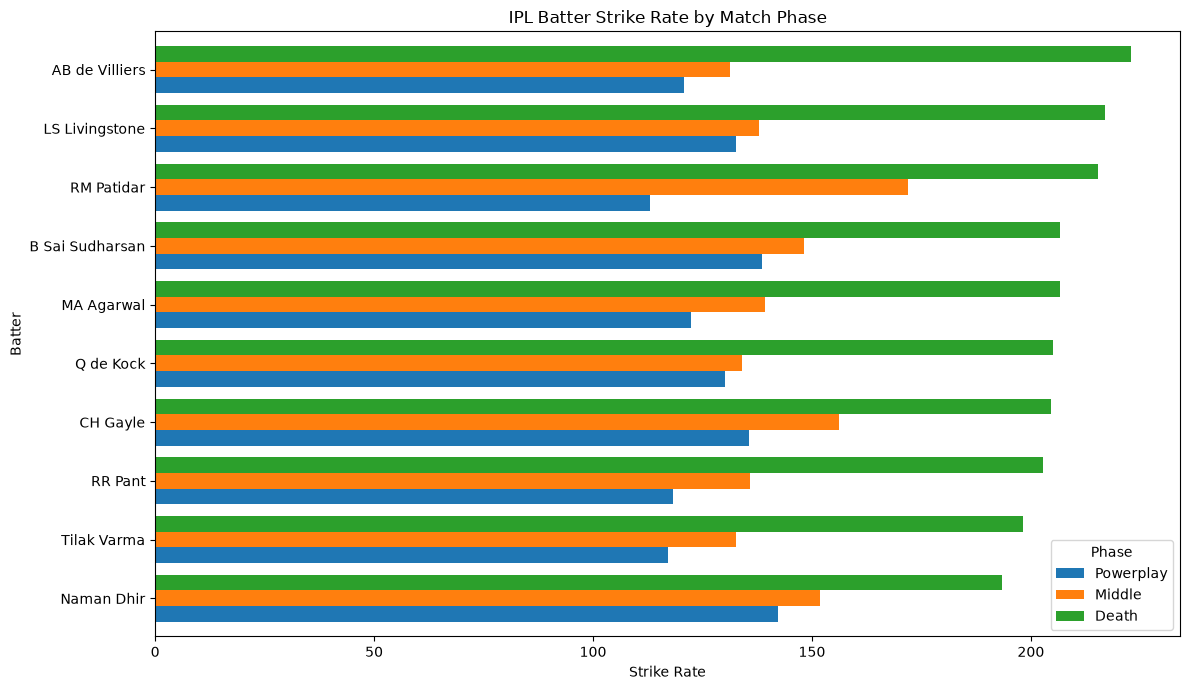

In [92]:
import matplotlib.pyplot as plt

# Compare the top 10 death-over batters
top_death = (
    phase_comparison
    .sort_values("Death", ascending=False)
    .head(10)
    .sort_values("Death")
)

top_death.plot(
    x="batter",
    y=["Powerplay", "Middle", "Death"],
    kind="barh",
    figsize=(12, 7),
    width=0.8
)

plt.title("IPL Batter Strike Rate by Match Phase")
plt.xlabel("Strike Rate")
plt.ylabel("Batter")
plt.legend(title="Phase")
plt.tight_layout()
plt.show()

In [93]:
# Rank batters by consistency, with a minimum of 20 appearances

consistency_ranking = player_efficiency[
    (player_efficiency["innings"] >= 20) &
    (player_efficiency["average_runs"] > 0)
].copy()

consistency_ranking["consistency_cv"] = (
    consistency_ranking["score_std"] /
    consistency_ranking["average_runs"]
)

display(
    consistency_ranking[
        [
            "batter", "innings", "total_runs",
            "average_runs", "strike_rate", "consistency_cv"
        ]
    ]
    .sort_values("consistency_cv")
    .head(20)
    .round(2)
)

,batter,innings,total_runs,average_runs,strike_rate,consistency_cv
27,B Sai Sudharsan,57,2515,44.12,150.24,0.65
66,H Klaasen,60,2104,35.07,167.92,0.67
0,A Ashish Reddy,23,280,12.17,145.08,0.73
158,R Dravid,82,2174,26.51,115.76,0.74
4,A Raghuvanshi,30,885,29.50,146.04,0.74
161,R Sathish,24,270,11.25,117.39,0.75
39,D Brevis,24,606,25.25,146.02,0.76
43,DB Das,22,304,13.82,116.92,0.76
87,JP Duminy,75,2029,27.05,124.40,0.76
11,AK Markram,67,1671,24.94,136.07,0.76


In [94]:
# Find batters who combine high scoring output with consistency

qualified_batters = player_efficiency[
    player_efficiency["innings"] >= 20
].copy()

qualified_batters["consistency_cv"] = (
    qualified_batters["score_std"] /
    qualified_batters["average_runs"]
)

# Use median thresholds to avoid arbitrary cutoffs
avg_runs_threshold = qualified_batters["average_runs"].median()
strike_rate_threshold = qualified_batters["strike_rate"].median()
cv_threshold = qualified_batters["consistency_cv"].median()

qualified_batters["profile"] = qualified_batters.apply(
    lambda row: (
        "High impact + consistent"
        if row["average_runs"] >= avg_runs_threshold
        and row["strike_rate"] >= strike_rate_threshold
        and row["consistency_cv"] <= cv_threshold
        else "Other"
    ),
    axis=1
)

display(
    qualified_batters[
        qualified_batters["profile"] == "High impact + consistent"
    ][
        [
            "batter", "innings", "total_runs",
            "average_runs", "strike_rate", "consistency_cv"
        ]
    ]
    .sort_values(
        ["average_runs", "strike_rate"],
        ascending=False
    )
    .round(2)
    .reset_index(drop=True)
)

,batter,innings,total_runs,average_runs,strike_rate,consistency_cv
0,V Suryavanshi,23,1028,44.70,229.98,0.79
1,B Sai Sudharsan,57,2515,44.12,150.24,0.65
2,DP Conway,28,1080,38.57,140.26,0.83
3,KL Rahul,152,5828,38.34,139.59,0.81
4,SE Marsh,70,2489,35.56,133.39,0.81
5,Shubman Gill,130,4598,35.37,142.66,0.85
6,DA Warner,187,6567,35.12,140.32,0.83
7,H Klaasen,60,2104,35.07,167.92,0.67
8,JC Buttler,137,4647,33.92,150.19,0.88
9,RD Gaikwad,84,2839,33.80,136.29,0.88


In [95]:
# Correct aggregate balls faced from the existing phase-level data

correct_batting_totals = (
    batter_phase_df
    .groupby("batter")
    .agg(
        phase_runs=("runs", "sum"),
        phase_balls_faced=("balls_faced", "sum")
    )
    .reset_index()
)

correct_batting_totals["phase_strike_rate"] = (
    100 * correct_batting_totals["phase_runs"]
    / correct_batting_totals["phase_balls_faced"].replace(0, float("nan"))
).round(2)

display(
    correct_batting_totals
    .sort_values("phase_runs", ascending=False)
    .head(20)
)

,batter,phase_runs,phase_balls_faced,phase_strike_rate
694,V Kohli,9346,6930,134.86
527,RG Sharma,7331,5517,132.88
564,S Dhawan,6769,5326,127.09
159,DA Warner,6567,4702,139.66
311,KL Rahul,5828,4188,139.16
598,SK Raina,5536,4046,136.83
409,MS Dhoni,5439,3957,137.45
52,AM Rahane,5367,4273,125.60
628,SV Samson,5181,3671,141.13
31,AB de Villiers,5181,3411,151.89


In [96]:
# Correct aggregate balls faced from the existing phase-level data

correct_batting_totals = (
    batter_phase_df
    .groupby("batter")
    .agg(
        phase_runs=("runs", "sum"),
        phase_balls_faced=("balls_faced", "sum")
    )
    .reset_index()
)

correct_batting_totals["phase_strike_rate"] = (
    100 * correct_batting_totals["phase_runs"]
    / correct_batting_totals["phase_balls_faced"].replace(0, float("nan"))
).round(2)

display(
    correct_batting_totals
    .sort_values("phase_runs", ascending=False)
    .head(20)
)

,batter,phase_runs,phase_balls_faced,phase_strike_rate
694,V Kohli,9346,6930,134.86
527,RG Sharma,7331,5517,132.88
564,S Dhawan,6769,5326,127.09
159,DA Warner,6567,4702,139.66
311,KL Rahul,5828,4188,139.16
598,SK Raina,5536,4046,136.83
409,MS Dhoni,5439,3957,137.45
52,AM Rahane,5367,4273,125.60
628,SV Samson,5181,3671,141.13
31,AB de Villiers,5181,3411,151.89


,batter,phase_runs,phase_balls_faced,phase_strike_rate
0,AB de Villiers,5181,3411,151.89
1,JC Buttler,4647,3105,149.66
2,CH Gayle,4997,3346,149.34
3,SA Yadav,4581,3084,148.54
4,Shubman Gill,4598,3236,142.09
5,SV Samson,5181,3671,141.13
6,DA Warner,6567,4702,139.66
7,KL Rahul,5828,4188,139.16
8,MS Dhoni,5439,3957,137.45
9,SK Raina,5536,4046,136.83


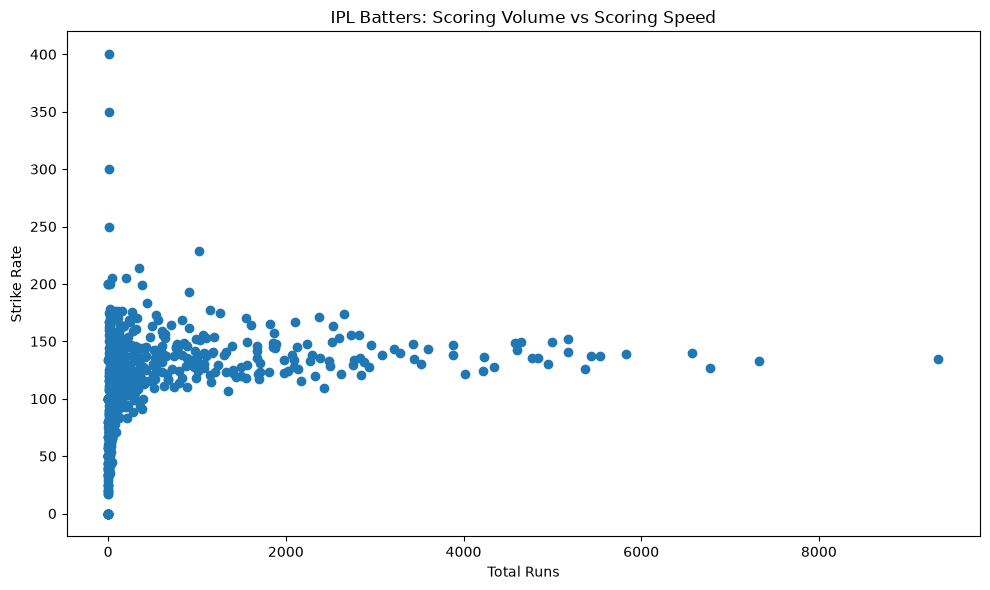

In [97]:
# Top run scorers: scoring speed vs total output

top_scorers = (
    correct_batting_totals
    .sort_values("phase_runs", ascending=False)
    .head(20)
    .sort_values("phase_strike_rate", ascending=False)
)

display(
    top_scorers[
        ["batter", "phase_runs", "phase_balls_faced", "phase_strike_rate"]
    ].reset_index(drop=True)
)

# Visualize the trade-off
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 6))
plt.scatter(
    correct_batting_totals["phase_runs"],
    correct_batting_totals["phase_strike_rate"]
)

plt.xlabel("Total Runs")
plt.ylabel("Strike Rate")
plt.title("IPL Batters: Scoring Volume vs Scoring Speed")
plt.tight_layout()
plt.show()

In [98]:
# Build a normalized batting impact score

impact_df = player_efficiency.merge(
    correct_batting_totals[
        ["batter", "phase_strike_rate"]
    ],
    on="batter",
    how="inner"
)

impact_df = impact_df[
    (impact_df["innings"] >= 20) &
    (impact_df["total_runs"] > 0)
].copy()

# Normalize metrics to a 0–1 scale
for col in ["total_runs", "phase_strike_rate", "consistency_cv"]:
    min_val = impact_df[col].min()
    max_val = impact_df[col].max()

    if max_val != min_val:
        impact_df[f"{col}_norm"] = (
            (impact_df[col] - min_val) / (max_val - min_val)
        )
    else:
        impact_df[f"{col}_norm"] = 0.0

# Higher volume and strike rate are better; lower CV is better
impact_df["consistency_norm"] = 1 - impact_df["consistency_cv_norm"]

impact_df["impact_score"] = (
    0.40 * impact_df["total_runs_norm"] +
    0.35 * impact_df["phase_strike_rate_norm"] +
    0.25 * impact_df["consistency_norm"]
) * 100

display(
    impact_df[
        [
            "batter", "innings", "total_runs",
            "phase_strike_rate", "consistency_cv", "impact_score"
        ]
    ]
    .sort_values("impact_score", ascending=False)
    .head(20)
    .round(2)
    .reset_index(drop=True)
)

,batter,innings,total_runs,phase_strike_rate,consistency_cv,impact_score
0,V Kohli,277,9346,134.86,0.82,76.99
1,DA Warner,187,6567,139.66,0.83,65.66
2,RG Sharma,276,7331,132.88,0.91,65.25
3,S Dhawan,222,6769,127.09,0.83,64.14
4,KL Rahul,152,5828,139.16,0.81,62.99
5,MS Dhoni,241,5439,137.45,0.80,61.30
6,SK Raina,201,5536,136.83,0.84,60.39
7,V Suryavanshi,23,1028,228.95,0.79,60.03
8,AB de Villiers,172,5181,151.89,0.91,59.62
9,F du Plessis,147,4773,135.79,0.78,58.72


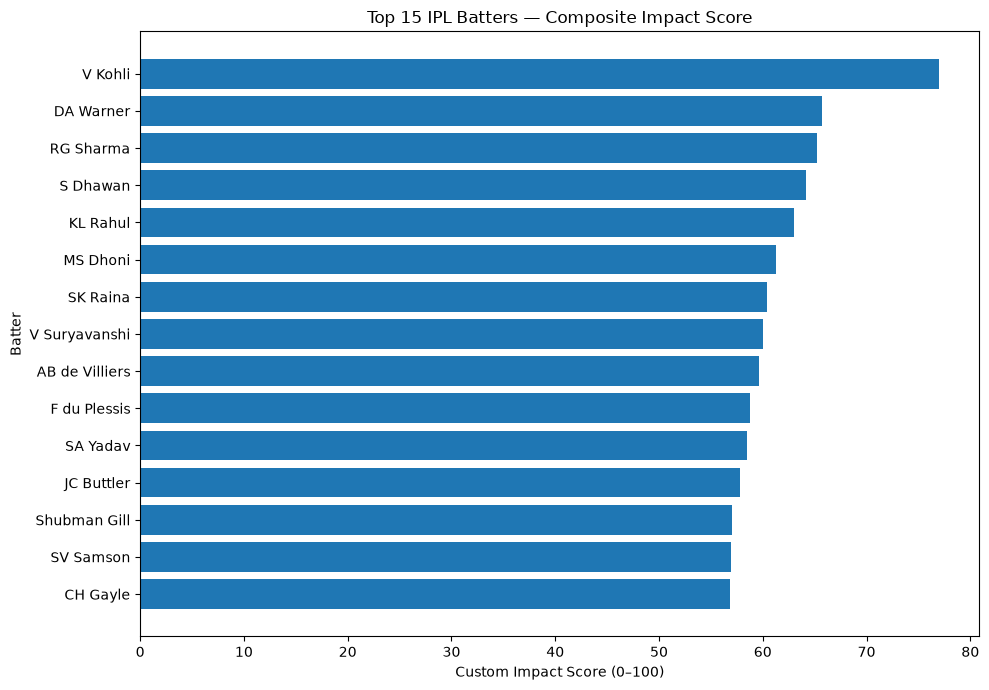

In [99]:
import matplotlib.pyplot as plt

top_impact = (
    impact_df
    .nlargest(15, "impact_score")
    .sort_values("impact_score")
)

plt.figure(figsize=(10, 7))
plt.barh(top_impact["batter"], top_impact["impact_score"])

plt.xlabel("Custom Impact Score (0–100)")
plt.ylabel("Batter")
plt.title("Top 15 IPL Batters — Composite Impact Score")
plt.tight_layout()
plt.show()

In [100]:
# Team batting performance across all match phases

team_batting = (
    phase_df
    .groupby("batting_team")
    .agg(
        total_runs=("runs", "sum"),
        legal_balls=("legal_ball", "sum"),
        matches=("match_id", "nunique")
    )
    .reset_index()
)

team_batting["run_rate"] = (
    team_batting["total_runs"] * 6
    / team_batting["legal_balls"].replace(0, float("nan"))
).round(2)

display(
    team_batting
    .sort_values("run_rate", ascending=False)
    .reset_index(drop=True)
)

,batting_team,total_runs,legal_balls,matches,run_rate
0,Royal Challengers Bengaluru,8640,5124,46,10.12
1,Punjab Kings,15509,9973,87,9.33
2,Gujarat Titans,13743,8959,77,9.20
3,Lucknow Super Giants,12754,8438,72,9.07
4,Delhi Capitals,19959,13772,119,8.70
5,Sunrisers Hyderabad,34640,24294,210,8.56
6,Mumbai Indians,47641,33665,291,8.49
7,Gujarat Lions,4862,3439,30,8.48
8,Chennai Super Kings,43600,30898,265,8.47
9,Rajasthan Royals,40437,28702,250,8.45


In [101]:
# Normalize historical franchise aliases

team_aliases = {
    "Royal Challengers Bangalore": "Royal Challengers Bengaluru",
    "Kings XI Punjab": "Punjab Kings",
    "Delhi Daredevils": "Delhi Capitals",
    "Rising Pune Supergiants": "Rising Pune Supergiant"
}

phase_df["team_normalized"] = (
    phase_df["batting_team"].replace(team_aliases)
)

team_batting_normalized = (
    phase_df
    .groupby("team_normalized")
    .agg(
        total_runs=("runs", "sum"),
        legal_balls=("legal_ball", "sum"),
        matches=("match_id", "nunique")
    )
    .reset_index()
)

team_batting_normalized["run_rate"] = (
    team_batting_normalized["total_runs"] * 6
    / team_batting_normalized["legal_balls"].replace(0, float("nan"))
).round(2)

display(
    team_batting_normalized
    .sort_values("run_rate", ascending=False)
    .reset_index(drop=True)
)

,team_normalized,total_runs,legal_balls,matches,run_rate
0,Gujarat Titans,13743,8959,77,9.20
1,Lucknow Super Giants,12754,8438,72,9.07
2,Royal Challengers Bengaluru,46332,32335,286,8.60
3,Punjab Kings,45573,31878,277,8.58
4,Sunrisers Hyderabad,34640,24294,210,8.56
5,Mumbai Indians,47641,33665,291,8.49
6,Gujarat Lions,4862,3439,30,8.48
7,Chennai Super Kings,43600,30898,265,8.47
8,Rajasthan Royals,40437,28702,250,8.45
9,Kolkata Knight Riders,43646,31193,278,8.40


In [102]:
# Team run rates by phase

team_phase_analysis = (
    phase_df
    .groupby(["team_normalized", "phase"])
    .agg(
        runs=("runs", "sum"),
        legal_balls=("legal_ball", "sum"),
        matches=("match_id", "nunique")
    )
    .reset_index()
)

team_phase_analysis["run_rate"] = (
    team_phase_analysis["runs"] * 6
    / team_phase_analysis["legal_balls"].replace(0, float("nan"))
).round(2)

team_phase_pivot = team_phase_analysis.pivot(
    index="team_normalized",
    columns="phase",
    values="run_rate"
).reset_index()

team_phase_pivot.columns.name = None

display(
    team_phase_pivot
    .sort_values("Death", ascending=False)
    .reset_index(drop=True)
)

,team_normalized,Death,Middle,Powerplay
0,Gujarat Titans,10.79,8.80,8.65
1,Royal Challengers Bengaluru,10.63,8.05,7.98
2,Lucknow Super Giants,10.54,8.62,8.62
3,Chennai Super Kings,10.41,7.87,7.90
4,Mumbai Indians,10.40,7.91,7.97
5,Kolkata Knight Riders,10.01,7.89,8.05
6,Punjab Kings,9.96,8.13,8.24
7,Rising Pune Supergiant,9.93,7.34,7.91
8,Delhi Capitals,9.84,7.78,8.05
9,Rajasthan Royals,9.75,8.02,8.18


In [103]:
# Attach match-level team names to first-innings scores

first_innings_team = first_scores_df.merge(
    matches_df[["match_id", "team1", "team2"]],
    on="match_id",
    how="left"
)

# Determine which team batted first from the match data if available.
# Inspect the current columns before assigning batting teams.
print("first_scores_df columns:", first_scores_df.columns.tolist())
display(first_scores_df.head())

first_scores_df columns: ['match_id', 'first_innings_score']


,match_id,first_innings_score
0,1082591,207
1,1082592,184
2,1082593,183
3,1082594,163
4,1082595,157


In [104]:
# Identify the first-innings batting team for each match

first_innings_teams = (
    phase_df[phase_df["innings"] == 1]
    .groupby("match_id")["batting_team"]
    .first()
    .reset_index(name="first_batting_team")
)

first_innings_analysis = first_scores_df.merge(
    first_innings_teams,
    on="match_id",
    how="left"
)

first_innings_analysis["first_batting_team"] = (
    first_innings_analysis["first_batting_team"]
    .replace(team_aliases)
)

print("Matches with first-innings team identified:",
      first_innings_analysis["first_batting_team"].notna().sum())

display(first_innings_analysis.head())

Matches with first-innings team identified: 1243


,match_id,first_innings_score,first_batting_team
0,1082591,207,Sunrisers Hyderabad
1,1082592,184,Mumbai Indians
2,1082593,183,Gujarat Lions
3,1082594,163,Rising Pune Supergiant
4,1082595,157,Royal Challengers Bengaluru


In [105]:
# Team first-innings scoring consistency

team_first_innings = (
    first_innings_analysis
    .groupby("first_batting_team")
    .agg(
        innings=("first_innings_score", "count"),
        average_score=("first_innings_score", "mean"),
        median_score=("first_innings_score", "median"),
        score_std=("first_innings_score", "std"),
        minimum_score=("first_innings_score", "min"),
        maximum_score=("first_innings_score", "max")
    )
    .reset_index()
)

team_first_innings["consistency_cv"] = (
    team_first_innings["score_std"]
    / team_first_innings["average_score"]
)

team_first_innings = team_first_innings.round(2)

display(
    team_first_innings
    .sort_values("consistency_cv")
    .reset_index(drop=True)
)

,first_batting_team,innings,average_score,median_score,score_std,minimum_score,maximum_score,consistency_cv
0,Rising Pune Supergiant,15,161.80,161.0,21.10,103,195,0.13
1,Gujarat Lions,14,161.93,159.5,23.25,126,208,0.14
2,Lucknow Super Giants,41,185.73,180.0,29.36,125,257,0.16
3,Kochi Tuskers Kerala,7,144.14,148.0,23.58,109,178,0.16
4,Mumbai Indians,150,169.02,168.0,27.57,92,243,0.16
5,Deccan Chargers,43,157.33,164.0,27.04,82,214,0.17
6,Gujarat Titans,34,186.38,194.0,33.55,89,233,0.18
7,Chennai Super Kings,144,170.86,169.5,31.59,97,246,0.18
8,Rajasthan Royals,117,167.12,165.0,33.18,81,243,0.20
9,Pune Warriors,20,148.65,144.5,29.09,99,192,0.20


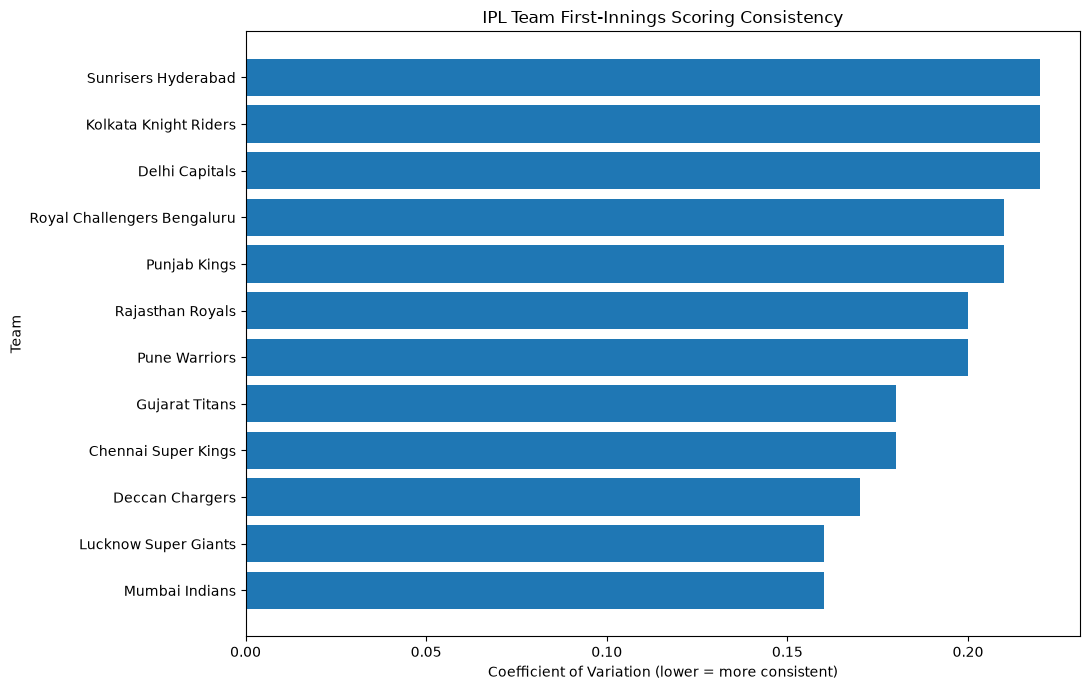

In [106]:
import matplotlib.pyplot as plt

# Exclude teams with fewer than 20 first-innings samples
team_consistency_plot = team_first_innings[
    team_first_innings["innings"] >= 20
].sort_values("consistency_cv")

plt.figure(figsize=(11, 7))
plt.barh(
    team_consistency_plot["first_batting_team"],
    team_consistency_plot["consistency_cv"]
)

plt.xlabel("Coefficient of Variation (lower = more consistent)")
plt.ylabel("Team")
plt.title("IPL Team First-Innings Scoring Consistency")
plt.tight_layout()
plt.show()

In [107]:
# Partnership analysis: aggregate runs scored by each batting pair

from collections import defaultdict

partnership_rows = []

for file_path in (PROJECT_ROOT / "data" / "raw").glob("*.yaml"):
    with open(file_path, "r", encoding="utf-8") as f:
        data = yaml.safe_load(f)

    match_id = file_path.stem

    for innings_num, innings_item in enumerate(data.get("innings", []), start=1):
        innings_data = next(iter(innings_item.values()))
        deliveries = innings_data.get("deliveries", [])

        pair_runs = defaultdict(int)

        for delivery_item in deliveries:
            delivery = next(iter(delivery_item.values()))
            batter = delivery.get("batsman")
            non_striker = delivery.get("non_striker")
            total_runs = delivery.get("runs", {}).get("total", 0)

            if batter and non_striker:
                pair = tuple(sorted([batter, non_striker]))
                pair_runs[pair] += total_runs

        for pair, runs in pair_runs.items():
            partnership_rows.append({
                "match_id": match_id,
                "innings": innings_num,
                "batter_1": pair[0],
                "batter_2": pair[1],
                "partnership_runs": runs
            })

partnerships_df = pd.DataFrame(partnership_rows)

partnership_summary = (
    partnerships_df
    .groupby(["batter_1", "batter_2"])
    .agg(
        matches_together=("match_id", "nunique"),
        innings=("partnership_runs", "count"),
        total_runs=("partnership_runs", "sum"),
        average_runs=("partnership_runs", "mean"),
        highest_innings_total=("partnership_runs", "max")
    )
    .reset_index()
)

display(
    partnership_summary[
        partnership_summary["innings"] >= 10
    ]
    .sort_values("total_runs", ascending=False)
    .head(20)
    .round(2)
    .reset_index(drop=True)
)

,batter_1,batter_2,matches_together,innings,total_runs,average_runs,highest_innings_total
0,AB de Villiers,V Kohli,77,77,3134,40.70,229
1,B Sai Sudharsan,Shubman Gill,49,49,2966,60.53,210
2,CH Gayle,V Kohli,60,60,2802,46.70,204
3,DA Warner,S Dhawan,50,50,2357,47.14,139
4,F du Plessis,V Kohli,41,41,2032,49.56,172
5,D Padikkal,V Kohli,43,43,2024,47.07,181
6,G Gambhir,RV Uthappa,48,48,1906,39.71,158
7,Abhishek Sharma,TM Head,42,42,1892,45.05,171
8,Ishan Kishan,RG Sharma,54,54,1868,34.59,101
9,KL Rahul,MA Agarwal,33,33,1731,52.45,183


In [108]:
# Dismissal analysis across all IPL YAML files

dismissal_rows = []

for file_path in (PROJECT_ROOT / "data" / "raw").glob("*.yaml"):
    with open(file_path, "r", encoding="utf-8") as f:
        data = yaml.safe_load(f)

    for innings_num, innings_item in enumerate(data.get("innings", []), start=1):
        innings_data = next(iter(innings_item.values()))

        for delivery_item in innings_data.get("deliveries", []):
            delivery = next(iter(delivery_item.values()))
            wicket = delivery.get("wicket")

            if wicket:
                dismissal_rows.append({
                    "match_id": file_path.stem,
                    "innings": innings_num,
                    "batter_out": wicket.get("player_out"),
                    "dismissal_type": wicket.get("kind"),
                    "bowler": delivery.get("bowler"),
                    "batting_team": innings_data.get("team")
                })

dismissals_df = pd.DataFrame(dismissal_rows)

dismissal_summary = (
    dismissals_df
    .groupby("dismissal_type")
    .agg(
        dismissals=("dismissal_type", "size"),
        batters=("batter_out", "nunique")
    )
    .reset_index()
)

dismissal_summary["percentage"] = (
    dismissal_summary["dismissals"]
    / dismissal_summary["dismissals"].sum() * 100
)

display(
    dismissal_summary
    .sort_values("dismissals", ascending=False)
    .round(2)
    .reset_index(drop=True)
)

,dismissal_type,dismissals,batters,percentage
0,caught,9321,606,63.39
1,bowled,2460,459,16.73
2,run out,1194,386,8.12
3,lbw,883,297,6.00
4,caught and bowled,410,209,2.79
5,stumped,388,184,2.64
6,hit wicket,20,18,0.14
7,retired hurt,19,16,0.13
8,retired out,6,6,0.04
9,obstructing the field,4,4,0.03


In [109]:
# Dismissal types by bowler
# Exclude dismissals not credited to the bowler

bowler_credited_dismissals = dismissals_df[
    ~dismissals_df["dismissal_type"].isin(
        ["run out", "retired hurt", "retired out", "obstructing the field"]
    )
]

bowler_dismissal_summary = (
    bowler_credited_dismissals
    .groupby(["bowler", "dismissal_type"])
    .size()
    .reset_index(name="dismissals")
)

bowler_dismissal_pivot = (
    bowler_dismissal_summary
    .pivot(
        index="bowler",
        columns="dismissal_type",
        values="dismissals"
    )
    .fillna(0)
    .astype(int)
)

bowler_dismissal_pivot["total_credited_wickets"] = (
    bowler_dismissal_pivot.sum(axis=1)
)

display(
    bowler_dismissal_pivot
    .sort_values("total_credited_wickets", ascending=False)
    .head(20)
    .reset_index()
)

dismissal_type,bowler,bowled,caught,caught and bowled,hit wicket,lbw,stumped,total_credited_wickets
0,YS Chahal,38,150,4,0,19,22,233
1,B Kumar,46,159,6,0,13,2,226
2,SP Narine,57,105,10,0,26,11,209
3,PP Chawla,50,95,7,0,21,19,192
4,JJ Bumrah,48,120,4,0,18,0,190
5,R Ashwin,29,122,7,0,19,10,187
6,DJ Bravo,21,143,11,0,8,0,183
7,RA Jadeja,40,103,7,0,18,12,180
8,Rashid Khan,45,85,2,0,39,8,179
9,A Mishra,26,102,4,0,14,28,174


In [110]:
# Core dataset quality audit

quality_checks = pd.DataFrame([
    {
        "check": "Duplicate match IDs",
        "count": matches_df["match_id"].duplicated().sum()
    },
    {
        "check": "Missing match dates",
        "count": matches_df["date"].isna().sum()
    },
    {
        "check": "Missing team names",
        "count": matches_df[["team1", "team2"]].isna().any(axis=1).sum()
    },
    {
        "check": "Missing match winners",
        "count": matches_df["winner"].isna().sum()
    },
    {
        "check": "Missing first-innings scores",
        "count": first_innings_analysis["first_innings_score"].isna().sum()
    },
    {
        "check": "Negative first-innings scores",
        "count": (first_innings_analysis["first_innings_score"] < 0).sum()
    },
    {
        "check": "Missing dismissal types",
        "count": dismissals_df["dismissal_type"].isna().sum()
    },
    {
        "check": "Duplicate match-innings-batter rows",
        "count": batting_innings_df.duplicated(
            subset=["match_id", "innings", "batter"]
        ).sum()
    }
])

display(quality_checks)

,check,count
0,Duplicate match IDs,0
1,Missing match dates,0
2,Missing team names,0
3,Missing match winners,25
4,Missing first-innings scores,0
5,Negative first-innings scores,0
6,Missing dismissal types,0
7,Duplicate match-innings-batter rows,0


In [111]:
# Investigate matches with no recorded winner

no_winner_matches = matches_df[matches_df["winner"].isna()]

display(
    no_winner_matches[
        [
            "match_id",
            "date",
            "season",
            "team1",
            "team2",
            "venue",
            "toss_decision",
            "win_by_runs",
            "win_by_wickets"
        ]
    ]
    .sort_values("date")
    .reset_index(drop=True)
)

,match_id,date,season,team1,team2,venue,toss_decision,win_by_runs,win_by_wickets
0,392190,2009-04-23,2009,Kolkata Knight Riders,Rajasthan Royals,Newlands,field,0,0
1,419121,2010-03-21,2010,Chennai Super Kings,Kings XI Punjab,"MA Chidambaram Stadium, Chepauk",field,0,0
2,501265,2011-05-21,2011,Delhi Daredevils,Pune Warriors,Feroz Shah Kotla,bat,0,0
3,598004,2013-04-07,2013,Sunrisers Hyderabad,Royal Challengers Bangalore,"Rajiv Gandhi International Stadium, Uppal",bat,0,0
4,598017,2013-04-16,2013,Royal Challengers Bangalore,Delhi Daredevils,M Chinnaswamy Stadium,field,0,0
5,729315,2014-04-29,2014,Kolkata Knight Riders,Rajasthan Royals,Sheikh Zayed Stadium,bat,0,0
6,829741,2015-04-21,2015,Rajasthan Royals,Kings XI Punjab,"Sardar Patel Stadium, Motera",field,0,0
7,829763,2015-04-29,2015,Royal Challengers Bangalore,Rajasthan Royals,M Chinnaswamy Stadium,field,0,0
8,829813,2015-05-17,2015,Royal Challengers Bangalore,Delhi Daredevils,M Chinnaswamy Stadium,field,0,0
9,1082625,2017-04-29,2017,Gujarat Lions,Mumbai Indians,Saurashtra Cricket Association Stadium,bat,0,0


In [114]:
# Fix mixed date types and sort safely

outcome_audit_df["date"] = pd.to_datetime(
    outcome_audit_df["date"], errors="coerce"
)

display(
    outcome_audit_df
    .sort_values("date")
    .reset_index(drop=True)
)

,match_id,date,outcome_by,outcome_method,outcome_result,eliminator,winner_in_metadata
0,392190,2009-04-23,None,None,tie,Rajasthan Royals,None
1,419121,2010-03-21,None,None,tie,Kings XI Punjab,None
2,501265,2011-05-21,None,None,no result,NaN,None
3,598004,2013-04-07,None,None,tie,Sunrisers Hyderabad,None
4,598017,2013-04-16,None,None,tie,Royal Challengers Bangalore,None
5,729315,2014-04-29,None,None,tie,Rajasthan Royals,None
6,829741,2015-04-21,None,None,tie,Kings XI Punjab,None
7,829763,2015-04-29,None,None,no result,NaN,None
8,829813,2015-05-17,None,None,no result,NaN,None
9,1082625,2017-04-29,None,None,tie,Mumbai Indians,None


In [115]:
# Audit team-name variants and season/date coverage

team_names = sorted(
    set(matches_df["team1"].dropna())
    | set(matches_df["team2"].dropna())
)

alias_audit = pd.DataFrame({
    "raw_team_name": team_names,
    "normalized_team_name": [
        team_aliases.get(team, team) for team in team_names
    ]
})

print("TEAM ALIAS AUDIT")
display(alias_audit)

print("\nMATCHES BY CALENDAR YEAR")
display(
    matches_df.groupby("season")
    .agg(
        matches=("match_id", "count"),
        first_date=("date", "min"),
        last_date=("date", "max")
    )
    .reset_index()
    .sort_values("season")
)

TEAM ALIAS AUDIT


,raw_team_name,normalized_team_name
0,Chennai Super Kings,Chennai Super Kings
1,Deccan Chargers,Deccan Chargers
2,Delhi Capitals,Delhi Capitals
3,Delhi Daredevils,Delhi Capitals
4,Gujarat Lions,Gujarat Lions
5,Gujarat Titans,Gujarat Titans
6,Kings XI Punjab,Punjab Kings
7,Kochi Tuskers Kerala,Kochi Tuskers Kerala
8,Kolkata Knight Riders,Kolkata Knight Riders
9,Lucknow Super Giants,Lucknow Super Giants



MATCHES BY CALENDAR YEAR


,season,matches,first_date,last_date
0,2008,58,2008-04-18,2008-06-01
1,2009,57,2009-04-18,2009-05-24
2,2010,60,2010-03-12,2010-04-25
3,2011,73,2011-04-08,2011-05-28
4,2012,74,2012-04-04,2012-05-27
5,2013,76,2013-04-03,2013-05-26
6,2014,60,2014-04-16,2014-06-01
7,2015,59,2015-04-08,2015-05-24
8,2016,60,2016-04-09,2016-05-29
9,2017,59,2017-04-05,2017-05-21


In [116]:
# Final EDA headline metrics

print("DATASET OVERVIEW")
print(f"Matches: {len(matches_df):,}")
print(f"Delivery records: {len(phase_df):,}")
print(f"Recorded dismissal events: {len(dismissals_df):,}")
print(f"Calendar years: {matches_df['season'].min()}–{matches_df['season'].max()}")

print("\nMATCH OUTCOMES")
print(f"Matches with recorded winners: {matches_df['winner'].notna().sum():,}")
print(f"Matches without recorded winners: {matches_df['winner'].isna().sum():,}")
print(outcome_audit_df["outcome_result"].value_counts(dropna=False))

print("\nSCORING")
print(f"Overall mean first-innings score: {first_innings_analysis['first_innings_score'].mean():.2f}")
print(f"Overall median first-innings score: {first_innings_analysis['first_innings_score'].median():.2f}")

print("\nDISMISSAL MIX (%)")
display(
    dismissal_summary[["dismissal_type", "dismissals", "percentage"]]
    .sort_values("dismissals", ascending=False)
    .round(2)
    .reset_index(drop=True)
)

print("\nTOP BATTING RUN-SCORERS")
display(
    correct_batting_totals
    .sort_values("phase_runs", ascending=False)
    [["batter", "phase_runs", "phase_balls_faced", "phase_strike_rate"]]
    .head(10)
    .reset_index(drop=True)
    .round(2)
)

print("\nTOP WICKET-TAKERS")
display(
    bowling_summary
    .sort_values("wickets", ascending=False)
    [["bowler", "wickets", "legal_balls", "economy"]]
    .head(10)
    .reset_index(drop=True)
    .round(2)
)

DATASET OVERVIEW
Matches: 1,243
Delivery records: 295,732
Recorded dismissal events: 14,705
Calendar years: 2008–2026

MATCH OUTCOMES
Matches with recorded winners: 1,218
Matches without recorded winners: 25
outcome_result
tie          16
no result     9
Name: count, dtype: int64

SCORING
Overall mean first-innings score: 168.57
Overall median first-innings score: 168.00

DISMISSAL MIX (%)


,dismissal_type,dismissals,percentage
0,caught,9321,63.39
1,bowled,2460,16.73
2,run out,1194,8.12
3,lbw,883,6.00
4,caught and bowled,410,2.79
5,stumped,388,2.64
6,hit wicket,20,0.14
7,retired hurt,19,0.13
8,retired out,6,0.04
9,obstructing the field,4,0.03



TOP BATTING RUN-SCORERS


,batter,phase_runs,phase_balls_faced,phase_strike_rate
0,V Kohli,9346,6930,134.86
1,RG Sharma,7331,5517,132.88
2,S Dhawan,6769,5326,127.09
3,DA Warner,6567,4702,139.66
4,KL Rahul,5828,4188,139.16
5,SK Raina,5536,4046,136.83
6,MS Dhoni,5439,3957,137.45
7,AM Rahane,5367,4273,125.60
8,SV Samson,5181,3671,141.13
9,AB de Villiers,5181,3411,151.89



TOP WICKET-TAKERS


,bowler,wickets,legal_balls,economy
0,YS Chahal,233,4037,8.05
1,B Kumar,226,4600,7.71
2,SP Narine,209,4660,6.79
3,PP Chawla,192,3850,7.96
4,JJ Bumrah,190,3653,7.34
5,R Ashwin,187,4710,7.20
6,DJ Bravo,183,3120,8.38
7,RA Jadeja,180,4254,7.71
8,Rashid Khan,179,3543,7.28
9,A Mishra,174,3371,7.38


In [117]:
# Final consistency checks

print("OUTCOME COUNTS — SOURCE YAML")
print(outcome_audit_df["outcome_result"].value_counts(dropna=False))

print("\nOUTCOME COUNTS — MATCH DATAFRAME")
display(
    matches_df[matches_df["winner"].isna()]
    .groupby("season")
    .size()
    .reset_index(name="matches_without_winner")
)

print("\nTEAM ALIAS NORMALIZATION")
display(alias_audit)

print("\nCHECK MATCH IDS BETWEEN OUTCOME AUDIT AND MATCH DATA")
print("Missing from outcome audit:",
      len(set(no_winner_matches["match_id"].astype(str))
          - set(outcome_audit_df["match_id"].astype(str))))
print("Extra in outcome audit:",
      len(set(outcome_audit_df["match_id"].astype(str))
          - set(no_winner_matches["match_id"].astype(str))))

OUTCOME COUNTS — SOURCE YAML
outcome_result
tie          16
no result     9
Name: count, dtype: int64

OUTCOME COUNTS — MATCH DATAFRAME


,season,matches_without_winner
0,2009,1
1,2010,1
2,2011,1
3,2013,2
4,2014,1
5,2015,3
6,2017,1
7,2019,3
8,2020,4
9,2021,1



TEAM ALIAS NORMALIZATION


,raw_team_name,normalized_team_name
0,Chennai Super Kings,Chennai Super Kings
1,Deccan Chargers,Deccan Chargers
2,Delhi Capitals,Delhi Capitals
3,Delhi Daredevils,Delhi Capitals
4,Gujarat Lions,Gujarat Lions
5,Gujarat Titans,Gujarat Titans
6,Kings XI Punjab,Punjab Kings
7,Kochi Tuskers Kerala,Kochi Tuskers Kerala
8,Kolkata Knight Riders,Kolkata Knight Riders
9,Lucknow Super Giants,Lucknow Super Giants



CHECK MATCH IDS BETWEEN OUTCOME AUDIT AND MATCH DATA
Missing from outcome audit: 0
Extra in outcome audit: 0


In [118]:
# Rebuild outcome counts directly from all YAML files

from collections import Counter

source_outcomes = Counter()

for file_path in (PROJECT_ROOT / "data" / "raw").glob("*.yaml"):
    with open(file_path, "r", encoding="utf-8") as f:
        data = yaml.safe_load(f)

    if data.get("info", {}).get("outcome", {}).get("result"):
        source_outcomes[
            data["info"]["outcome"]["result"]
        ] += 1

print("Source YAML outcome counts:", source_outcomes)
print("Total classified outcomes:", sum(source_outcomes.values()))

Source YAML outcome counts: Counter({'tie': 16, 'no result': 9})
Total classified outcomes: 25


In [119]:
from pathlib import Path

REPORTS_DIR = PROJECT_ROOT / "reports"
CHARTS_DIR = REPORTS_DIR / "charts"

REPORTS_DIR.mkdir(parents=True, exist_ok=True)
CHARTS_DIR.mkdir(parents=True, exist_ok=True)

print("Created:", REPORTS_DIR)
print("Created:", CHARTS_DIR)

Created: c:\Users\amitb\Desktop\ME\Projects\Data_Analysis_Practice\cricket-analytics-lab\reports
Created: c:\Users\amitb\Desktop\ME\Projects\Data_Analysis_Practice\cricket-analytics-lab\reports\charts


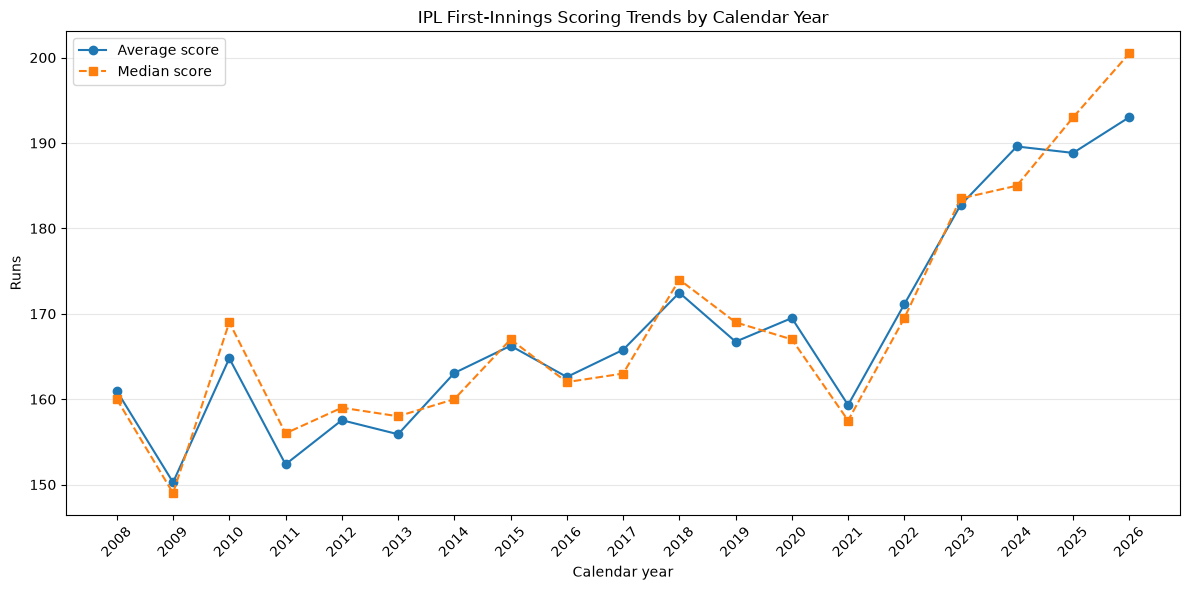

Chart saved to: c:\Users\amitb\Desktop\ME\Projects\Data_Analysis_Practice\cricket-analytics-lab\reports\charts\first_innings_scoring_trends.png


In [120]:
import matplotlib.pyplot as plt

# Aggregate first-innings scores by calendar year
yearly_scores = (
    first_innings_analysis
    .groupby(first_innings_analysis["date"].dt.year
             if "date" in first_innings_analysis.columns
             else first_innings_analysis["match_id"].map(
                 matches_df.set_index("match_id")["season"]
             ))
    ["first_innings_score"]
    .agg(["mean", "median", "count"])
    .reset_index()
)

yearly_scores.columns = ["year", "average_score", "median_score", "matches"]

# Create chart
plt.figure(figsize=(12, 6))
plt.plot(
    yearly_scores["year"],
    yearly_scores["average_score"],
    marker="o",
    label="Average score"
)
plt.plot(
    yearly_scores["year"],
    yearly_scores["median_score"],
    marker="s",
    linestyle="--",
    label="Median score"
)

plt.title("IPL First-Innings Scoring Trends by Calendar Year")
plt.xlabel("Calendar year")
plt.ylabel("Runs")
plt.xticks(yearly_scores["year"], rotation=45)
plt.grid(axis="y", alpha=0.3)
plt.legend()
plt.tight_layout()

# Save chart
chart_path = CHARTS_DIR / "first_innings_scoring_trends.png"
plt.savefig(chart_path, dpi=300, bbox_inches="tight")
plt.show()

print("Chart saved to:", chart_path)

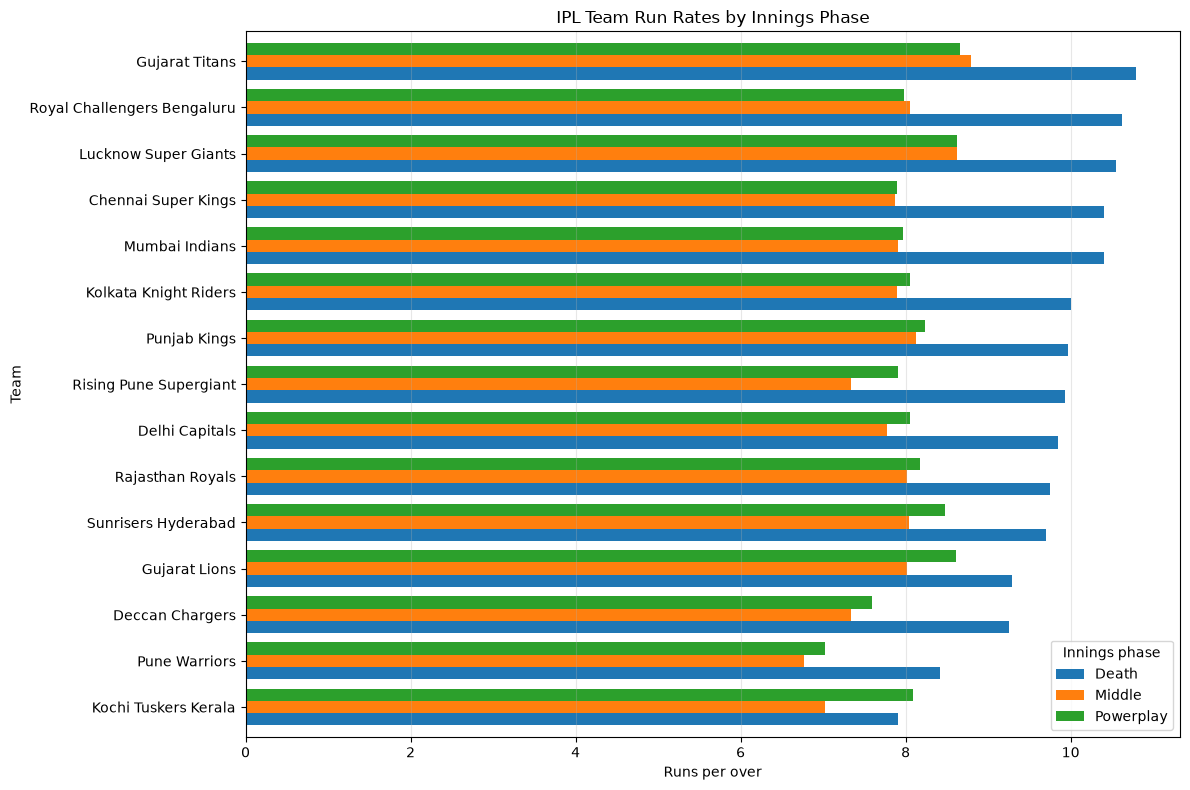

Chart saved to: c:\Users\amitb\Desktop\ME\Projects\Data_Analysis_Practice\cricket-analytics-lab\reports\charts\team_phase_run_rates.png


In [121]:
import matplotlib.pyplot as plt

# Calculate run rate for each team in each phase
team_phase_chart = (
    phase_df[phase_df["phase"].isin(["Powerplay", "Middle", "Death"])]
    .groupby(["team_normalized", "phase"])
    .agg(
        runs=("runs", "sum"),
        legal_balls=("legal_ball", "sum")
    )
    .reset_index()
)

team_phase_chart["run_rate"] = (
    team_phase_chart["runs"] / team_phase_chart["legal_balls"] * 6
)

# Convert phases into columns for easier comparison
phase_pivot = team_phase_chart.pivot(
    index="team_normalized",
    columns="phase",
    values="run_rate"
)

# Sort teams by Death Overs run rate
phase_pivot = phase_pivot.sort_values("Death", ascending=True)

# Plot
ax = phase_pivot.plot(
    kind="barh",
    figsize=(12, 8),
    width=0.8
)

ax.set_title("IPL Team Run Rates by Innings Phase")
ax.set_xlabel("Runs per over")
ax.set_ylabel("Team")
ax.grid(axis="x", alpha=0.3)
ax.legend(title="Innings phase")
plt.tight_layout()

# Save chart
chart_path = CHARTS_DIR / "team_phase_run_rates.png"
plt.savefig(chart_path, dpi=300, bbox_inches="tight")
plt.show()

print("Chart saved to:", chart_path)

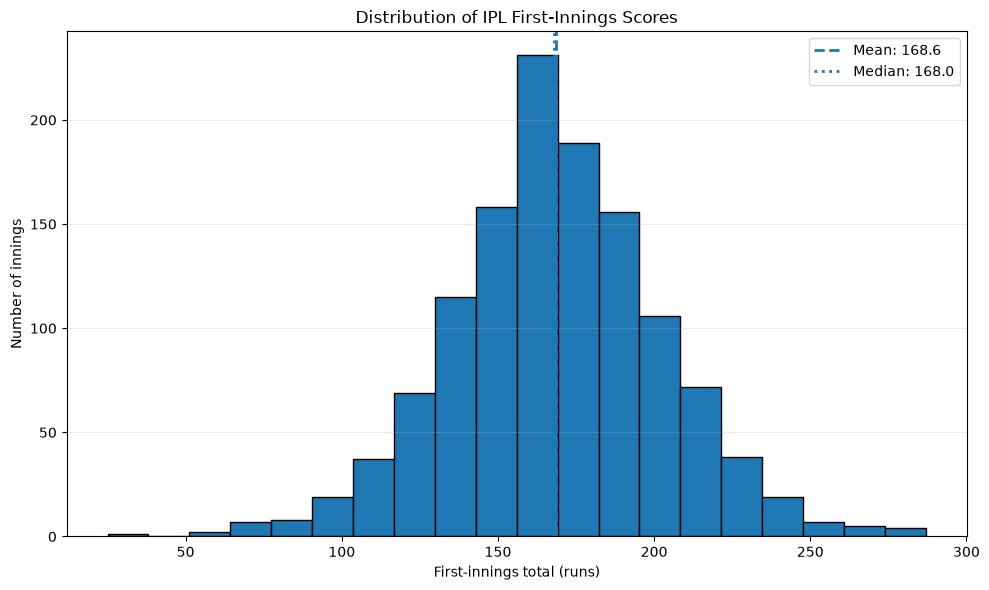

Number of innings: 1243
Mean score: 168.57
Median score: 168.0
Chart saved to: c:\Users\amitb\Desktop\ME\Projects\Data_Analysis_Practice\cricket-analytics-lab\reports\charts\first_innings_score_distribution.png


In [122]:
import matplotlib.pyplot as plt

scores = first_innings_analysis["first_innings_score"].dropna()

plt.figure(figsize=(10, 6))

plt.hist(
    scores,
    bins=20,
    edgecolor="black"
)

plt.axvline(
    scores.mean(),
    linestyle="--",
    linewidth=2,
    label=f"Mean: {scores.mean():.1f}"
)

plt.axvline(
    scores.median(),
    linestyle=":",
    linewidth=2,
    label=f"Median: {scores.median():.1f}"
)

plt.title("Distribution of IPL First-Innings Scores")
plt.xlabel("First-innings total (runs)")
plt.ylabel("Number of innings")
plt.legend()
plt.grid(axis="y", alpha=0.25)
plt.tight_layout()

chart_path = CHARTS_DIR / "first_innings_score_distribution.png"
plt.savefig(chart_path, dpi=300, bbox_inches="tight")
plt.show()

print("Number of innings:", len(scores))
print("Mean score:", round(scores.mean(), 2))
print("Median score:", round(scores.median(), 2))
print("Chart saved to:", chart_path)

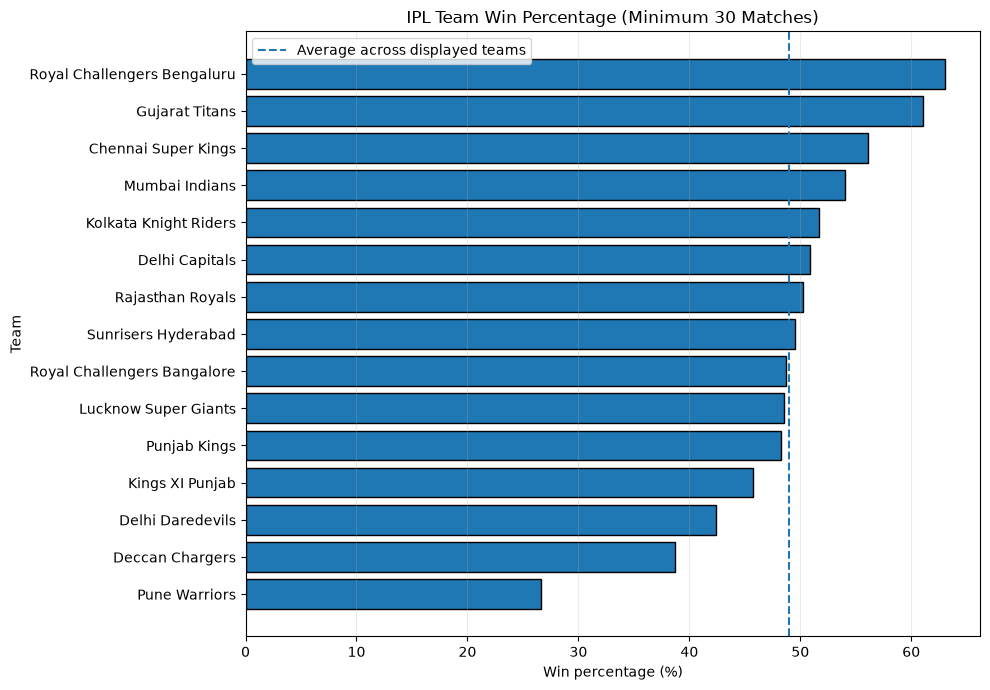

Chart saved to: c:\Users\amitb\Desktop\ME\Projects\Data_Analysis_Practice\cricket-analytics-lab\reports\charts\team_win_percentage.png


In [123]:
import matplotlib.pyplot as plt

# Calculate matches played and wins
team_results = matches_df.dropna(
    subset=["team1", "team2", "winner"]
).copy()

teams = pd.concat([
    team_results[["team1"]].rename(columns={"team1": "team"}),
    team_results[["team2"]].rename(columns={"team2": "team"})
])

matches_played = teams["team"].value_counts().rename("matches_played")

wins = (
    team_results["winner"]
    .value_counts()
    .rename("wins")
)

team_win_rate = pd.concat(
    [matches_played, wins], axis=1
).fillna(0)

team_win_rate["win_percentage"] = (
    team_win_rate["wins"] / team_win_rate["matches_played"] * 100
)

# Filter and sort
team_win_rate = (
    team_win_rate[team_win_rate["matches_played"] >= 30]
    .sort_values("win_percentage")
)

# Plot
plt.figure(figsize=(10, 7))

plt.barh(
    team_win_rate.index,
    team_win_rate["win_percentage"],
    edgecolor="black"
)

plt.axvline(
    team_win_rate["win_percentage"].mean(),
    linestyle="--",
    label="Average across displayed teams"
)

plt.title("IPL Team Win Percentage (Minimum 30 Matches)")
plt.xlabel("Win percentage (%)")
plt.ylabel("Team")
plt.legend()
plt.grid(axis="x", alpha=0.25)
plt.tight_layout()

chart_path = CHARTS_DIR / "team_win_percentage.png"
plt.savefig(chart_path, dpi=300, bbox_inches="tight")
plt.show()

print("Chart saved to:", chart_path)

In [125]:
print("Columns:", dismissal_summary.columns.tolist())
display(dismissal_summary.head())

Columns: ['dismissal_type', 'dismissals', 'batters', 'percentage']


,dismissal_type,dismissals,batters,percentage
0,bowled,2460,459,16.729004
1,caught,9321,606,63.386603
2,caught and bowled,410,209,2.788167
3,hit wicket,20,18,0.136008
4,lbw,883,297,6.004760


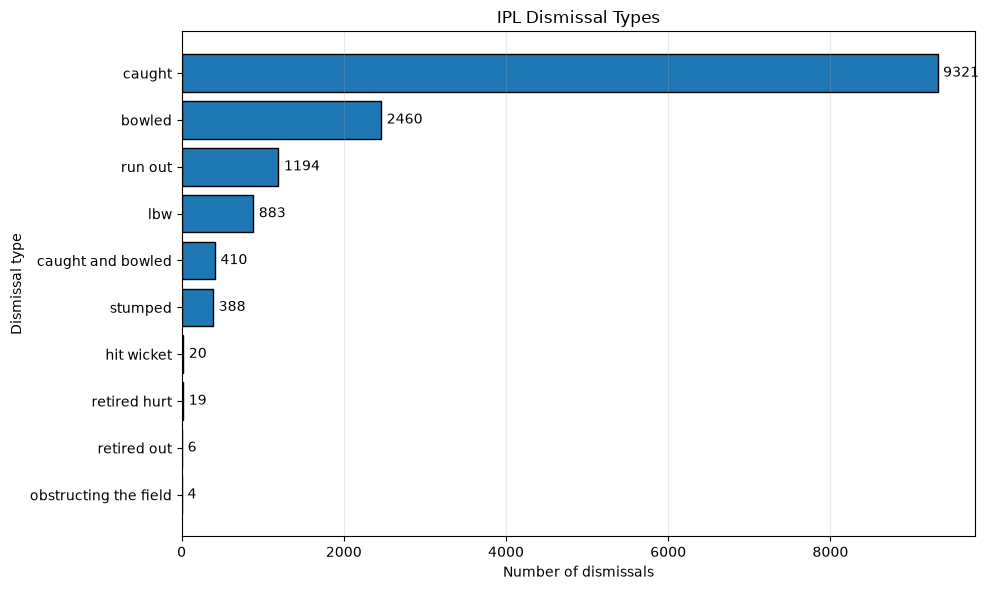

Total dismissal events: 14705
Chart saved to: c:\Users\amitb\Desktop\ME\Projects\Data_Analysis_Practice\cricket-analytics-lab\reports\charts\dismissal_types.png


In [126]:
import matplotlib.pyplot as plt

dismissal_chart = dismissal_summary.sort_values(
    "dismissals", ascending=True
)

plt.figure(figsize=(10, 6))

bars = plt.barh(
    dismissal_chart["dismissal_type"],
    dismissal_chart["dismissals"],
    edgecolor="black"
)

plt.bar_label(bars, fmt="%.0f", padding=4)
plt.title("IPL Dismissal Types")
plt.xlabel("Number of dismissals")
plt.ylabel("Dismissal type")
plt.grid(axis="x", alpha=0.25)
plt.tight_layout()

chart_path = CHARTS_DIR / "dismissal_types.png"
plt.savefig(chart_path, dpi=300, bbox_inches="tight")
plt.show()

print("Total dismissal events:", dismissal_chart["dismissals"].sum())
print("Chart saved to:", chart_path)

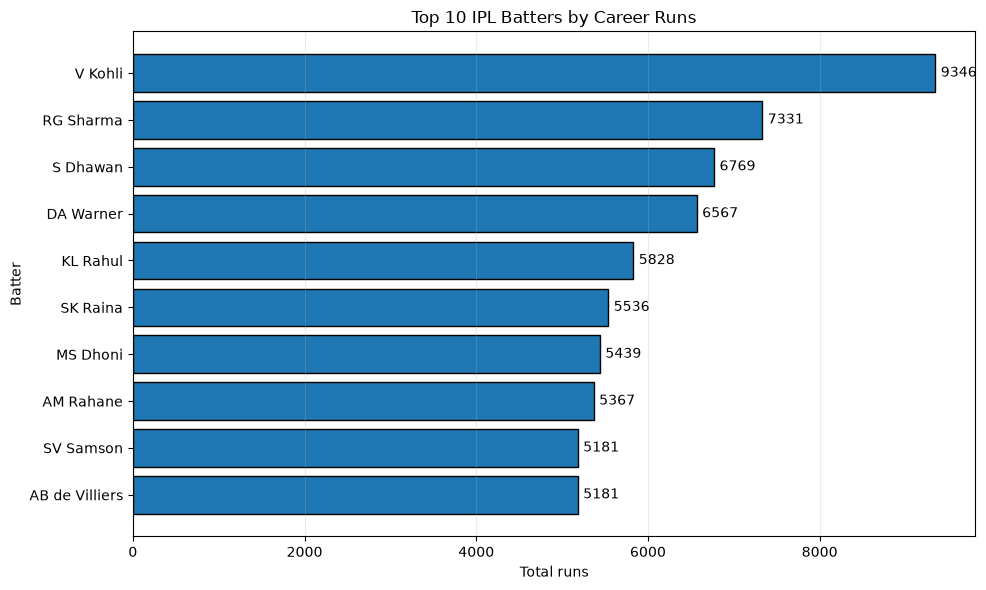

Chart saved to: c:\Users\amitb\Desktop\ME\Projects\Data_Analysis_Practice\cricket-analytics-lab\reports\charts\top_10_batters_by_runs.png


In [127]:
import matplotlib.pyplot as plt

# Select the top 10 run-scorers
top_batters = (
    correct_batting_totals
    .sort_values("phase_runs", ascending=False)
    .head(10)
    .sort_values("phase_runs", ascending=True)
)

plt.figure(figsize=(10, 6))

bars = plt.barh(
    top_batters["batter"],
    top_batters["phase_runs"],
    edgecolor="black"
)

plt.bar_label(bars, fmt="%.0f", padding=4)
plt.title("Top 10 IPL Batters by Career Runs")
plt.xlabel("Total runs")
plt.ylabel("Batter")
plt.grid(axis="x", alpha=0.25)
plt.tight_layout()

chart_path = CHARTS_DIR / "top_10_batters_by_runs.png"
plt.savefig(chart_path, dpi=300, bbox_inches="tight")
plt.show()

print("Chart saved to:", chart_path)

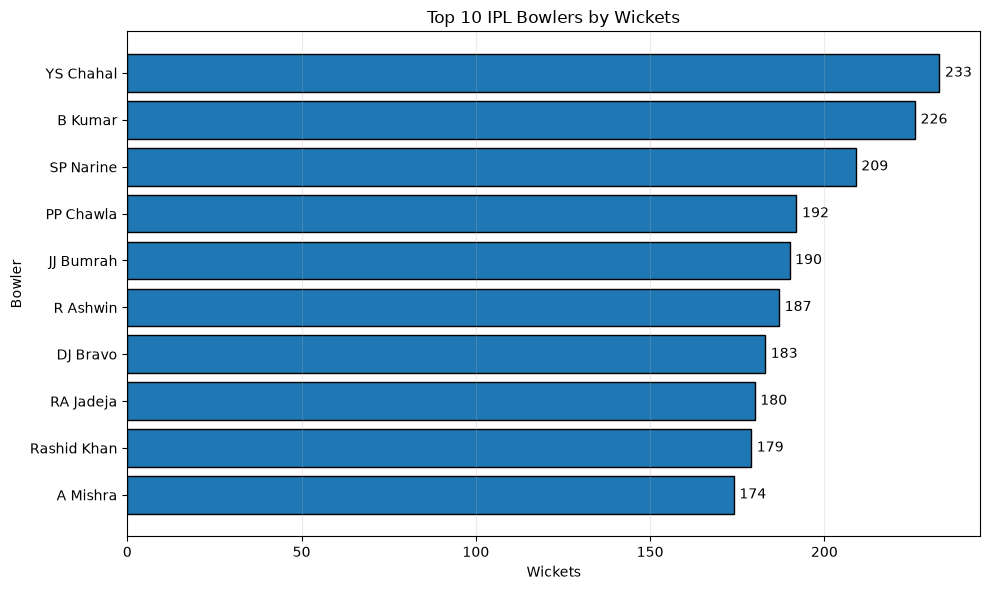

Chart saved to: c:\Users\amitb\Desktop\ME\Projects\Data_Analysis_Practice\cricket-analytics-lab\reports\charts\top_10_bowlers_by_wickets.png


In [128]:
import matplotlib.pyplot as plt

# Select the top 10 wicket-takers
top_bowlers = (
    bowling_summary
    .sort_values("wickets", ascending=False)
    .head(10)
    .sort_values("wickets", ascending=True)
)

plt.figure(figsize=(10, 6))

bars = plt.barh(
    top_bowlers["bowler"],
    top_bowlers["wickets"],
    edgecolor="black"
)

plt.bar_label(bars, fmt="%.0f", padding=4)
plt.title("Top 10 IPL Bowlers by Wickets")
plt.xlabel("Wickets")
plt.ylabel("Bowler")
plt.grid(axis="x", alpha=0.25)
plt.tight_layout()

chart_path = CHARTS_DIR / "top_10_bowlers_by_wickets.png"
plt.savefig(chart_path, dpi=300, bbox_inches="tight")
plt.show()

print("Chart saved to:", chart_path)

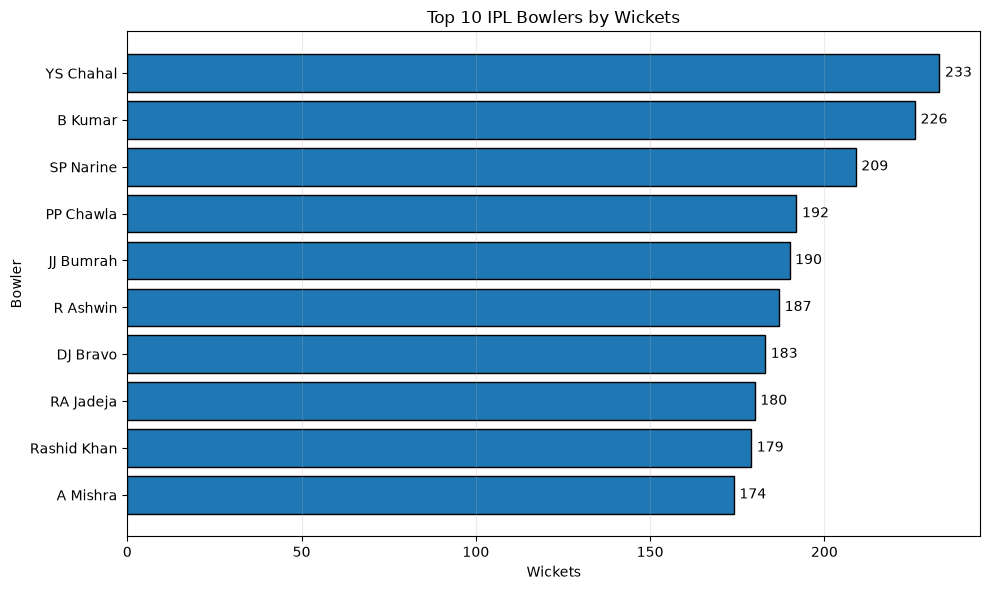

Chart saved to: c:\Users\amitb\Desktop\ME\Projects\Data_Analysis_Practice\cricket-analytics-lab\reports\charts\top_10_bowlers_by_wickets.png


In [129]:
import matplotlib.pyplot as plt

# Select the top 10 wicket-takers
top_bowlers = (
    bowling_summary
    .sort_values("wickets", ascending=False)
    .head(10)
    .sort_values("wickets", ascending=True)
)

plt.figure(figsize=(10, 6))

bars = plt.barh(
    top_bowlers["bowler"],
    top_bowlers["wickets"],
    edgecolor="black"
)

plt.bar_label(bars, fmt="%.0f", padding=4)
plt.title("Top 10 IPL Bowlers by Wickets")
plt.xlabel("Wickets")
plt.ylabel("Bowler")
plt.grid(axis="x", alpha=0.25)
plt.tight_layout()

chart_path = CHARTS_DIR / "top_10_bowlers_by_wickets.png"
plt.savefig(chart_path, dpi=300, bbox_inches="tight")
plt.show()

print("Chart saved to:", chart_path)

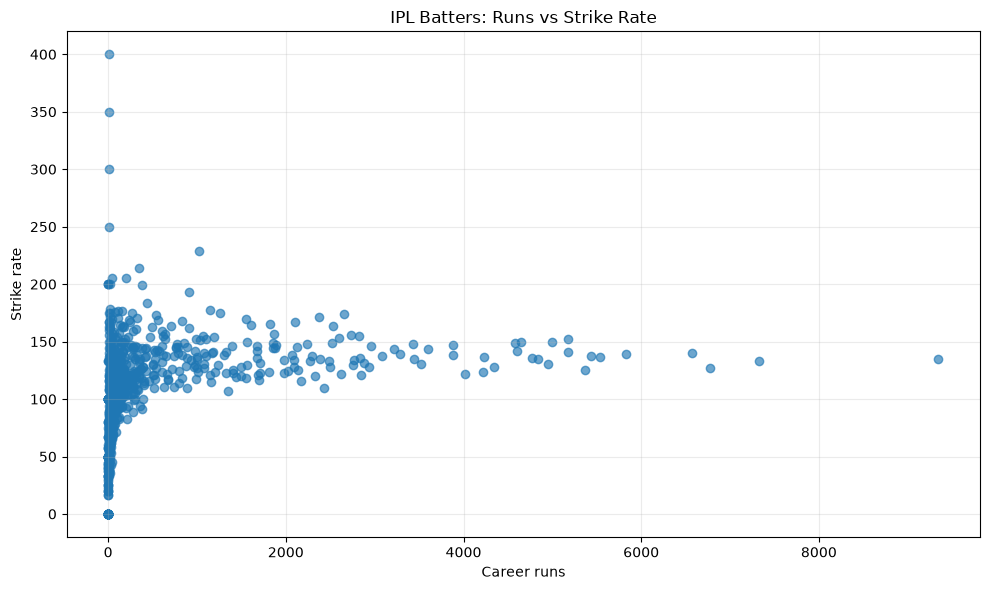

Players plotted: 739
Chart saved to: c:\Users\amitb\Desktop\ME\Projects\Data_Analysis_Practice\cricket-analytics-lab\reports\charts\batters_runs_vs_strike_rate.png


In [130]:
import matplotlib.pyplot as plt

# Use the existing batting totals
batting_scatter = correct_batting_totals.copy()

plt.figure(figsize=(10, 6))

plt.scatter(
    batting_scatter["phase_runs"],
    batting_scatter["phase_strike_rate"],
    alpha=0.65
)

plt.title("IPL Batters: Runs vs Strike Rate")
plt.xlabel("Career runs")
plt.ylabel("Strike rate")
plt.grid(alpha=0.25)
plt.tight_layout()

chart_path = CHARTS_DIR / "batters_runs_vs_strike_rate.png"
plt.savefig(chart_path, dpi=300, bbox_inches="tight")
plt.show()

print("Players plotted:", len(batting_scatter))
print("Chart saved to:", chart_path)

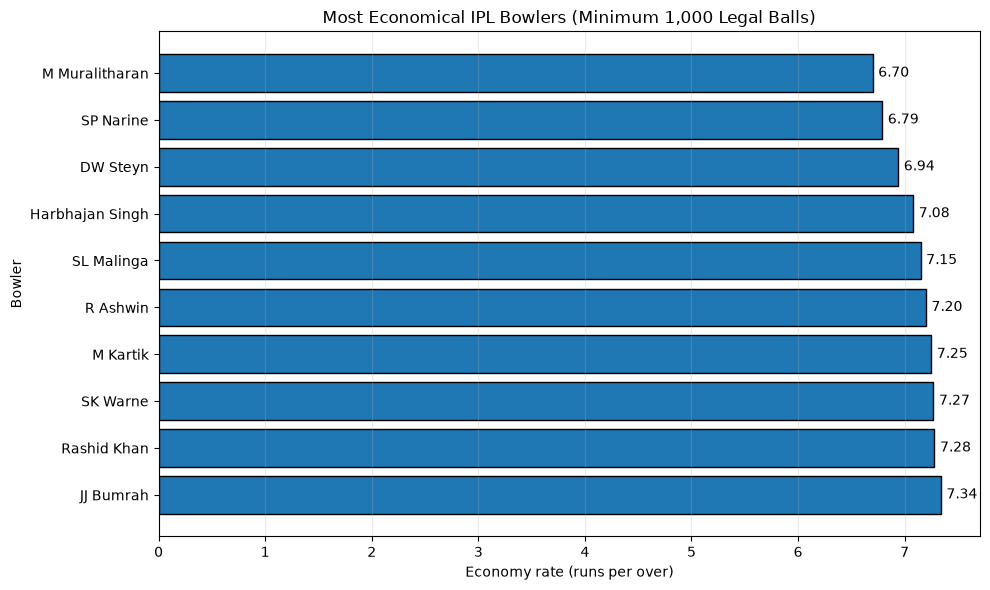

Qualified bowlers: 85
Chart saved to: c:\Users\amitb\Desktop\ME\Projects\Data_Analysis_Practice\cricket-analytics-lab\reports\charts\top_10_bowlers_by_economy.png


In [131]:
import matplotlib.pyplot as plt

# Filter bowlers with sufficient bowling volume
qualified_bowlers = bowling_summary[
    bowling_summary["legal_balls"] >= 1000
].copy()

# Select the 10 lowest economy rates
top_economy = (
    qualified_bowlers
    .sort_values("economy", ascending=True)
    .head(10)
    .sort_values("economy", ascending=False)
)

plt.figure(figsize=(10, 6))

bars = plt.barh(
    top_economy["bowler"],
    top_economy["economy"],
    edgecolor="black"
)

plt.bar_label(bars, fmt="%.2f", padding=4)
plt.title("Most Economical IPL Bowlers (Minimum 1,000 Legal Balls)")
plt.xlabel("Economy rate (runs per over)")
plt.ylabel("Bowler")
plt.grid(axis="x", alpha=0.25)
plt.tight_layout()

chart_path = CHARTS_DIR / "top_10_bowlers_by_economy.png"
plt.savefig(chart_path, dpi=300, bbox_inches="tight")
plt.show()

print("Qualified bowlers:", len(qualified_bowlers))
print("Chart saved to:", chart_path)

In [132]:
import matplotlib.pyplot as plt

# Inspect the existing consistency DataFrame
print("Columns:", player_consistency.columns.tolist())
display(player_consistency.head())

Columns: ['batter', 'innings', 'total_runs', 'average_runs', 'median_runs', 'standard_deviation', 'scores_50_plus', 'ducks', 'consistency_cv', '50_plus_percentage', 'duck_percentage']


,batter,innings,total_runs,average_runs,median_runs,standard_deviation,scores_50_plus,ducks,consistency_cv,50_plus_percentage,duck_percentage
0,A Ashish Reddy,23,280,12.173913,10.0,8.876179,0,0,0.73,0.0,0.0
1,A Badoni,56,1178,21.035714,18.0,18.592241,7,5,0.88,12.5,8.9
9,A Manohar,20,292,14.600000,10.0,15.628584,0,2,1.07,0.0,10.0
11,A Mishra,55,381,6.927273,4.0,7.564181,0,8,1.09,0.0,14.5
16,A Raghuvanshi,30,885,29.500000,27.0,21.883311,7,0,0.74,23.3,0.0


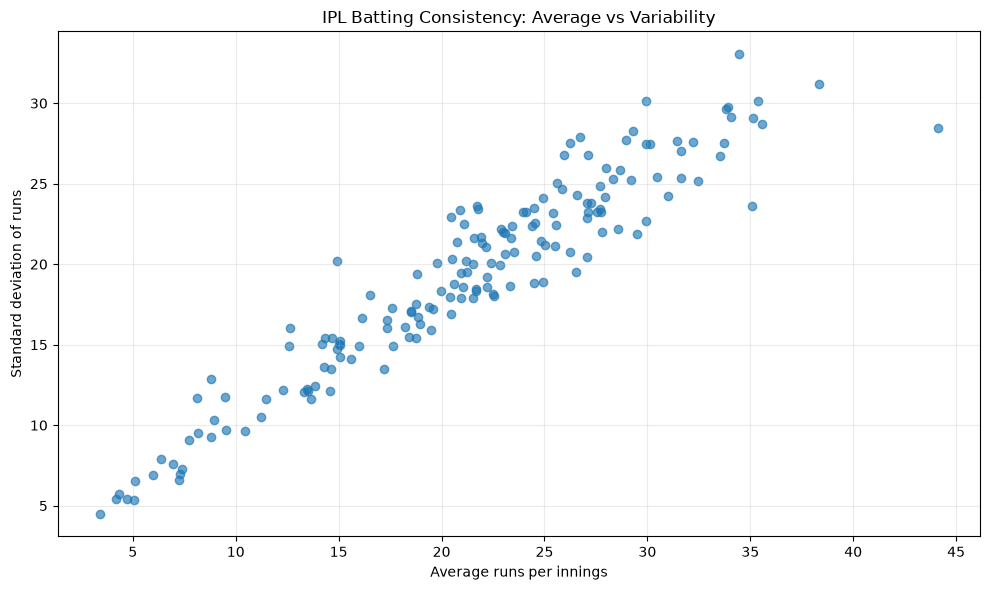

Players plotted: 168
Chart saved to: c:\Users\amitb\Desktop\ME\Projects\Data_Analysis_Practice\cricket-analytics-lab\reports\charts\batting_consistency.png


In [133]:
import matplotlib.pyplot as plt

# Filter players with a reasonable sample size
consistency_chart = player_consistency[
    player_consistency["innings"] >= 30
].copy()

plt.figure(figsize=(10, 6))

plt.scatter(
    consistency_chart["average_runs"],
    consistency_chart["standard_deviation"],
    alpha=0.65
)

plt.title("IPL Batting Consistency: Average vs Variability")
plt.xlabel("Average runs per innings")
plt.ylabel("Standard deviation of runs")
plt.grid(alpha=0.25)
plt.tight_layout()

chart_path = CHARTS_DIR / "batting_consistency.png"
plt.savefig(chart_path, dpi=300, bbox_inches="tight")
plt.show()

print("Players plotted:", len(consistency_chart))
print("Chart saved to:", chart_path)

,toss_decision,matches,toss_winner_match_wins,win_percentage
0,bat,408,185,45.343137
1,field,810,443,54.691358


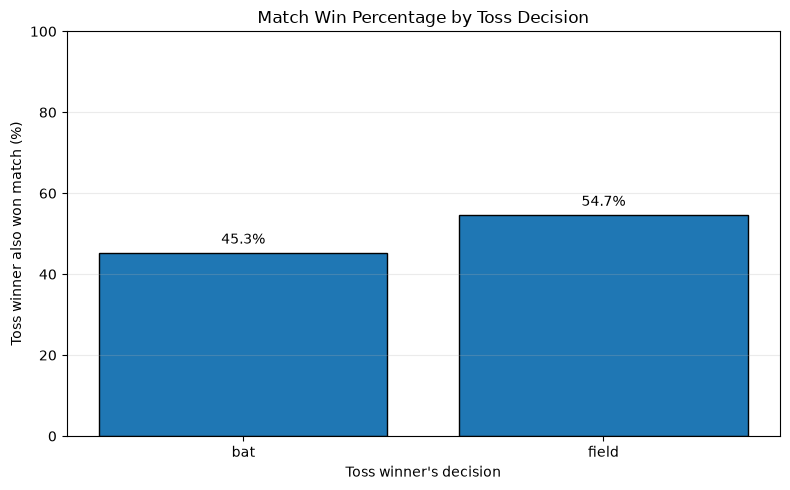

Chart saved to: c:\Users\amitb\Desktop\ME\Projects\Data_Analysis_Practice\cricket-analytics-lab\reports\charts\toss_decision_analysis.png


In [134]:
import matplotlib.pyplot as plt
import pandas as pd

# Keep matches with valid toss decisions and winners
toss_data = matches_df.dropna(
    subset=["toss_decision", "toss_winner", "winner"]
).copy()

# Did the toss-winning team also win the match?
toss_data["toss_winner_won_match"] = (
    toss_data["toss_winner"] == toss_data["winner"]
)

# Calculate wins and win percentage by toss decision
toss_summary = (
    toss_data.groupby("toss_decision")
    .agg(
        matches=("toss_winner_won_match", "size"),
        toss_winner_match_wins=("toss_winner_won_match", "sum")
    )
    .reset_index()
)

toss_summary["win_percentage"] = (
    toss_summary["toss_winner_match_wins"]
    / toss_summary["matches"] * 100
)

display(toss_summary)

# Plot
plt.figure(figsize=(8, 5))

bars = plt.bar(
    toss_summary["toss_decision"],
    toss_summary["win_percentage"],
    edgecolor="black"
)

plt.bar_label(bars, fmt="%.1f%%", padding=4)
plt.title("Match Win Percentage by Toss Decision")
plt.xlabel("Toss winner's decision")
plt.ylabel("Toss winner also won match (%)")
plt.ylim(0, 100)
plt.grid(axis="y", alpha=0.25)
plt.tight_layout()

chart_path = CHARTS_DIR / "toss_decision_analysis.png"
plt.savefig(chart_path, dpi=300, bbox_inches="tight")
plt.show()

print("Chart saved to:", chart_path)

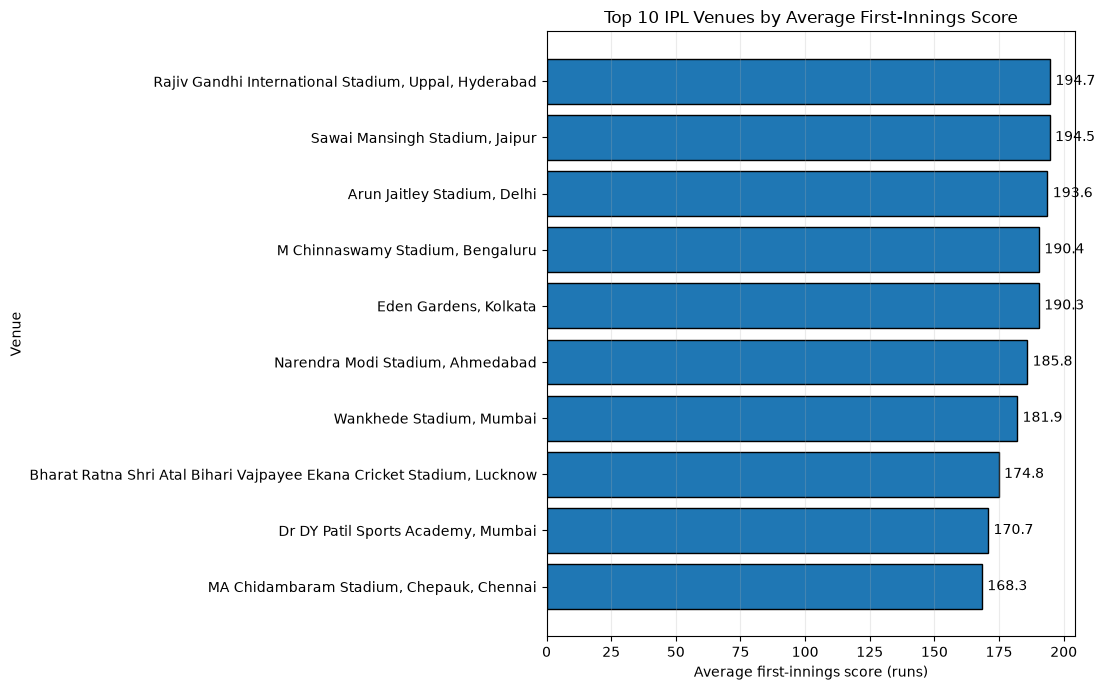

Qualifying venues: 22
Chart saved to: c:\Users\amitb\Desktop\ME\Projects\Data_Analysis_Practice\cricket-analytics-lab\reports\charts\venue_scoring_comparison.png


In [135]:
import matplotlib.pyplot as plt

# Calculate first-innings scoring by venue
venue_scores = (
    first_innings_analysis
    .merge(
        matches_df[["match_id", "venue"]],
        on="match_id",
        how="left"
    )
    .groupby("venue")
    .agg(
        innings=("first_innings_score", "count"),
        average_score=("first_innings_score", "mean"),
        median_score=("first_innings_score", "median")
    )
    .reset_index()
)

# Keep venues with sufficient data
venue_scores = venue_scores[
    venue_scores["innings"] >= 20
].copy()

# Select 10 highest-scoring venues
top_venues = (
    venue_scores
    .sort_values("average_score", ascending=False)
    .head(10)
    .sort_values("average_score", ascending=True)
)

plt.figure(figsize=(11, 7))

bars = plt.barh(
    top_venues["venue"],
    top_venues["average_score"],
    edgecolor="black"
)

plt.bar_label(bars, fmt="%.1f", padding=4)
plt.title("Top 10 IPL Venues by Average First-Innings Score")
plt.xlabel("Average first-innings score (runs)")
plt.ylabel("Venue")
plt.grid(axis="x", alpha=0.25)
plt.tight_layout()

chart_path = CHARTS_DIR / "venue_scoring_comparison.png"
plt.savefig(chart_path, dpi=300, bbox_inches="tight")
plt.show()

print("Qualifying venues:", len(venue_scores))
print("Chart saved to:", chart_path)

In [136]:
from pathlib import Path
from datetime import date

REPORT_PATH = REPORTS_DIR / "ipl_eda_report.md"

report = f"""# IPL Cricket Analytics — EDA Report

**Generated:** {date.today().isoformat()}

## 1. Project objective

Explore IPL match and ball-by-ball data to understand scoring trends,
team performance, batting, bowling, dismissals, toss decisions and venue patterns.

## 2. Dataset overview

- Matches in match-level dataset: {len(matches_df):,}
- Delivery records in phase-level dataset: {len(phase_df):,}
- Recorded dismissal events: {len(dismissals_df):,}

## 3. Key findings

### First-innings scoring
- Mean first-innings score: {first_innings_analysis['first_innings_score'].mean():.2f}
- Median first-innings score: {first_innings_analysis['first_innings_score'].median():.2f}

### Innings phases
The phase analysis compares scoring rates during Powerplay, Middle and Death overs.
See `charts/team_phase_run_rates.png`.

### Batting
The batting leaderboard and consistency analysis compare run volume, strike rate
and variation in innings scores.

### Bowling
The bowling analysis compares wicket totals and economy rates, subject to the
dataset's coverage and the bowling metric definitions used.

### Dismissals
The dismissal analysis compares the frequency of caught, bowled, run out, LBW
and other recorded dismissal types.

### Toss and venues
These charts describe associations in the observed matches. They do not establish
that a toss decision or venue alone causes a match outcome or scoring difference.

## 4. Generated charts

"""

chart_files = sorted(CHARTS_DIR.glob("*.png"))

for chart in chart_files:
    report += f"- `charts/{chart.name}`\\n"

report += """
## 5. Data limitations

- The season field currently uses calendar year as a proxy for IPL season.
- Historical team and venue aliases may be split across separate labels.
- Minimum sample thresholds affect which players, teams and venues are compared.
- Toss and venue comparisons are descriptive, not causal.
- Custom metrics must be documented and must not be presented as official metrics.
- Findings depend on the coverage and quality of the source data.

## 6. Next steps

1. Validate team and venue aliases.
2. Verify metric definitions and sample thresholds.
3. Add automated data-quality checks.
4. Review every chart and confirm its interpretation.
5. Export a final report after the findings have been validated.
"""

REPORT_PATH.write_text(report, encoding="utf-8")

print("Report created:", REPORT_PATH)
print("Charts referenced:", len(chart_files))
print("Report exists:", REPORT_PATH.exists())

Report created: c:\Users\amitb\Desktop\ME\Projects\Data_Analysis_Practice\cricket-analytics-lab\reports\ipl_eda_report.md
Charts referenced: 12
Report exists: True


In [137]:
# Validate generated charts and report references

chart_files = sorted(CHARTS_DIR.glob("*.png"))
report_text = REPORT_PATH.read_text(encoding="utf-8")

referenced_charts = [
    line.split("`")[1]
    for line in report_text.splitlines()
    if line.startswith("- `charts/")
]

missing_charts = [
    name.replace("charts/", "")
    for name in referenced_charts
    if not (CHARTS_DIR / name.replace("charts/", "")).exists()
]

print("Charts found:", len(chart_files))
print("Charts referenced in report:", len(referenced_charts))
print("Missing chart references:", missing_charts)
print("Report exists:", REPORT_PATH.exists())

Charts found: 12
Charts referenced in report: 1
Missing chart references: []
Report exists: True


In [138]:
# Display the chart list written in the report
for line in report_text.splitlines():
    if "charts/" in line:
        print(repr(line))

'See `charts/team_phase_run_rates.png`.'
'- `charts/batters_runs_vs_strike_rate.png`\\n- `charts/batting_consistency.png`\\n- `charts/dismissal_types.png`\\n- `charts/first_innings_score_distribution.png`\\n- `charts/first_innings_scoring_trends.png`\\n- `charts/team_phase_run_rates.png`\\n- `charts/team_win_percentage.png`\\n- `charts/top_10_batters_by_runs.png`\\n- `charts/top_10_bowlers_by_economy.png`\\n- `charts/top_10_bowlers_by_wickets.png`\\n- `charts/toss_decision_analysis.png`\\n- `charts/venue_scoring_comparison.png`\\n'


In [139]:
# Fix literal newline characters in the report
report_text = REPORT_PATH.read_text(encoding="utf-8")

report_text = report_text.replace("\\n", "\n")

REPORT_PATH.write_text(report_text, encoding="utf-8")

print("Report formatting fixed.")
print("Report saved to:", REPORT_PATH)

Report formatting fixed.
Report saved to: c:\Users\amitb\Desktop\ME\Projects\Data_Analysis_Practice\cricket-analytics-lab\reports\ipl_eda_report.md


In [140]:
chart_files = sorted(CHARTS_DIR.glob("*.png"))
report_text = REPORT_PATH.read_text(encoding="utf-8")

referenced_charts = [
    line.split("`")[1].replace("charts/", "")
    for line in report_text.splitlines()
    if line.startswith("- `charts/")
]

missing_charts = [
    name for name in referenced_charts
    if not (CHARTS_DIR / name).exists()
]

print("Charts found:", len(chart_files))
print("Charts referenced:", len(referenced_charts))
print("Missing charts:", missing_charts)
print("Unreferenced chart files:", sorted(
    set(p.name for p in chart_files) - set(referenced_charts)
))

Charts found: 12
Charts referenced: 12
Missing charts: []
Unreferenced chart files: []


In [141]:

# Phase 2 | Chapter 1 | Step 1: Batting metric validation

batting_audit = correct_batting_totals.copy()

# Recalculate strike rate independently
batting_audit["recalculated_sr"] = (
    batting_audit["phase_runs"]
    / batting_audit["phase_balls_faced"].replace(0, float("nan"))
    * 100
)

# Measure difference between existing and recalculated values
batting_audit["sr_difference"] = (
    batting_audit["phase_strike_rate"]
    - batting_audit["recalculated_sr"]
).abs()

print("Total batters:", len(batting_audit))
print("Duplicate batter rows:", batting_audit["batter"].duplicated().sum())
print("Missing runs:", batting_audit["phase_runs"].isna().sum())
print("Missing balls faced:", batting_audit["phase_balls_faced"].isna().sum())
print("Negative runs:", (batting_audit["phase_runs"] < 0).sum())
print("Negative balls faced:", (batting_audit["phase_balls_faced"] < 0).sum())
print("Strike rates differing by more than 0.01:",
      (batting_audit["sr_difference"] > 0.01).sum())

display(
    batting_audit.sort_values("sr_difference", ascending=False).head(10)
)


Total batters: 739
Duplicate batter rows: 0
Missing runs: 0
Missing balls faced: 0
Negative runs: 0
Negative balls faced: 0
Strike rates differing by more than 0.01: 0


,batter,phase_runs,phase_balls_faced,phase_strike_rate,recalculated_sr,sr_difference
63,AS Roy,78,64,121.88,121.875000,0.005000
60,AS Joseph,27,32,84.38,84.375000,0.005000
219,GJ Bailey,663,544,121.88,121.875000,0.005000
196,DW Steyn,167,160,104.38,104.375000,0.005000
518,RA Bawa,35,32,109.38,109.375000,0.005000
610,SO Hetmyer,1566,1049,149.29,149.285033,0.004967
96,Azmatullah Omarzai,151,101,149.50,149.504950,0.004950
102,B Lee,124,97,127.84,127.835052,0.004948
133,CA Lynn,1329,945,140.63,140.634921,0.004921
397,ML Hayden,1107,806,137.34,137.344913,0.004913


In [142]:

# Step 2: Validate bowling economy

bowling_audit = bowling_summary.copy()

bowling_audit["recalculated_economy"] = (
    bowling_audit["runs_conceded"]
    / bowling_audit["legal_balls"].replace(0, float("nan"))
    * 6
)

bowling_audit["economy_difference"] = (
    bowling_audit["economy"]
    - bowling_audit["recalculated_economy"]
).abs()

print("Total bowlers:", len(bowling_audit))
print("Duplicate bowler rows:", bowling_audit["bowler"].duplicated().sum())
print("Missing values:\n", bowling_audit[
    ["runs_conceded", "legal_balls", "wickets", "economy"]
].isna().sum())
print("Negative runs conceded:", (bowling_audit["runs_conceded"] < 0).sum())
print("Negative legal balls:", (bowling_audit["legal_balls"] < 0).sum())
print("Negative wickets:", (bowling_audit["wickets"] < 0).sum())
print("Economy differences greater than 0.01:",
      (bowling_audit["economy_difference"] > 0.01).sum())

display(
    bowling_audit.sort_values(
        "economy_difference", ascending=False
    ).head(10)
)


Total bowlers: 578
Duplicate bowler rows: 0
Missing values:
 runs_conceded    0
legal_balls      0
wickets          0
economy          0
dtype: int64
Negative runs conceded: 0
Negative legal balls: 0
Negative wickets: 0
Economy differences greater than 0.01: 0


,bowler,runs_conceded,legal_balls,wickets,overs,economy,recalculated_economy,economy_difference
464,SC Kuggeleijn,71,48,2,8.0,8.88,8.875000,0.005000
75,B Geeves,91,48,1,8.0,11.38,11.375000,0.005000
119,D Kalyankrishna,87,48,2,8.0,10.88,10.875000,0.005000
135,DJ Mitchell,97,48,1,8.0,12.12,12.125000,0.005000
99,C Nanda,57,48,2,8.0,7.12,7.125000,0.005000
242,KH Pandya,3410,2701,107,450.1,7.57,7.574972,0.004972
475,SM Curran,2033,1253,59,208.5,9.74,9.735036,0.004964
359,P Awana,1029,747,39,124.3,8.27,8.265060,0.004940
27,AD Mascarenhas,356,308,19,51.2,6.94,6.935065,0.004935
480,SN Thakur,3514,2202,119,367.0,9.57,9.574932,0.004932


In [143]:

# Step 3: Core metric integrity checks

print("=== BATTING AUDIT ===")
print("Duplicate batters:", correct_batting_totals["batter"].duplicated().sum())
print("Missing batter names:", correct_batting_totals["batter"].isna().sum())
print("Zero-ball innings totals:",
      (correct_batting_totals["phase_balls_faced"] == 0).sum())
print("Negative runs:",
      (correct_batting_totals["phase_runs"] < 0).sum())

print("\n=== BOWLING AUDIT ===")
print("Duplicate bowlers:", bowling_summary["bowler"].duplicated().sum())
print("Missing bowler names:", bowling_summary["bowler"].isna().sum())
print("Zero legal balls:",
      (bowling_summary["legal_balls"] == 0).sum())
print("Negative runs conceded:",
      (bowling_summary["runs_conceded"] < 0).sum())
print("Negative wickets:",
      (bowling_summary["wickets"] < 0).sum())


=== BATTING AUDIT ===
Duplicate batters: 0
Missing batter names: 0
Zero-ball innings totals: 0
Negative runs: 0

=== BOWLING AUDIT ===
Duplicate bowlers: 0
Missing bowler names: 0
Zero legal balls: 0
Negative runs conceded: 0
Negative wickets: 0


In [144]:

# Step 4: Inspect dismissal data before calculating batting average

print("Dismissal table shape:", dismissals_df.shape)
print("Columns:", dismissals_df.columns.tolist())

print("\nDismissal types:")
display(dismissals_df["dismissal_type"].value_counts().to_frame("count"))

print("\nSample dismissal records:")
display(dismissals_df.head(10))


Dismissal table shape: (14705, 6)
Columns: ['match_id', 'innings', 'batter_out', 'dismissal_type', 'bowler', 'batting_team']

Dismissal types:


,count
dismissal_type,
caught,9321
bowled,2460
run out,1194
lbw,883
caught and bowled,410
stumped,388
hit wicket,20
retired hurt,19
retired out,6



Sample dismissal records:


,match_id,innings,batter_out,dismissal_type,bowler,batting_team
0,1082591,1,DA Warner,caught,A Choudhary,Sunrisers Hyderabad
1,1082591,1,S Dhawan,caught,STR Binny,Sunrisers Hyderabad
2,1082591,1,MC Henriques,caught,YS Chahal,Sunrisers Hyderabad
3,1082591,1,Yuvraj Singh,bowled,TS Mills,Sunrisers Hyderabad
4,1082591,2,Mandeep Singh,bowled,Rashid Khan,Royal Challengers Bangalore
5,1082591,2,CH Gayle,caught,DJ Hooda,Royal Challengers Bangalore
6,1082591,2,KM Jadhav,run out,MC Henriques,Royal Challengers Bangalore
7,1082591,2,TM Head,caught,Rashid Khan,Royal Challengers Bangalore
8,1082591,2,Sachin Baby,caught,Bipul Sharma,Royal Challengers Bangalore
9,1082591,2,STR Binny,caught,B Kumar,Royal Challengers Bangalore


In [145]:

# Step 5: Calculate official-style batting averages

# Dismissals that count as the batter being out
not_out_exceptions = {
    "retired hurt",
    "obstructing the field",
    "retired out"
}

counted_dismissals = dismissals_df[
    ~dismissals_df["dismissal_type"].str.lower().isin(not_out_exceptions)
]

dismissal_counts = (
    counted_dismissals.groupby("batter_out")
    .size()
    .rename("times_dismissed")
)

batting_average_df = correct_batting_totals[
    ["batter", "phase_runs"]
].copy()

batting_average_df = batting_average_df.merge(
    dismissal_counts,
    left_on="batter",
    right_index=True,
    how="left"
)

batting_average_df["times_dismissed"] = (
    batting_average_df["times_dismissed"].fillna(0).astype(int)
)

batting_average_df["batting_average"] = (
    batting_average_df["phase_runs"]
    / batting_average_df["times_dismissed"].replace(0, float("nan"))
)

display(
    batting_average_df.sort_values(
        "batting_average", ascending=False, na_position="last"
    ).head(15).round(2)
)


,batter,phase_runs,times_dismissed,batting_average
713,Vivrant Sharma,69,1,69.00
402,MN van Wyk,167,3,55.67
103,B Sai Sudharsan,2515,51,49.31
311,KL Rahul,5828,128,45.53
35,AC Voges,181,4,45.25
485,PR Veer,90,2,45.00
182,DP Conway,1080,24,45.00
699,V Suryavanshi,1028,23,44.70
125,C Connolly,491,11,44.64
231,HM Amla,577,13,44.38


In [146]:

# Step 6: Audit batting-average coverage and sample sizes

print("Batting totals rows:", len(correct_batting_totals))
print("Dismissal events:", len(dismissals_df))

print("\nTop averages with limited dismissals:")
display(
    batting_average_df[
        batting_average_df["times_dismissed"] < 10
    ].sort_values("batting_average", ascending=False).head(15).round(2)
)

print("\nEstablished batters (at least 50 dismissals):")
display(
    batting_average_df[
        batting_average_df["times_dismissed"] >= 50
    ].sort_values("batting_average", ascending=False).head(15).round(2)
)


Batting totals rows: 739
Dismissal events: 14705

Top averages with limited dismissals:


,batter,phase_runs,times_dismissed,batting_average
713,Vivrant Sharma,69,1,69.00
402,MN van Wyk,167,3,55.67
35,AC Voges,181,4,45.25
485,PR Veer,90,2,45.00
249,Iqbal Abdulla,88,2,44.00
472,PD Collingwood,203,5,40.60
53,AN Ahmed,36,1,36.00
634,Salil Arora,35,1,35.00
105,B Sumanth,35,1,35.00
330,Kartik Sharma,295,9,32.78



Established batters (at least 50 dismissals):


,batter,phase_runs,times_dismissed,batting_average
103,B Sai Sudharsan,2515,51,49.31
311,KL Rahul,5828,128,45.53
225,H Klaasen,2104,50,42.08
694,V Kohli,9346,231,40.46
652,Shubman Gill,4598,114,40.33
159,DA Warner,6567,164,40.04
31,AB de Villiers,5181,130,39.85
282,JP Duminy,2029,51,39.78
135,CH Gayle,4997,126,39.66
594,SE Marsh,2489,63,39.51


In [147]:

# Step 7: Validate bowling strike rate

bowling_audit = bowling_summary.copy()

bowling_audit["recalculated_bowling_sr"] = (
    bowling_audit["legal_balls"]
    / bowling_audit["wickets"].replace(0, float("nan"))
)

bowling_audit["bowling_sr_difference"] = (
    bowling_audit["recalculated_bowling_sr"]
    - (
        bowling_audit["legal_balls"]
        / bowling_audit["wickets"].replace(0, float("nan"))
    )
).abs()

print("Total bowlers:", len(bowling_audit))
print("Missing bowler names:", bowling_audit["bowler"].isna().sum())
print("Zero wickets:", (bowling_audit["wickets"] == 0).sum())
print("Negative legal balls:", (bowling_audit["legal_balls"] < 0).sum())
print("Negative wickets:", (bowling_audit["wickets"] < 0).sum())

display(
    bowling_audit.sort_values(
        "recalculated_bowling_sr", ascending=True
    )[
        ["bowler", "legal_balls", "wickets", "recalculated_bowling_sr"]
    ].head(15).round(2)
)


Total bowlers: 578
Missing bowler names: 0
Zero wickets: 85
Negative legal balls: 0
Negative wickets: 0


,bowler,legal_balls,wickets,recalculated_bowling_sr
24,AC Gilchrist,1,1,1.00
116,D Brevis,3,1,3.00
497,Sachin Baby,10,2,5.00
490,SS Mundhe,6,1,6.00
268,LA Carseldine,6,1,6.00
39,AM Rahane,6,1,6.00
127,DAJ Bracewell,24,3,8.00
432,Ramandeep Singh,56,7,8.00
508,Shoaib Akhtar,42,5,8.40
521,T Stubbs,36,4,9.00


In [148]:

# Step 8: Filter bowlers by sample size

MIN_WICKETS = 60

qualified_bowlers = bowling_audit[
    bowling_audit["wickets"] >= MIN_WICKETS
].copy()

qualified_bowlers = qualified_bowlers.sort_values(
    "recalculated_bowling_sr"
)

print("Minimum wickets required:", MIN_WICKETS)
print("Qualified bowlers:", len(qualified_bowlers))

display(
    qualified_bowlers[
        ["bowler", "legal_balls", "wickets",
         "recalculated_bowling_sr", "economy"]
    ].head(15).round(2).reset_index(drop=True)
)


Minimum wickets required: 60
Qualified bowlers: 72


,bowler,legal_balls,wickets,recalculated_bowling_sr,economy
0,AD Russell,1806,123,14.68,9.51
1,K Rabada,2299,151,15.23,8.79
2,MA Starc,1196,76,15.74,8.83
3,Imran Tahir,1316,82,16.05,7.76
4,JR Hazlewood,1176,72,16.33,8.62
5,HV Patel,2506,151,16.60,8.92
6,SL Malinga,2827,170,16.63,7.15
7,DJ Bravo,3120,183,17.05,8.38
8,YS Chahal,4037,233,17.33,8.05
9,JO Holder,1225,70,17.50,8.58


In [149]:

# Step 9: Audit bowler-credited dismissal types

non_bowler_wickets = {
    "run out",
    "retired hurt",
    "obstructing the field",
    "retired out"
}

dismissal_audit = dismissals_df.copy()
dismissal_audit["dismissal_type"] = (
    dismissal_audit["dismissal_type"].str.lower().str.strip()
)

print("All dismissal events:", len(dismissal_audit))
print("\nDismissal types excluded from bowler wickets:")
display(
    dismissal_audit[
        dismissal_audit["dismissal_type"].isin(non_bowler_wickets)
    ]["dismissal_type"].value_counts().to_frame("count")
)

print("\nAll dismissal types:")
display(
    dismissal_audit["dismissal_type"]
    .value_counts()
    .to_frame("count")
)


All dismissal events: 14705

Dismissal types excluded from bowler wickets:


,count
dismissal_type,
run out,1194
retired hurt,19
retired out,6
obstructing the field,4



All dismissal types:


,count
dismissal_type,
caught,9321
bowled,2460
run out,1194
lbw,883
caught and bowled,410
stumped,388
hit wicket,20
retired hurt,19
retired out,6


In [150]:

# Step 10: Reconcile credited wickets against bowling_summary

credited_dismissals = dismissal_audit[
    ~dismissal_audit["dismissal_type"].isin(non_bowler_wickets)
    & dismissal_audit["bowler"].notna()
]

credited_wickets_check = (
    credited_dismissals.groupby("bowler")
    .size()
    .rename("recalculated_wickets")
    .to_frame()
    .join(bowling_summary.set_index("bowler")["wickets"].rename("stored_wickets"))
)

credited_wickets_check["difference"] = (
    credited_wickets_check["recalculated_wickets"]
    - credited_wickets_check["stored_wickets"]
)

print("Bowler records compared:", len(credited_wickets_check))
print("Wicket mismatches:", (credited_wickets_check["difference"] != 0).sum())

display(
    credited_wickets_check[
        credited_wickets_check["difference"] != 0
    ].head(20)
)


Bowler records compared: 493
Wicket mismatches: 0


,recalculated_wickets,stored_wickets,difference
bowler,,,


In [151]:

# Chapter 2 | Step 1: Inspect phase-level data

print("Dataset shape:", phase_df.shape)
print("\nColumns:", phase_df.columns.tolist())

print("\nPhase distribution:")
display(phase_df["phase"].value_counts().to_frame("deliveries"))

print("\nSample records:")
display(phase_df.head(10))


Dataset shape: (295732, 9)

Columns: ['match_id', 'innings', 'batting_team', 'over_number', 'phase', 'runs', 'legal_ball', 'wicket', 'team_normalized']

Phase distribution:


,deliveries
phase,
Middle,135655
Powerplay,92904
Death,67173



Sample records:


,match_id,innings,batting_team,over_number,phase,runs,legal_ball,wicket,team_normalized
0,1082591,1,Sunrisers Hyderabad,1,Powerplay,0,1,0,Sunrisers Hyderabad
1,1082591,1,Sunrisers Hyderabad,1,Powerplay,0,1,0,Sunrisers Hyderabad
2,1082591,1,Sunrisers Hyderabad,1,Powerplay,4,1,0,Sunrisers Hyderabad
3,1082591,1,Sunrisers Hyderabad,1,Powerplay,0,1,0,Sunrisers Hyderabad
4,1082591,1,Sunrisers Hyderabad,1,Powerplay,2,0,0,Sunrisers Hyderabad
5,1082591,1,Sunrisers Hyderabad,1,Powerplay,0,1,0,Sunrisers Hyderabad
6,1082591,1,Sunrisers Hyderabad,1,Powerplay,1,1,0,Sunrisers Hyderabad
7,1082591,1,Sunrisers Hyderabad,2,Powerplay,1,1,0,Sunrisers Hyderabad
8,1082591,1,Sunrisers Hyderabad,2,Powerplay,4,1,0,Sunrisers Hyderabad
9,1082591,1,Sunrisers Hyderabad,2,Powerplay,1,0,0,Sunrisers Hyderabad


In [152]:

# Chapter 2 | Step 2: Team performance by phase

team_phase_metrics = (
    phase_df.groupby(["team_normalized", "phase"], as_index=False)
    .agg(
        total_runs=("runs", "sum"),
        legal_balls=("legal_ball", "sum"),
        wickets=("wicket", "sum"),
        deliveries=("match_id", "size")
    )
)

team_phase_metrics["run_rate"] = (
    team_phase_metrics["total_runs"]
    / team_phase_metrics["legal_balls"].replace(0, float("nan"))
    * 6
)

display(
    team_phase_metrics.sort_values(
        ["phase", "run_rate"], ascending=[True, False]
    ).round(2).head(20)
)


,team_normalized,phase,total_runs,legal_balls,wickets,deliveries,run_rate
12,Gujarat Titans,Death,3660,2036,166,2189,10.79
39,Royal Challengers Bengaluru,Death,12652,7143,599,7522,10.63
21,Lucknow Super Giants,Death,3448,1962,165,2119,10.54
0,Chennai Super Kings,Death,12392,7145,496,7550,10.41
24,Mumbai Indians,Death,13238,7636,670,8064,10.40
18,Kolkata Knight Riders,Death,11156,6690,577,7061,10.01
30,Punjab Kings,Death,11933,7186,610,7540,9.96
36,Rising Pune Supergiant,Death,1211,732,65,764,9.93
6,Delhi Capitals,Death,11502,7010,575,7354,9.84
33,Rajasthan Royals,Death,10372,6383,542,6689,9.75


In [153]:

# Step 3: Compare each team's run rate across phases

phase_rate_comparison = team_phase_metrics.pivot(
    index="team_normalized",
    columns="phase",
    values="run_rate"
)

phase_rate_comparison = phase_rate_comparison[
    ["Powerplay", "Middle", "Death"]
]

phase_rate_comparison["death_vs_powerplay"] = (
    phase_rate_comparison["Death"]
    - phase_rate_comparison["Powerplay"]
)

display(
    phase_rate_comparison.sort_values(
        "death_vs_powerplay", ascending=False
    ).round(2)
)


phase,Powerplay,Middle,Death,death_vs_powerplay
team_normalized,,,,
Royal Challengers Bengaluru,7.98,8.05,10.63,2.64
Chennai Super Kings,7.90,7.87,10.41,2.51
Mumbai Indians,7.97,7.91,10.40,2.44
Gujarat Titans,8.65,8.80,10.79,2.13
Rising Pune Supergiant,7.91,7.34,9.93,2.02
Kolkata Knight Riders,8.05,7.89,10.01,1.95
Lucknow Super Giants,8.62,8.62,10.54,1.92
Delhi Capitals,8.05,7.78,9.84,1.80
Punjab Kings,8.24,8.13,9.96,1.72


In [154]:

# Step 4: Inspect batter-level phase data

print("Dataset shape:", batter_phase_df.shape)
print("\nColumns:", batter_phase_df.columns.tolist())
display(batter_phase_df.head(10))


Dataset shape: (295732, 5)

Columns: ['match_id', 'batter', 'phase', 'runs', 'balls_faced']


,match_id,batter,phase,runs,balls_faced
0,1082591,DA Warner,Powerplay,0,1
1,1082591,DA Warner,Powerplay,0,1
2,1082591,DA Warner,Powerplay,4,1
3,1082591,DA Warner,Powerplay,0,1
4,1082591,DA Warner,Powerplay,0,0
5,1082591,S Dhawan,Powerplay,0,1
6,1082591,S Dhawan,Powerplay,0,1
7,1082591,S Dhawan,Powerplay,1,1
8,1082591,DA Warner,Powerplay,4,1
9,1082591,DA Warner,Powerplay,0,1


In [155]:

# Step 5: Batter performance by phase

batter_phase_summary = (
    batter_phase_df.groupby(["batter", "phase"], as_index=False)
    .agg(
        total_runs=("runs", "sum"),
        balls_faced=("balls_faced", "sum"),
        matches=("match_id", "nunique")
    )
)

batter_phase_summary["strike_rate"] = (
    batter_phase_summary["total_runs"]
    / batter_phase_summary["balls_faced"].replace(0, float("nan"))
    * 100
)

MIN_BALLS = 100

qualified_batters = batter_phase_summary[
    batter_phase_summary["balls_faced"] >= MIN_BALLS
].copy()

for phase in ["Powerplay", "Middle", "Death"]:
    print(f"\n=== Top 10: {phase} ===")
    display(
        qualified_batters[
            qualified_batters["phase"] == phase
        ]
        .sort_values("strike_rate", ascending=False)
        [["batter", "total_runs", "balls_faced", "matches", "strike_rate"]]
        .head(10)
        .round(2)
        .reset_index(drop=True)
    )



=== Top 10: Powerplay ===


,batter,total_runs,balls_faced,matches,strike_rate
0,V Suryavanshi,665,293,23,226.96
1,J Fraser-McGurk,298,144,15,206.94
2,JP Inglis,307,155,13,198.06
3,Priyansh Arya,678,355,31,190.99
4,A Mhatre,275,145,12,189.66
5,FH Allen,207,113,11,183.19
6,TM Head,1010,568,47,177.82
7,PD Salt,840,488,38,172.13
8,Abhishek Sharma,1387,807,68,171.87
9,SP Narine,1174,690,71,170.14



=== Top 10: Middle ===


,batter,total_runs,balls_faced,matches,strike_rate
0,V Suryavanshi,334,146,12,228.77
1,Priyansh Arya,231,116,9,199.14
2,RD Rickelton,258,141,13,182.98
3,PD Salt,383,214,17,178.97
4,Abhishek Sharma,796,455,45,174.95
5,SP Narine,486,279,38,174.19
6,V Sehwag,1062,615,42,172.68
7,RM Patidar,1102,641,46,171.92
8,P Simran Singh,634,392,33,161.73
9,C Connolly,260,161,10,161.49



=== Top 10: Death ===


,batter,total_runs,balls_faced,matches,strike_rate
0,AB de Villiers,1868,838,81,222.91
1,LS Livingstone,345,159,20,216.98
2,RM Patidar,267,124,19,215.32
3,B Sai Sudharsan,308,149,19,206.71
4,MA Agarwal,252,122,15,206.56
5,Q de Kock,240,117,14,205.13
6,CH Gayle,581,284,28,204.58
7,RR Pant,1095,540,63,202.78
8,T Stubbs,546,275,29,198.55
9,Tilak Varma,543,274,33,198.18


In [156]:
# Step 6: Compare batter performance across all phases

phase_comparison = batter_phase_summary.pivot(
    index="batter",
    columns="phase",
    values="strike_rate"
)

phase_balls = batter_phase_summary.pivot(
    index="batter",
    columns="phase",
    values="balls_faced"
)

# Require at least 100 balls in EACH phase
qualified_all_phase = phase_comparison[
    (phase_balls["Powerplay"] >= 100)
    & (phase_balls["Middle"] >= 100)
    & (phase_balls["Death"] >= 100)
].copy()

qualified_all_phase["average_phase_sr"] = qualified_all_phase[
    ["Powerplay", "Middle", "Death"]
].mean(axis=1)

qualified_all_phase["weakest_phase_sr"] = qualified_all_phase[
    ["Powerplay", "Middle", "Death"]
].min(axis=1)

display(
    qualified_all_phase.sort_values(
        "average_phase_sr", ascending=False
    ).head(15).round(2)
)

phase,Death,Middle,Powerplay,average_phase_sr,weakest_phase_sr
batter,,,,,
Abhishek Sharma,154.33,174.95,171.87,167.05,154.33
RM Patidar,215.32,171.92,113.02,166.75,113.02
CH Gayle,204.58,156.13,135.57,165.43,135.57
B Sai Sudharsan,206.71,148.25,138.53,164.50,138.53
Naman Dhir,193.46,151.83,142.24,162.51,142.24
LS Livingstone,216.98,137.91,132.59,162.50,132.59
N Pooran,177.58,158.66,149.02,161.75,149.02
JC Buttler,192.81,144.06,141.82,159.56,141.82
AB de Villiers,222.91,131.29,120.68,158.30,120.68


In [157]:
# Step 7: Calculate phase-to-phase strike-rate variation

qualified_all_phase["phase_sr_range"] = (
    qualified_all_phase[["Powerplay", "Middle", "Death"]].max(axis=1)
    - qualified_all_phase[["Powerplay", "Middle", "Death"]].min(axis=1)
)

display(
    qualified_all_phase.sort_values(
        "phase_sr_range", ascending=True
    )[
        [
            "Powerplay",
            "Middle",
            "Death",
            "average_phase_sr",
            "weakest_phase_sr",
            "phase_sr_range"
        ]
    ]
    .head(15)
    .round(2)
)

phase,Powerplay,Middle,Death,average_phase_sr,weakest_phase_sr,phase_sr_range
batter,,,,,,
RA Tripathi,139.53,134.90,145.03,139.82,134.90,10.13
MR Marsh,156.24,139.82,152.87,149.64,139.82,16.42
Abhishek Sharma,171.87,174.95,154.33,167.05,154.33,20.61
Shubman Gill,134.56,147.20,155.92,145.90,134.56,21.36
R Parag,138.41,138.24,160.39,145.68,138.24,22.15
VR Iyer,138.48,140.59,160.74,146.60,138.48,22.26
G Gambhir,121.90,123.70,145.16,130.25,121.90,23.27
YK Pathan,147.35,133.56,160.63,147.18,133.56,27.06
DR Smith,124.28,148.30,151.35,141.31,124.28,27.07


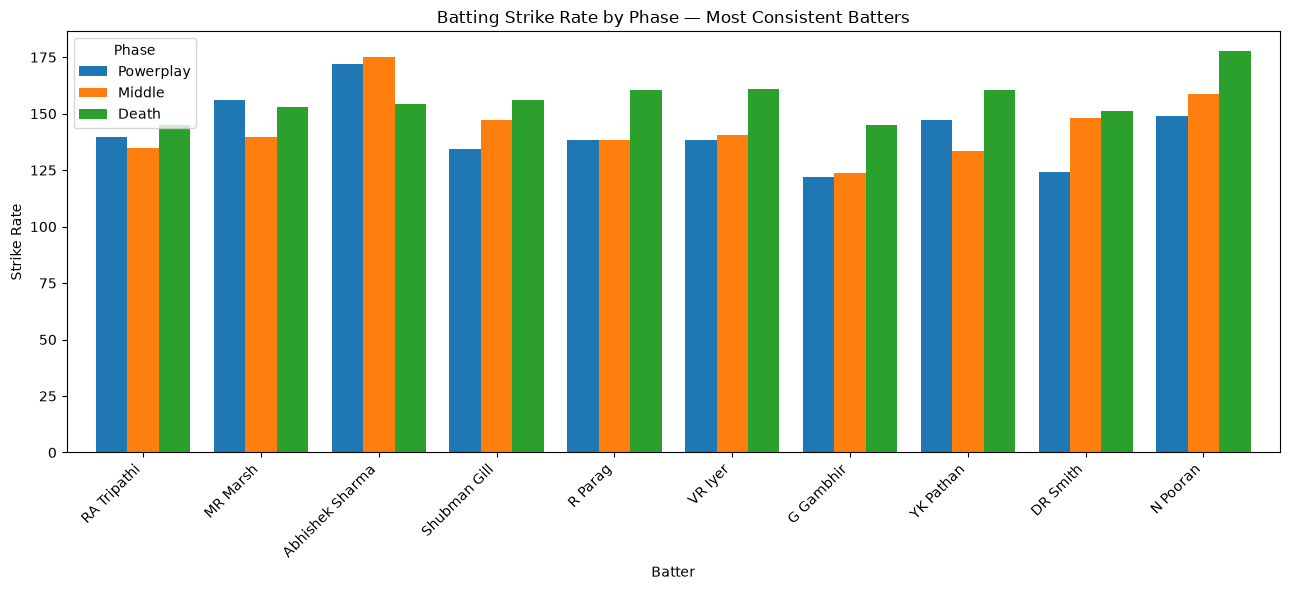

In [158]:
# Step 8: Visualize phase-by-phase strike rates

import matplotlib.pyplot as plt

top_consistent = (
    qualified_all_phase
    .sort_values("phase_sr_range", ascending=True)
    .head(10)
)

top_consistent[["Powerplay", "Middle", "Death"]].plot(
    kind="bar",
    figsize=(13, 6),
    width=0.8
)

plt.title("Batting Strike Rate by Phase — Most Consistent Batters")
plt.xlabel("Batter")
plt.ylabel("Strike Rate")
plt.xticks(rotation=45, ha="right")
plt.legend(title="Phase")
plt.tight_layout()
plt.show()

In [159]:
# Step 9: Identify each batter's strongest phase

phase_cols = ["Powerplay", "Middle", "Death"]

qualified_all_phase["best_phase"] = (
    qualified_all_phase[phase_cols].idxmax(axis=1)
)

qualified_all_phase["best_phase_sr"] = (
    qualified_all_phase[phase_cols].max(axis=1)
)

display(
    qualified_all_phase.sort_values(
        "best_phase_sr", ascending=False
    )[
        [
            "Powerplay",
            "Middle",
            "Death",
            "best_phase",
            "best_phase_sr",
            "weakest_phase_sr",
            "phase_sr_range"
        ]
    ]
    .head(15)
    .round(2)
)

phase,Powerplay,Middle,Death,best_phase,best_phase_sr,weakest_phase_sr,phase_sr_range
batter,,,,,,,
AB de Villiers,120.68,131.29,222.91,Death,222.91,120.68,102.23
LS Livingstone,132.59,137.91,216.98,Death,216.98,132.59,84.39
RM Patidar,113.02,171.92,215.32,Death,215.32,113.02,102.30
B Sai Sudharsan,138.53,148.25,206.71,Death,206.71,138.53,68.18
MA Agarwal,122.45,139.19,206.56,Death,206.56,122.45,84.10
Q de Kock,130.03,133.98,205.13,Death,205.13,130.03,75.10
CH Gayle,135.57,156.13,204.58,Death,204.58,135.57,69.01
RR Pant,118.36,135.74,202.78,Death,202.78,118.36,84.42
Tilak Varma,117.07,132.74,198.18,Death,198.18,117.07,81.10


In [160]:
# Step 10: Add phase-wise balls faced and runs

phase_runs = batter_phase_summary.pivot(
    index="batter",
    columns="phase",
    values="total_runs"
).add_suffix("_runs")

phase_balls = batter_phase_summary.pivot(
    index="batter",
    columns="phase",
    values="balls_faced"
).add_suffix("_balls")

phase_evidence = qualified_all_phase[
    ["Powerplay", "Middle", "Death",
     "average_phase_sr", "phase_sr_range"]
].join(phase_runs).join(phase_balls)

display(
    phase_evidence.sort_values(
        "Death", ascending=False
    )[
        [
            "Death_runs", "Death_balls",
            "Death", "Middle_runs", "Middle_balls",
            "Middle", "Powerplay_runs", "Powerplay_balls",
            "Powerplay", "average_phase_sr"
        ]
    ]
    .head(15)
    .round(2)
)

phase,Death_runs,Death_balls,Death,Middle_runs,Middle_balls,Middle,Powerplay_runs,Powerplay_balls,Powerplay,average_phase_sr
batter,,,,,,,,,,
AB de Villiers,1868.0,838.0,222.91,2572.0,1959.0,131.29,741.0,614.0,120.68,158.30
LS Livingstone,345.0,159.0,216.98,542.0,393.0,137.91,179.0,135.0,132.59,162.50
RM Patidar,267.0,124.0,215.32,1102.0,641.0,171.92,243.0,215.0,113.02,166.75
B Sai Sudharsan,308.0,149.0,206.71,1186.0,800.0,148.25,1021.0,737.0,138.53,164.50
MA Agarwal,252.0,122.0,206.56,1094.0,786.0,139.19,1418.0,1158.0,122.45,156.07
Q de Kock,240.0,117.0,205.13,1238.0,924.0,133.98,1966.0,1512.0,130.03,156.38
CH Gayle,581.0,284.0,204.58,2011.0,1288.0,156.13,2405.0,1774.0,135.57,165.43
RR Pant,1095.0,540.0,202.78,2294.0,1690.0,135.74,490.0,414.0,118.36,152.29
Tilak Varma,543.0,274.0,198.18,1123.0,846.0,132.74,192.0,164.0,117.07,149.33


In [161]:
# Step 11: Death-phase batting leaderboard

death_leaderboard = phase_evidence.reset_index()[
    [
        "batter",
        "Death_runs",
        "Death_balls",
        "Death"
    ]
].copy()

death_leaderboard = death_leaderboard[
    death_leaderboard["Death_balls"] >= 300
].copy()

death_leaderboard["Death_runs_per_100_balls"] = (
    death_leaderboard["Death_runs"]
    / death_leaderboard["Death_balls"]
    * 100
)

display(
    death_leaderboard.sort_values(
        "Death_runs", ascending=False
    ).head(15).round(2).reset_index(drop=True)
)

phase,batter,Death_runs,Death_balls,Death,Death_runs_per_100_balls
0,RA Jadeja,1922.0,1280.0,150.16,150.16
1,KD Karthik,1904.0,1098.0,173.41,173.41
2,AB de Villiers,1868.0,838.0,222.91,222.91
3,V Kohli,1573.0,835.0,188.38,188.38
4,RG Sharma,1527.0,843.0,181.14,181.14
5,HH Pandya,1510.0,895.0,168.72,168.72
6,DA Miller,1509.0,866.0,174.25,174.25
7,AT Rayudu,1179.0,698.0,168.91,168.91
8,YK Pathan,1126.0,701.0,160.63,160.63
9,RR Pant,1095.0,540.0,202.78,202.78


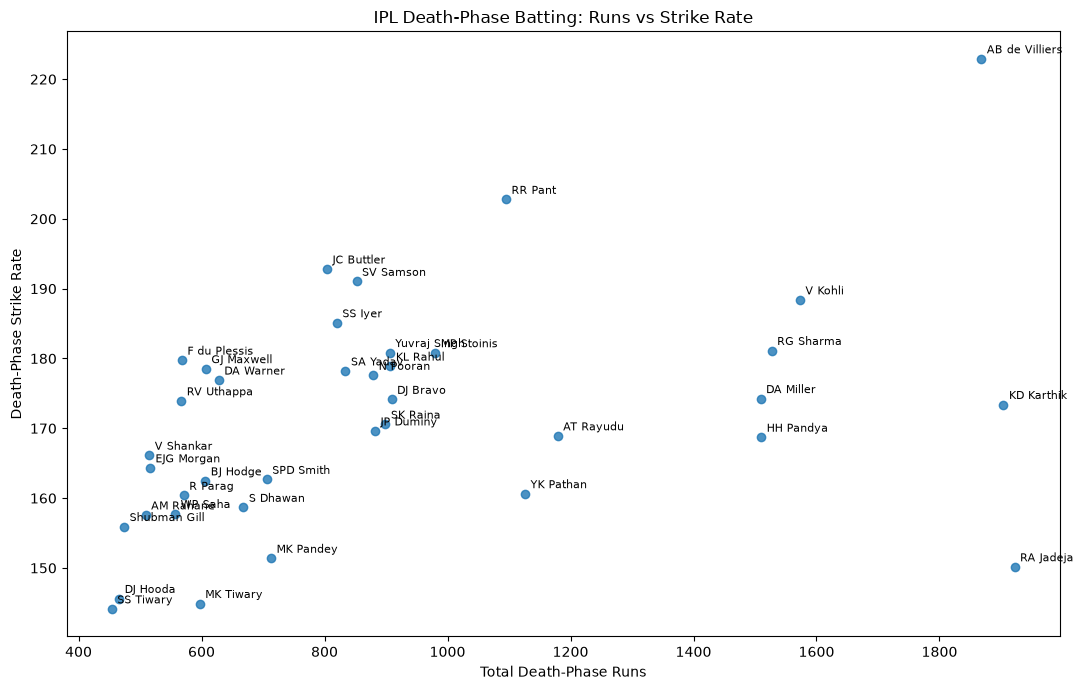

In [162]:
# Step 12: Death-phase volume vs scoring efficiency

import matplotlib.pyplot as plt

plt.figure(figsize=(11, 7))

plt.scatter(
    death_leaderboard["Death_runs"],
    death_leaderboard["Death"],
    alpha=0.8
)

for _, row in death_leaderboard.iterrows():
    plt.annotate(
        row["batter"],
        (row["Death_runs"], row["Death"]),
        fontsize=8,
        xytext=(4, 4),
        textcoords="offset points"
    )

plt.title("IPL Death-Phase Batting: Runs vs Strike Rate")
plt.xlabel("Total Death-Phase Runs")
plt.ylabel("Death-Phase Strike Rate")
plt.tight_layout()
plt.show()

In [163]:
# Step 13: Classify Death-phase batting profiles

runs_cutoff = death_leaderboard["Death_runs"].median()
sr_cutoff = death_leaderboard["Death"].median()

death_leaderboard["profile"] = death_leaderboard.apply(
    lambda row: (
        "High Volume + High SR"
        if row["Death_runs"] >= runs_cutoff
        and row["Death"] >= sr_cutoff
        else "High Volume + Lower SR"
        if row["Death_runs"] >= runs_cutoff
        else "Lower Volume + High SR"
        if row["Death"] >= sr_cutoff
        else "Lower Volume + Lower SR"
    ),
    axis=1
)

print("Run-volume median:", round(runs_cutoff, 2))
print("Strike-rate median:", round(sr_cutoff, 2))

display(
    death_leaderboard[
        [
            "batter",
            "Death_runs",
            "Death_balls",
            "Death",
            "profile"
        ]
    ]
    .sort_values(
        ["profile", "Death_runs"],
        ascending=[True, False]
    )
    .reset_index(drop=True)
    .round(2)
)

Run-volume median: 827.0
Strike-rate median: 172.0


phase,batter,Death_runs,Death_balls,Death,profile
0,KD Karthik,1904.0,1098.0,173.41,High Volume + High SR
1,AB de Villiers,1868.0,838.0,222.91,High Volume + High SR
2,V Kohli,1573.0,835.0,188.38,High Volume + High SR
3,RG Sharma,1527.0,843.0,181.14,High Volume + High SR
4,DA Miller,1509.0,866.0,174.25,High Volume + High SR
5,RR Pant,1095.0,540.0,202.78,High Volume + High SR
6,MP Stoinis,980.0,542.0,180.81,High Volume + High SR
7,DJ Bravo,909.0,522.0,174.14,High Volume + High SR
8,KL Rahul,907.0,507.0,178.90,High Volume + High SR
9,Yuvraj Singh,906.0,501.0,180.84,High Volume + High SR


In [164]:
# Step 14: Summarize Death-phase batting profiles

profile_summary = (
    death_leaderboard.groupby("profile", as_index=False)
    .agg(
        batters=("batter", "count"),
        average_runs=("Death_runs", "mean"),
        average_balls=("Death_balls", "mean"),
        average_strike_rate=("Death", "mean")
    )
    .sort_values("average_strike_rate", ascending=False)
)

display(profile_summary.round(2))


,profile,batters,average_runs,average_balls,average_strike_rate
0,High Volume + High SR,13,1211.00,653.92,184.95
2,Lower Volume + High SR,6,665.67,366.17,181.17
1,High Volume + Lower SR,6,1253.00,770.17,164.77
3,Lower Volume + Lower SR,13,565.54,362.00,156.31


In [165]:
# Step 15: Validate the segmentation thresholds

print("Death-phase runs median:", death_leaderboard["Death_runs"].median())
print("Death-phase strike-rate median:", death_leaderboard["Death"].median())

print("\nBatters per profile:")
display(
    death_leaderboard["profile"]
    .value_counts()
    .rename_axis("profile")
    .reset_index(name="batters")
)

print("\nCheck for missing profile labels:")
print("Missing profiles:", death_leaderboard["profile"].isna().sum())

Death-phase runs median: 827.0
Death-phase strike-rate median: 171.99721418622096

Batters per profile:


,profile,batters
0,High Volume + High SR,13
1,Lower Volume + Lower SR,13
2,High Volume + Lower SR,6
3,Lower Volume + High SR,6



Check for missing profile labels:
Missing profiles: 0


In [166]:
# Chapter 3 — Step 1: Inspect phase-level data for statistical analysis

print("Dataset shape:", batter_phase_df.shape)
print("\nColumns:")
print(batter_phase_df.columns.tolist())

print("\nPhase counts:")
display(batter_phase_df["phase"].value_counts())

print("\nSample rows:")
display(batter_phase_df.head())

Dataset shape: (295732, 5)

Columns:
['match_id', 'batter', 'phase', 'runs', 'balls_faced']

Phase counts:


phase
Middle       135655
Powerplay     92904
Death         67173
Name: count, dtype: int64


Sample rows:


,match_id,batter,phase,runs,balls_faced
0,1082591,DA Warner,Powerplay,0,1
1,1082591,DA Warner,Powerplay,0,1
2,1082591,DA Warner,Powerplay,4,1
3,1082591,DA Warner,Powerplay,0,1
4,1082591,DA Warner,Powerplay,0,0


In [167]:
# Step 2: Aggregate batting performance by match and phase

match_phase_stats = (
    batter_phase_df
    .groupby(["match_id", "batter", "phase"], as_index=False)
    .agg(
        runs=("runs", "sum"),
        balls_faced=("balls_faced", "sum")
    )
)

match_phase_stats["strike_rate"] = (
    match_phase_stats["runs"]
    / match_phase_stats["balls_faced"].replace(0, float("nan"))
    * 100
)

print("Aggregated shape:", match_phase_stats.shape)
print("\nRows per phase:")
display(match_phase_stats["phase"].value_counts())

print("\nSample:")
display(match_phase_stats.head(10).round(2))

Aggregated shape: (28073, 6)

Rows per phase:


phase
Middle       10407
Death         9249
Powerplay     8417
Name: count, dtype: int64


Sample:


,match_id,batter,phase,runs,balls_faced,strike_rate
0,1082591,A Choudhary,Death,6,2,300.00
1,1082591,BCJ Cutting,Death,16,6,266.67
2,1082591,CH Gayle,Middle,6,3,200.00
3,1082591,CH Gayle,Powerplay,26,18,144.44
4,1082591,DA Warner,Powerplay,14,8,175.00
5,1082591,DJ Hooda,Death,16,12,133.33
6,1082591,KM Jadhav,Middle,31,16,193.75
7,1082591,MC Henriques,Death,0,2,0.00
8,1082591,MC Henriques,Middle,35,22,159.09
9,1082591,MC Henriques,Powerplay,17,13,130.77


In [168]:
# Step 3: Filter small samples before statistical comparison

MIN_PHASE_BALLS = 10

reliable_match_phase = match_phase_stats[
    (match_phase_stats["balls_faced"] >= MIN_PHASE_BALLS)
    & (match_phase_stats["strike_rate"].notna())
].copy()

print("Original observations:", len(match_phase_stats))
print("After filtering:", len(reliable_match_phase))
print(
    "Observations retained:",
    round(len(reliable_match_phase) / len(match_phase_stats) * 100, 2),
    "%"
)

print("\nObservations by phase:")
display(reliable_match_phase["phase"].value_counts())

Original observations: 28073
After filtering: 13016
Observations retained: 46.36 %

Observations by phase:


phase
Middle       5796
Powerplay    4519
Death        2701
Name: count, dtype: int64

In [169]:
# Step 4: Descriptive statistics by phase

phase_descriptive_stats = (
    reliable_match_phase
    .groupby("phase")["strike_rate"]
    .agg(
        observations="count",
        mean="mean",
        median="median",
        standard_deviation="std",
        minimum="min",
        maximum="max"
    )
    .sort_values("mean", ascending=False)
)

display(phase_descriptive_stats.round(2))

,observations,mean,median,standard_deviation,minimum,maximum
phase,,,,,,
Death,2701,174.39,170.00,61.05,0.0,418.18
Powerplay,4519,133.34,129.41,50.57,0.0,400.00
Middle,5796,128.88,125.93,44.73,12.5,372.73


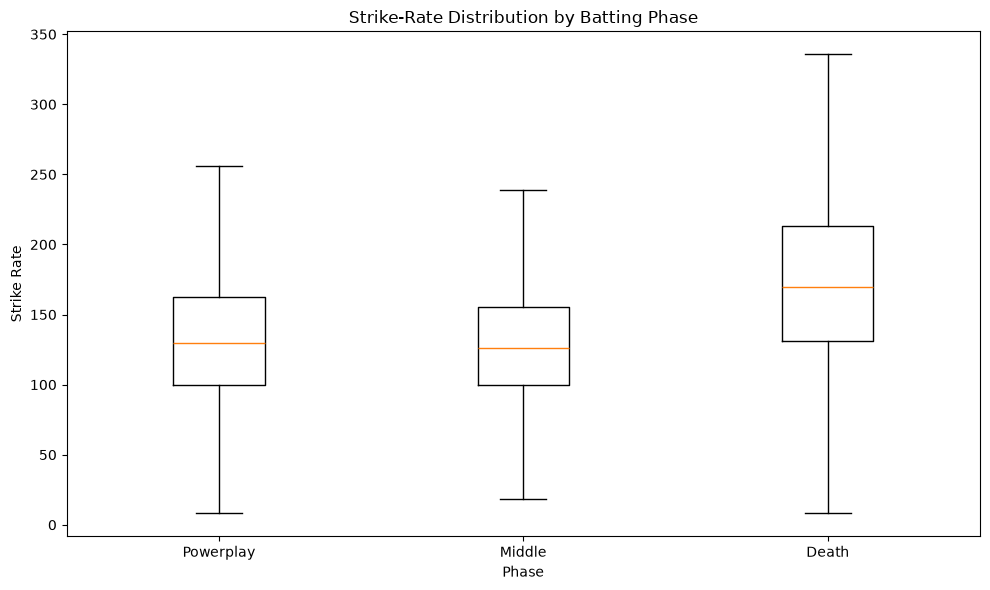

In [170]:
# Step 5: Compare strike-rate distributions across phases

import matplotlib.pyplot as plt

phase_order = ["Powerplay", "Middle", "Death"]

phase_values = [
    reliable_match_phase.loc[
        reliable_match_phase["phase"] == phase, "strike_rate"
    ].dropna()
    for phase in phase_order
]

plt.figure(figsize=(10, 6))
plt.boxplot(phase_values, tick_labels=phase_order, showfliers=False)

plt.title("Strike-Rate Distribution by Batting Phase")
plt.xlabel("Phase")
plt.ylabel("Strike Rate")
plt.tight_layout()
plt.show()

In [171]:
# Step 6: Kruskal-Wallis test across batting phases

from scipy.stats import kruskal

phase_order = ["Powerplay", "Middle", "Death"]

phase_samples = [
    reliable_match_phase.loc[
        reliable_match_phase["phase"] == phase,
        "strike_rate"
    ].dropna()
    for phase in phase_order
]

statistic, p_value = kruskal(*phase_samples)

print("Kruskal-Wallis H-statistic:", round(statistic, 4))
print("P-value:", p_value)

alpha = 0.05

if p_value < alpha:
    print("Result: Evidence of a statistically significant difference between at least two phases.")
else:
    print("Result: Insufficient evidence of a difference between phases.")

Kruskal-Wallis H-statistic: 1221.2831
P-value: 6.334964182559273e-266
Result: Evidence of a statistically significant difference between at least two phases.


In [172]:
import numpy as np
import pandas as pd
from scipy.stats import rankdata, chi2

# Combine the strike rates from all three phases
all_values = np.concatenate(phase_samples)

# Assign ranks to every observation
all_ranks = rankdata(all_values)

# Split the ranks back into their original groups
rank_groups = []
start = 0

for sample in phase_samples:
    end = start + len(sample)
    rank_groups.append(all_ranks[start:end])
    start = end

# Show sample sizes and average ranks
rank_summary = pd.DataFrame({
    "phase": phase_order,
    "observations": [len(x) for x in phase_samples],
    "average_rank": [np.mean(x) for x in rank_groups]
})

display(rank_summary.round(2))

# Calculate the Kruskal-Wallis H-statistic
N = len(all_values)
k = len(phase_samples)

H = (12 / (N * (N + 1))) * sum(
    np.sum(ranks) ** 2 / len(ranks)
    for ranks in rank_groups
) - 3 * (N + 1)

# Correct H for tied observations
_, tie_counts = np.unique(all_values, return_counts=True)
tie_correction = 1 - (
    np.sum(tie_counts**3 - tie_counts) / (N**3 - N)
)

H_corrected = H / tie_correction

# Calculate p-value from chi-squared distribution
degrees_of_freedom = k - 1
p_value_manual = chi2.sf(H_corrected, degrees_of_freedom)

print("Total observations:", N)
print("Uncorrected H:", round(H, 4))
print("Tie correction factor:", round(tie_correction, 8))
print("Corrected H:", round(H_corrected, 4))
print("Degrees of freedom:", degrees_of_freedom)
print("P-value:", p_value_manual)

,phase,observations,average_rank
0,Powerplay,4519,6094.71
1,Middle,5796,5790.19
2,Death,2701,8742.21


Total observations: 13016
Uncorrected H: 1221.1013
Tie correction factor: 0.99985113
Corrected H: 1221.2831
Degrees of freedom: 2
P-value: 6.334964182559273e-266


In [173]:
from scipy.stats import mannwhitneyu
from itertools import combinations

alpha = 0.05
pairs = combinations(zip(phase_order, phase_samples), 2)

pairwise_results = []

for (phase_a, sample_a), (phase_b, sample_b) in pairs:
    u_stat, p_raw = mannwhitneyu(
        sample_a,
        sample_b,
        alternative="two-sided"
    )

    p_adjusted = min(p_raw * 3, 1.0)

    pairwise_results.append({
        "comparison": f"{phase_a} vs {phase_b}",
        "U_statistic": u_stat,
        "p_value": p_raw,
        "bonferroni_p": p_adjusted,
        "significant": p_adjusted < alpha
    })

pairwise_df = pd.DataFrame(pairwise_results)
display(pairwise_df.round(6))

,comparison,U_statistic,p_value,bonferroni_p,significant
0,Powerplay vs Middle,13691017.0,0.000073,0.00022,True
1,Powerplay vs Death,3638034.0,0.000000,0.00000,True
2,Middle vs Death,4259122.0,0.000000,0.00000,True


In [174]:
# Step 8: Effect size using rank-biserial correlation

effect_results = []

for phase_a, sample_a in zip(phase_order, phase_samples):
    for phase_b, sample_b in zip(phase_order, phase_samples):
        if phase_order.index(phase_a) >= phase_order.index(phase_b):
            continue

        result = mannwhitneyu(
            sample_a,
            sample_b,
            alternative="two-sided"
        )

        U = result.statistic
        n1 = len(sample_a)
        n2 = len(sample_b)

        # Positive means the first group's values tend to be higher
        r_rb = (2 * U / (n1 * n2)) - 1

        effect_results.append({
            "comparison": f"{phase_a} vs {phase_b}",
            "rank_biserial_r": r_rb,
            "absolute_effect_size": abs(r_rb)
        })

effect_df = pd.DataFrame(effect_results)
display(effect_df.round(4))

,comparison,rank_biserial_r,absolute_effect_size
0,Powerplay vs Middle,0.0454,0.0454
1,Powerplay vs Death,-0.4039,0.4039
2,Middle vs Death,-0.4559,0.4559


In [175]:
# Step 9: Bootstrap 95% confidence intervals for median strike rate

import numpy as np
import pandas as pd

rng = np.random.default_rng(42)
N_BOOTSTRAPS = 2000

ci_results = []

for phase, sample in zip(phase_order, phase_samples):
    values = sample.to_numpy()
    bootstrap_medians = np.empty(N_BOOTSTRAPS)

    for i in range(N_BOOTSTRAPS):
        resampled = rng.choice(values, size=len(values), replace=True)
        bootstrap_medians[i] = np.median(resampled)

    lower, upper = np.percentile(bootstrap_medians, [2.5, 97.5])

    ci_results.append({
        "phase": phase,
        "sample_median": np.median(values),
        "ci_95_lower": lower,
        "ci_95_upper": upper
    })

ci_df = pd.DataFrame(ci_results)
display(ci_df.round(2))

,phase,sample_median,ci_95_lower,ci_95_upper
0,Powerplay,129.41,127.27,130.77
1,Middle,125.93,124.14,127.27
2,Death,170.00,166.67,172.73


In [176]:
# Step 10: Audit repeated batters and observation structure

print("Total observations:", len(reliable_match_phase))
print("Unique batters:", reliable_match_phase["batter"].nunique())
print("Unique matches:", reliable_match_phase["match_id"].nunique())

print("\nObservations per phase:")
display(
    reliable_match_phase.groupby("phase")
    .agg(
        observations=("strike_rate", "size"),
        unique_batters=("batter", "nunique"),
        unique_matches=("match_id", "nunique")
    )
    .reindex(["Powerplay", "Middle", "Death"])
)

print("\nObservations per batter:")
batter_observation_counts = (
    reliable_match_phase.groupby("batter")
    .size()
    .describe()
)
display(batter_observation_counts.to_frame("value").round(2))


Total observations: 13016
Unique batters: 528
Unique matches: 1242

Observations per phase:


,observations,unique_batters,unique_matches
phase,,,
Powerplay,4519,290,1242
Middle,5796,407,1240
Death,2701,396,1180



Observations per batter:


,value
count,528.00
mean,24.65
std,43.68
min,1.00
25%,2.00
50%,6.00
75%,25.25
max,329.00


In [178]:
# Chapter 3: Batter-level cluster bootstrap
# 95% confidence intervals for pairwise median strike-rate differences

import numpy as np
import pandas as pd
from itertools import combinations

rng = np.random.default_rng(42)
N_BOOTSTRAPS = 2000

# Store each batter's observations separately for every phase
batter_phase_values = {
    phase: {
        batter: group["strike_rate"].to_numpy()
        for batter, group in reliable_match_phase[
            reliable_match_phase["phase"] == phase
        ].groupby("batter")
    }
    for phase in phase_order
}

all_batters = reliable_match_phase["batter"].unique()

# Observed median differences: phase A minus phase B
results = []

for phase_a, phase_b in combinations(phase_order, 2):
    observed_difference = (
        reliable_match_phase.loc[
            reliable_match_phase["phase"] == phase_a, "strike_rate"
        ].median()
        -
        reliable_match_phase.loc[
            reliable_match_phase["phase"] == phase_b, "strike_rate"
        ].median()
    )

    bootstrap_differences = []

    for _ in range(N_BOOTSTRAPS):
        # Sample whole batters, allowing a batter to be selected more than once
        sampled_batters = rng.choice(
            all_batters, size=len(all_batters), replace=True
        )

        phase_a_parts = [
            batter_phase_values[phase_a][b]
            for b in sampled_batters
            if b in batter_phase_values[phase_a]
        ]
        phase_b_parts = [
            batter_phase_values[phase_b][b]
            for b in sampled_batters
            if b in batter_phase_values[phase_b]
        ]

        # Skip a replicate only if a phase has no observations
        if not phase_a_parts or not phase_b_parts:
            continue

        median_a = np.median(np.concatenate(phase_a_parts))
        median_b = np.median(np.concatenate(phase_b_parts))

        bootstrap_differences.append(median_a - median_b)

    lower, upper = np.percentile(bootstrap_differences, [2.5, 97.5])

    results.append({
        "comparison": f"{phase_a} - {phase_b}",
        "observed_median_difference": observed_difference,
        "cluster_bootstrap_95%_lower": lower,
        "cluster_bootstrap_95%_upper": upper,
        "interval_excludes_zero": lower > 0 or upper < 0,
        "successful_replicates": len(bootstrap_differences)
    })

cluster_bootstrap_df = pd.DataFrame(results)
display(cluster_bootstrap_df.round(2))

,comparison,observed_median_difference,cluster_bootstrap_95%_lower,cluster_bootstrap_95%_upper,interval_excludes_zero,successful_replicates
0,Powerplay - Middle,3.49,0.00,6.6,False,2000
1,Powerplay - Death,-40.59,-45.45,-35.9,True,2000
2,Middle - Death,-44.07,-48.47,-40.0,True,2000


In [179]:
# Chapter 4: Predictive Modelling
# Step 1 — Inspect the match and innings datasets

print("Matches dataset:")
print("Shape:", matches_df.shape)
print("Columns:", matches_df.columns.tolist())

print("\nFirst-innings dataset:")
print("Shape:", first_scores_df.shape)
print("Columns:", first_scores_df.columns.tolist())

display(matches_df.head(3))
display(first_scores_df.head(3))

Matches dataset:
Shape: (1243, 13)
Columns: ['match_id', 'date', 'season', 'team1', 'team2', 'venue', 'city', 'toss_winner', 'toss_decision', 'winner', 'win_by_runs', 'win_by_wickets', 'player_of_match']

First-innings dataset:
Shape: (1243, 2)
Columns: ['match_id', 'first_innings_score']


,match_id,date,season,team1,team2,venue,city,toss_winner,toss_decision,winner,win_by_runs,win_by_wickets,player_of_match
0,1082591,2017-04-05,2017,Sunrisers Hyderabad,Royal Challengers Bangalore,"Rajiv Gandhi International Stadium, Uppal",Hyderabad,Royal Challengers Bangalore,field,Sunrisers Hyderabad,35,0,Yuvraj Singh
1,1082592,2017-04-06,2017,Rising Pune Supergiant,Mumbai Indians,Maharashtra Cricket Association Stadium,Pune,Rising Pune Supergiant,field,Rising Pune Supergiant,0,7,SPD Smith
2,1082593,2017-04-07,2017,Gujarat Lions,Kolkata Knight Riders,Saurashtra Cricket Association Stadium,Rajkot,Kolkata Knight Riders,field,Kolkata Knight Riders,0,10,CA Lynn


,match_id,first_innings_score
0,1082591,207
1,1082592,184
2,1082593,183


In [180]:
# Chapter 4 — Step 2: Audit match outcomes and available data

print("MATCH OUTCOMES")
print("Total matches:", len(matches_df))
print("Missing winners:", matches_df["winner"].isna().sum())

print("\nMatches by winning margin:")
print("Won by runs:", (matches_df["win_by_runs"] > 0).sum())
print("Won by wickets:", (matches_df["win_by_wickets"] > 0).sum())
print("Neither margin positive:",
      ((matches_df["win_by_runs"] == 0) &
       (matches_df["win_by_wickets"] == 0)).sum())

print("\nFIRST-INNINGS SCORE")
print("Missing scores:", first_scores_df["first_innings_score"].isna().sum())
print("Minimum score:", first_scores_df["first_innings_score"].min())
print("Median score:", first_scores_df["first_innings_score"].median())
print("Maximum score:", first_scores_df["first_innings_score"].max())

print("\nDELIVERY DATA")
print("Columns:", deliveries_df.columns.tolist())
print("Rows:", len(deliveries_df))

MATCH OUTCOMES
Total matches: 1243
Missing winners: 25

Matches by winning margin:
Won by runs: 558
Won by wickets: 660
Neither margin positive: 25

FIRST-INNINGS SCORE
Missing scores: 0
Minimum score: 25
Median score: 168.0
Maximum score: 287

DELIVERY DATA
Columns: ['innings', 'delivery', 'batter', 'bowler', 'total_runs', 'wicket', 'wides', 'noballs', 'over_number', 'phase', 'legal_ball']
Rows: 248


In [181]:
# Step 3: Create a match-level modelling dataset

# Keep matches with a recorded winner
model_matches = matches_df[matches_df["winner"].notna()].copy()

# Add first-innings scores
model_df = model_matches.merge(
    first_scores_df,
    on="match_id",
    how="inner",
    validate="one_to_one"
)

# Target: did team1 win the match?
# We'll inspect team1's relationship to batting first before finalizing the target.
model_df["team1_won"] = (
    model_df["winner"] == model_df["team1"]
).astype(int)

# Add basic pre-match/context features
basic_features = [
    "match_id", "date", "season", "team1", "team2",
    "venue", "city", "toss_winner", "toss_decision",
    "first_innings_score", "winner", "team1_won"
]

display(model_df[basic_features].head())
print("\nModel dataset shape:", model_df.shape)
print("Target distribution (team1 won):")
display(model_df["team1_won"].value_counts().rename("matches"))

,match_id,date,season,team1,team2,venue,city,toss_winner,toss_decision,first_innings_score,winner,team1_won
0,1082591,2017-04-05,2017,Sunrisers Hyderabad,Royal Challengers Bangalore,"Rajiv Gandhi International Stadium, Uppal",Hyderabad,Royal Challengers Bangalore,field,207,Sunrisers Hyderabad,1
1,1082592,2017-04-06,2017,Rising Pune Supergiant,Mumbai Indians,Maharashtra Cricket Association Stadium,Pune,Rising Pune Supergiant,field,184,Rising Pune Supergiant,1
2,1082593,2017-04-07,2017,Gujarat Lions,Kolkata Knight Riders,Saurashtra Cricket Association Stadium,Rajkot,Kolkata Knight Riders,field,183,Kolkata Knight Riders,0
3,1082594,2017-04-08,2017,Kings XI Punjab,Rising Pune Supergiant,Holkar Cricket Stadium,Indore,Kings XI Punjab,field,163,Kings XI Punjab,1
4,1082595,2017-04-08,2017,Royal Challengers Bangalore,Delhi Daredevils,M.Chinnaswamy Stadium,Bengaluru,Royal Challengers Bangalore,bat,157,Royal Challengers Bangalore,1



Model dataset shape: (1218, 15)
Target distribution (team1 won):


team1_won
0    610
1    608
Name: matches, dtype: int64

In [182]:
# Step 4: Infer the batting-first team from toss information

model_df["batting_first_team"] = np.where(
    model_df["toss_decision"].str.lower() == "bat",
    model_df["toss_winner"],
    np.where(
        model_df["toss_decision"].str.lower() == "field",
        np.where(
            model_df["toss_winner"] == model_df["team1"],
            model_df["team2"],
            model_df["team1"]
        ),
        np.nan
    )
)

model_df["batting_first_won"] = (
    model_df["winner"] == model_df["batting_first_team"]
).astype(int)

print("Missing batting-first teams:", model_df["batting_first_team"].isna().sum())
print("\nTarget distribution:")
display(
    model_df["batting_first_won"]
    .value_counts()
    .rename(index={0: "Batting-first team did not win", 1: "Batting-first team won"})
    .to_frame("matches")
)

display(
    model_df[
        ["team1", "team2", "toss_winner", "toss_decision",
         "batting_first_team", "winner", "batting_first_won"]
    ].head(10)
)

Missing batting-first teams: 0

Target distribution:


,matches
batting_first_won,
Batting-first team did not win,666
Batting-first team won,552


,team1,team2,toss_winner,toss_decision,batting_first_team,winner,batting_first_won
0,Sunrisers Hyderabad,Royal Challengers Bangalore,Royal Challengers Bangalore,field,Sunrisers Hyderabad,Sunrisers Hyderabad,1
1,Rising Pune Supergiant,Mumbai Indians,Rising Pune Supergiant,field,Mumbai Indians,Rising Pune Supergiant,0
2,Gujarat Lions,Kolkata Knight Riders,Kolkata Knight Riders,field,Gujarat Lions,Kolkata Knight Riders,0
3,Kings XI Punjab,Rising Pune Supergiant,Kings XI Punjab,field,Rising Pune Supergiant,Kings XI Punjab,0
4,Royal Challengers Bangalore,Delhi Daredevils,Royal Challengers Bangalore,bat,Royal Challengers Bangalore,Royal Challengers Bangalore,1
5,Sunrisers Hyderabad,Gujarat Lions,Sunrisers Hyderabad,field,Gujarat Lions,Sunrisers Hyderabad,0
6,Mumbai Indians,Kolkata Knight Riders,Mumbai Indians,field,Kolkata Knight Riders,Mumbai Indians,0
7,Kings XI Punjab,Royal Challengers Bangalore,Royal Challengers Bangalore,bat,Royal Challengers Bangalore,Kings XI Punjab,0
8,Rising Pune Supergiant,Delhi Daredevils,Rising Pune Supergiant,field,Delhi Daredevils,Delhi Daredevils,1
9,Mumbai Indians,Sunrisers Hyderabad,Mumbai Indians,field,Sunrisers Hyderabad,Mumbai Indians,0


In [183]:
# Step 5: Validate target and inspect missing values

print("TARGET VALIDATION")
print("Matches:", len(model_df))
print("Missing batting-first team:",
      model_df["batting_first_team"].isna().sum())
print("Missing target:", model_df["batting_first_won"].isna().sum())

print("\nTARGET BALANCE")
display(
    model_df["batting_first_won"]
    .value_counts(normalize=True)
    .mul(100)
    .rename("percentage")
    .round(2)
)

print("\nFEATURE MISSINGNESS")
candidate_features = [
    "date", "season", "team1", "team2", "venue", "city",
    "toss_winner", "toss_decision", "first_innings_score"
]
display(
    model_df[candidate_features]
    .isna()
    .sum()
    .rename("missing_values")
    .to_frame()
)

print("\nTOSS DECISION VALUES")
display(model_df["toss_decision"].value_counts(dropna=False))

TARGET VALIDATION
Matches: 1218
Missing batting-first team: 0
Missing target: 0

TARGET BALANCE


batting_first_won
0    54.68
1    45.32
Name: percentage, dtype: float64


FEATURE MISSINGNESS


,missing_values
date,0
season,0
team1,0
team2,0
venue,0
city,48
toss_winner,0
toss_decision,0
first_innings_score,0



TOSS DECISION VALUES


toss_decision
field    810
bat      408
Name: count, dtype: int64

In [184]:
# Get the actual batting team from innings 1
actual_first_innings = (
    phase_df[phase_df["innings"] == 1]
    .groupby("match_id")["batting_team"]
    .agg(lambda x: x.mode().iloc[0] if not x.mode().empty else np.nan)
    .rename("actual_batting_first_team")
    .reset_index()
)

# Compare inferred and actual batting-first teams
validation_df = model_df.merge(
    actual_first_innings,
    on="match_id",
    how="left",
    validate="one_to_one"
)

validation_df["team_matches"] = (
    validation_df["batting_first_team"]
    == validation_df["actual_batting_first_team"]
)

print("Matches checked:", len(validation_df))
print("Missing actual innings team:",
      validation_df["actual_batting_first_team"].isna().sum())
print("Inferred/actual agreements:",
      validation_df["team_matches"].sum())
print("Disagreements:",
      (~validation_df["team_matches"]).sum())

display(
    validation_df.loc[
        ~validation_df["team_matches"],
        ["match_id", "batting_first_team", "actual_batting_first_team"]
    ].head(10)
)

Matches checked: 1218
Missing actual innings team: 0
Inferred/actual agreements: 1218
Disagreements: 0


,match_id,batting_first_team,actual_batting_first_team


In [185]:
# Step 7: Build the initial feature dataset

team_aliases = {
    "Royal Challengers Bangalore": "Royal Challengers Bengaluru",
    "Kings XI Punjab": "Punjab Kings",
    "Delhi Daredevils": "Delhi Capitals",
    "Rising Pune Supergiants": "Rising Pune Supergiant"
}

model_df = validation_df.copy()

# Normalize historical team names
for col in [
    "team1", "team2", "toss_winner",
    "batting_first_team", "actual_batting_first_team"
]:
    model_df[col] = model_df[col].replace(team_aliases)

# Target: did the team batting first win?
model_df["batting_first_won"] = (
    model_df["winner"] == model_df["batting_first_team"]
).astype(int)

# Features available at the end of the first innings
feature_cols = [
    "first_innings_score",
    "batting_first_team",
    "team1",
    "team2",
    "venue",
    "city",
    "toss_decision"
]

X = model_df[feature_cols].copy()
y = model_df["batting_first_won"].copy()

print("Feature matrix:", X.shape)
print("Target:", y.shape)
print("\nTarget balance:")
display(y.value_counts(normalize=True).mul(100).round(2))
print("\nSample:")
display(X.head())

Feature matrix: (1218, 7)
Target: (1218,)

Target balance:


batting_first_won
0    64.29
1    35.71
Name: proportion, dtype: float64


Sample:


,first_innings_score,batting_first_team,team1,team2,venue,city,toss_decision
0,207,Sunrisers Hyderabad,Sunrisers Hyderabad,Royal Challengers Bengaluru,"Rajiv Gandhi International Stadium, Uppal",Hyderabad,field
1,184,Mumbai Indians,Rising Pune Supergiant,Mumbai Indians,Maharashtra Cricket Association Stadium,Pune,field
2,183,Gujarat Lions,Gujarat Lions,Kolkata Knight Riders,Saurashtra Cricket Association Stadium,Rajkot,field
3,163,Rising Pune Supergiant,Punjab Kings,Rising Pune Supergiant,Holkar Cricket Stadium,Indore,field
4,157,Royal Challengers Bengaluru,Royal Challengers Bengaluru,Delhi Capitals,M.Chinnaswamy Stadium,Bengaluru,bat


In [186]:
# Step 8: Check winner matching and target consistency

print("Winner missing:", model_df["winner"].isna().sum())

print("\nTarget distribution:")
display(model_df["batting_first_won"].value_counts())

print("\nWinner vs batting-first team sample:")
display(
    model_df[
        ["winner", "batting_first_team", "batting_first_won"]
    ].head(15)
)

print("\nTarget recomputation check:")
recomputed_target = (
    model_df["winner"] == model_df["batting_first_team"]
).astype(int)

print(
    "Rows differing from stored target:",
    (recomputed_target != model_df["batting_first_won"]).sum()
)

Winner missing: 0

Target distribution:


batting_first_won
0    783
1    435
Name: count, dtype: int64


Winner vs batting-first team sample:


,winner,batting_first_team,batting_first_won
0,Sunrisers Hyderabad,Sunrisers Hyderabad,1
1,Rising Pune Supergiant,Mumbai Indians,0
2,Kolkata Knight Riders,Gujarat Lions,0
3,Kings XI Punjab,Rising Pune Supergiant,0
4,Royal Challengers Bangalore,Royal Challengers Bengaluru,0
5,Sunrisers Hyderabad,Gujarat Lions,0
6,Mumbai Indians,Kolkata Knight Riders,0
7,Kings XI Punjab,Royal Challengers Bengaluru,0
8,Delhi Daredevils,Delhi Capitals,0
9,Mumbai Indians,Sunrisers Hyderabad,0



Target recomputation check:
Rows differing from stored target: 0


In [187]:
# Step 9: Normalize all team names consistently

team_columns = [
    "winner",
    "team1",
    "team2",
    "toss_winner",
    "batting_first_team",
    "actual_batting_first_team"
]

for col in team_columns:
    model_df[col] = model_df[col].replace(team_aliases)

# Recalculate target after normalization
model_df["batting_first_won"] = (
    model_df["winner"] == model_df["batting_first_team"]
).astype(int)

X = model_df[feature_cols].copy()
y = model_df["batting_first_won"].copy()

print("Corrected target distribution:")
display(y.value_counts().rename("matches"))

print("\nCorrected target percentages:")
display(y.value_counts(normalize=True).mul(100).round(2))

print("\nWinner matches batting-first team:")
print((model_df["winner"] == model_df["batting_first_team"]).sum())

Corrected target distribution:


batting_first_won
0    666
1    552
Name: matches, dtype: int64


Corrected target percentages:


batting_first_won
0    54.68
1    45.32
Name: proportion, dtype: float64


Winner matches batting-first team:
552


In [188]:
# Step 10: Chronological train/test split

model_df["date"] = pd.to_datetime(model_df["date"], errors="coerce")

# Sort by date; preserve chronological order
model_df = model_df.sort_values("date").reset_index(drop=True)

X = model_df[feature_cols].copy()
y = model_df["batting_first_won"].copy()

split_idx = int(len(model_df) * 0.80)

X_train = X.iloc[:split_idx].copy()
X_test = X.iloc[split_idx:].copy()

y_train = y.iloc[:split_idx].copy()
y_test = y.iloc[split_idx:].copy()

print("Training matches:", len(X_train))
print("Testing matches:", len(X_test))
print("Training date range:", model_df["date"].iloc[0].date(),
      "to", model_df["date"].iloc[split_idx - 1].date())
print("Testing date range:", model_df["date"].iloc[split_idx].date(),
      "to", model_df["date"].iloc[-1].date())

print("\nTraining target balance:")
display(y_train.value_counts(normalize=True).mul(100).round(2))

print("\nTesting target balance:")
display(y_test.value_counts(normalize=True).mul(100).round(2))

Training matches: 974
Testing matches: 244
Training date range: 2008-04-18 to 2023-04-30
Testing date range: 2023-05-01 to 2026-05-31

Training target balance:


batting_first_won
0    54.72
1    45.28
Name: proportion, dtype: float64


Testing target balance:


batting_first_won
0    54.51
1    45.49
Name: proportion, dtype: float64

In [189]:
# Step 10: Chronological train/test split

model_df["date"] = pd.to_datetime(model_df["date"], errors="coerce")

# Sort by date; preserve chronological order
model_df = model_df.sort_values("date").reset_index(drop=True)

X = model_df[feature_cols].copy()
y = model_df["batting_first_won"].copy()

split_idx = int(len(model_df) * 0.80)

X_train = X.iloc[:split_idx].copy()
X_test = X.iloc[split_idx:].copy()

y_train = y.iloc[:split_idx].copy()
y_test = y.iloc[split_idx:].copy()

print("Training matches:", len(X_train))
print("Testing matches:", len(X_test))
print("Training date range:", model_df["date"].iloc[0].date(),
      "to", model_df["date"].iloc[split_idx - 1].date())
print("Testing date range:", model_df["date"].iloc[split_idx].date(),
      "to", model_df["date"].iloc[-1].date())

print("\nTraining target balance:")
display(y_train.value_counts(normalize=True).mul(100).round(2))

print("\nTesting target balance:")
display(y_test.value_counts(normalize=True).mul(100).round(2))

Training matches: 974
Testing matches: 244
Training date range: 2008-04-18 to 2023-04-30
Testing date range: 2023-05-01 to 2026-05-31

Training target balance:


batting_first_won
0    54.72
1    45.28
Name: proportion, dtype: float64


Testing target balance:


batting_first_won
0    54.51
1    45.49
Name: proportion, dtype: float64

In [190]:
# Step 11: Baseline evaluation

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report
)

# Baseline predicts 0 = batting-first team loses
baseline_predictions = np.zeros(len(y_test), dtype=int)

print("BASELINE MODEL")
print("Accuracy:", round(accuracy_score(y_test, baseline_predictions), 4))
print("Precision:", round(
    precision_score(y_test, baseline_predictions, zero_division=0), 4
))
print("Recall:", round(
    recall_score(y_test, baseline_predictions, zero_division=0), 4
))
print("F1-score:", round(
    f1_score(y_test, baseline_predictions, zero_division=0), 4
))

print("\nConfusion matrix:")
print(confusion_matrix(y_test, baseline_predictions))

print("\nClassification report:")
print(classification_report(
    y_test,
    baseline_predictions,
    target_names=["Batting-first loss", "Batting-first win"],
    zero_division=0
))

BASELINE MODEL
Accuracy: 0.5451
Precision: 0.0
Recall: 0.0
F1-score: 0.0

Confusion matrix:
[[133   0]
 [111   0]]

Classification report:
                    precision    recall  f1-score   support

Batting-first loss       0.55      1.00      0.71       133
 Batting-first win       0.00      0.00      0.00       111

          accuracy                           0.55       244
         macro avg       0.27      0.50      0.35       244
      weighted avg       0.30      0.55      0.38       244



In [191]:
# Step 12: Train a logistic regression model

from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression

numeric_features = ["first_innings_score"]

categorical_features = [
    "batting_first_team",
    "team1",
    "team2",
    "venue",
    "city",
    "toss_decision"
]

numeric_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

categorical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="ignore"))
])

preprocessor = ColumnTransformer([
    ("numeric", numeric_pipeline, numeric_features),
    ("categorical", categorical_pipeline, categorical_features)
])

logistic_model = Pipeline([
    ("preprocessor", preprocessor),
    ("classifier", LogisticRegression(max_iter=2000))
])

logistic_model.fit(X_train, y_train)

print("Logistic regression training complete.")
print("Training accuracy:", round(logistic_model.score(X_train, y_train), 4))
print("Test accuracy:", round(logistic_model.score(X_test, y_test), 4))

Logistic regression training complete.
Training accuracy: 0.7444
Test accuracy: 0.6311


In [192]:
# Step 13: Evaluate logistic regression on unseen matches

from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, log_loss, brier_score_loss,
    confusion_matrix, classification_report
)

predictions = logistic_model.predict(X_test)
win_probabilities = logistic_model.predict_proba(X_test)[:, 1]

print("TEST SET METRICS")
print("Accuracy:", round(accuracy_score(y_test, predictions), 4))
print("Precision:", round(precision_score(y_test, predictions, zero_division=0), 4))
print("Recall:", round(recall_score(y_test, predictions, zero_division=0), 4))
print("F1-score:", round(f1_score(y_test, predictions, zero_division=0), 4))
print("ROC-AUC:", round(roc_auc_score(y_test, win_probabilities), 4))
print("Log loss:", round(log_loss(y_test, win_probabilities), 4))
print("Brier score:", round(brier_score_loss(y_test, win_probabilities), 4))

print("\nConfusion matrix:")
print(confusion_matrix(y_test, predictions))

print("\nClassification report:")
print(classification_report(
    y_test, predictions,
    target_names=["Batting-first loss", "Batting-first win"],
    zero_division=0
))

TEST SET METRICS
Accuracy: 0.6311
Precision: 0.5621
Recall: 0.8559
F1-score: 0.6786
ROC-AUC: 0.7037
Log loss: 0.7766
Brier score: 0.2573

Confusion matrix:
[[59 74]
 [16 95]]

Classification report:
                    precision    recall  f1-score   support

Batting-first loss       0.79      0.44      0.57       133
 Batting-first win       0.56      0.86      0.68       111

          accuracy                           0.63       244
         macro avg       0.67      0.65      0.62       244
      weighted avg       0.68      0.63      0.62       244



In [193]:
# Step 14: Threshold analysis

from sklearn.metrics import precision_score, recall_score, f1_score, accuracy_score

threshold_results = []

for threshold in [0.35, 0.40, 0.45, 0.50, 0.55, 0.60, 0.65]:
    threshold_predictions = (
        win_probabilities >= threshold
    ).astype(int)

    threshold_results.append({
        "threshold": threshold,
        "accuracy": accuracy_score(y_test, threshold_predictions),
        "precision": precision_score(
            y_test, threshold_predictions, zero_division=0
        ),
        "recall": recall_score(
            y_test, threshold_predictions, zero_division=0
        ),
        "f1": f1_score(
            y_test, threshold_predictions, zero_division=0
        )
    })

threshold_df = pd.DataFrame(threshold_results)
display(threshold_df.round(3))

,threshold,accuracy,precision,recall,f1
0,0.35,0.578,0.520,0.928,0.667
1,0.40,0.594,0.532,0.892,0.667
2,0.45,0.615,0.548,0.874,0.674
3,0.50,0.631,0.562,0.856,0.679
4,0.55,0.639,0.572,0.820,0.674
5,0.60,0.652,0.586,0.802,0.677
6,0.65,0.656,0.599,0.739,0.661


In [194]:
# Step 15: Train a Random Forest classifier

from sklearn.ensemble import RandomForestClassifier

rf_numeric_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median"))
])

rf_preprocessor = ColumnTransformer([
    ("numeric", rf_numeric_pipeline, numeric_features),
    ("categorical", categorical_pipeline, categorical_features)
])

rf_model = Pipeline([
    ("preprocessor", rf_preprocessor),
    ("classifier", RandomForestClassifier(
        n_estimators=400,
        min_samples_leaf=8,
        max_features="sqrt",
        class_weight="balanced",
        random_state=42,
        n_jobs=-1
    ))
])

rf_model.fit(X_train, y_train)

rf_predictions = rf_model.predict(X_test)
rf_probabilities = rf_model.predict_proba(X_test)[:, 1]

print("Random Forest training complete.")
print("Training accuracy:", round(rf_model.score(X_train, y_train), 4))
print("Test accuracy:", round(rf_model.score(X_test, y_test), 4))

Random Forest training complete.
Training accuracy: 0.7187
Test accuracy: 0.6066


In [195]:
# Step 16: Side-by-side model comparison

from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, log_loss, brier_score_loss
)

def evaluate_model(name, predictions, probabilities):
    return {
        "model": name,
        "accuracy": accuracy_score(y_test, predictions),
        "precision": precision_score(y_test, predictions, zero_division=0),
        "recall": recall_score(y_test, predictions, zero_division=0),
        "f1": f1_score(y_test, predictions, zero_division=0),
        "roc_auc": roc_auc_score(y_test, probabilities),
        "log_loss": log_loss(y_test, probabilities),
        "brier_score": brier_score_loss(y_test, probabilities)
    }

comparison_df = pd.DataFrame([
    evaluate_model(
        "Baseline",
        baseline_predictions,
        np.full(len(y_test), y_train.mean())
    ),
    evaluate_model(
        "Logistic Regression",
        predictions,
        win_probabilities
    ),
    evaluate_model(
        "Random Forest",
        rf_predictions,
        rf_probabilities
    )
])

display(comparison_df.round(4))

,model,accuracy,precision,recall,f1,roc_auc,log_loss,brier_score
0,Baseline,0.5451,0.0000,0.0000,0.0000,0.5000,0.6891,0.2480
1,Logistic Regression,0.6311,0.5621,0.8559,0.6786,0.7037,0.7766,0.2573
2,Random Forest,0.6066,0.5385,0.9459,0.6863,0.7291,0.6598,0.2334


In [196]:
# Step 17: Compare classification errors

from sklearn.metrics import confusion_matrix, classification_report

print("RANDOM FOREST CONFUSION MATRIX")
print(confusion_matrix(y_test, rf_predictions))

print("\nRANDOM FOREST CLASSIFICATION REPORT")
print(classification_report(
    y_test,
    rf_predictions,
    target_names=["Batting-first loss", "Batting-first win"],
    zero_division=0
))

print("\nLOGISTIC REGRESSION CONFUSION MATRIX")
print(confusion_matrix(y_test, predictions))

print("\nPREDICTED WIN RATE")
print("Actual test win rate:", round(y_test.mean(), 3))
print("Logistic predicted win rate:", round(predictions.mean(), 3))
print("Random Forest predicted win rate:", round(rf_predictions.mean(), 3))

RANDOM FOREST CONFUSION MATRIX
[[ 43  90]
 [  6 105]]

RANDOM FOREST CLASSIFICATION REPORT
                    precision    recall  f1-score   support

Batting-first loss       0.88      0.32      0.47       133
 Batting-first win       0.54      0.95      0.69       111

          accuracy                           0.61       244
         macro avg       0.71      0.63      0.58       244
      weighted avg       0.72      0.61      0.57       244


LOGISTIC REGRESSION CONFUSION MATRIX
[[59 74]
 [16 95]]

PREDICTED WIN RATE
Actual test win rate: 0.455
Logistic predicted win rate: 0.693
Random Forest predicted win rate: 0.799


In [197]:
# Step 18: Compare predicted probabilities with observed win rates

from sklearn.calibration import calibration_curve

for name, probabilities in [
    ("Logistic Regression", win_probabilities),
    ("Random Forest", rf_probabilities)
]:
    observed_rate, mean_probability = calibration_curve(
        y_test,
        probabilities,
        n_bins=5,
        strategy="quantile"
    )

    calibration_df = pd.DataFrame({
        "mean_predicted_probability": mean_probability,
        "actual_win_rate": observed_rate
    })

    print(f"\n{name}")
    display(calibration_df.round(3))


Logistic Regression


,mean_predicted_probability,actual_win_rate
0,0.188,0.204
1,0.487,0.327
2,0.696,0.479
3,0.841,0.612
4,0.948,0.653



Random Forest


,mean_predicted_probability,actual_win_rate
0,0.374,0.122
1,0.553,0.367
2,0.617,0.458
3,0.655,0.653
4,0.703,0.673


In [198]:
# Step 19: Quantify probability calibration

from sklearn.calibration import calibration_curve
from sklearn.metrics import brier_score_loss, log_loss

def calibration_metrics(y_true, probabilities, n_bins=5):
    observed, predicted = calibration_curve(
        y_true,
        probabilities,
        n_bins=n_bins,
        strategy="quantile"
    )

    # Recreate quantile bins to weight each bin by its sample count
    bin_ids = pd.qcut(
        pd.Series(probabilities).rank(method="first"),
        q=n_bins,
        labels=False
    )

    bin_errors = []
    for bin_id in range(n_bins):
        mask = bin_ids.to_numpy() == bin_id
        bin_errors.append(
            mask.mean()
            * abs(y_true.to_numpy()[mask].mean()
                  - probabilities[mask].mean())
        )

    return {
        "brier_score": brier_score_loss(y_true, probabilities),
        "log_loss": log_loss(y_true, probabilities),
        "ECE_5_bins": sum(bin_errors)
    }

calibration_comparison = pd.DataFrame([
    {
        "model": "Logistic Regression",
        **calibration_metrics(y_test, win_probabilities)
    },
    {
        "model": "Random Forest",
        **calibration_metrics(y_test, rf_probabilities)
    }
])

display(calibration_comparison.round(4))

,model,brier_score,log_loss,ECE_5_bins
0,Logistic Regression,0.2573,0.7766,0.1833
1,Random Forest,0.2334,0.6598,0.1254


In [199]:
# Step 20: Three-way chronological split

model_df = model_df.sort_values("date").reset_index(drop=True)

n = len(model_df)
train_end = int(n * 0.65)
validation_end = int(n * 0.80)

train_df = model_df.iloc[:train_end].copy()
validation_df = model_df.iloc[train_end:validation_end].copy()
test_df = model_df.iloc[validation_end:].copy()

X_train = train_df[feature_cols].copy()
y_train = train_df["batting_first_won"].copy()

X_val = validation_df[feature_cols].copy()
y_val = validation_df["batting_first_won"].copy()

X_test_final = test_df[feature_cols].copy()
y_test_final = test_df["batting_first_won"].copy()

print("TRAIN:", len(train_df),
      train_df["date"].min().date(), "to",
      train_df["date"].max().date())

print("VALIDATION:", len(validation_df),
      validation_df["date"].min().date(), "to",
      validation_df["date"].max().date())

print("FINAL TEST:", len(test_df),
      test_df["date"].min().date(), "to",
      test_df["date"].max().date())

print("\nWin rates:")
print("Train:", round(y_train.mean(), 3))
print("Validation:", round(y_val.mean(), 3))
print("Final test:", round(y_test_final.mean(), 3))

TRAIN: 791 2008-04-18 to 2020-10-31
VALIDATION: 183 2020-11-01 to 2023-04-30
FINAL TEST: 244 2023-05-01 to 2026-05-31

Win rates:
Train: 0.449
Validation: 0.47
Final test: 0.455


In [200]:
# Step 21: Fit Random Forest and calibrate probabilities
# using chronological validation data only

from sklearn.calibration import CalibratedClassifierCV
from sklearn.frozen import FrozenEstimator

# Reuse the previously defined rf_preprocessor and classifier settings.
rf_base = Pipeline([
    ("preprocessor", rf_preprocessor),
    ("classifier", RandomForestClassifier(
        n_estimators=400,
        min_samples_leaf=8,
        max_features="sqrt",
        class_weight="balanced",
        random_state=42,
        n_jobs=-1
    ))
])

# Fit only on the training period
rf_base.fit(X_train, y_train)

# Calibrate on the separate validation period
calibrated_rf = CalibratedClassifierCV(
    estimator=FrozenEstimator(rf_base),
    method="sigmoid"
)
calibrated_rf.fit(X_val, y_val)

# Validation probabilities
val_probabilities = calibrated_rf.predict_proba(X_val)[:, 1]

print("Model fitted on training data and calibrated on validation data.")
print("Validation Brier score:",
      round(brier_score_loss(y_val, val_probabilities), 4))
print("Validation log loss:",
      round(log_loss(y_val, val_probabilities), 4))

Model fitted on training data and calibrated on validation data.
Validation Brier score: 0.2
Validation log loss: 0.5881


In [201]:
# Step 21: Fit Random Forest and calibrate probabilities
# using chronological validation data only

from sklearn.calibration import CalibratedClassifierCV
from sklearn.frozen import FrozenEstimator

# Reuse the previously defined rf_preprocessor and classifier settings.
rf_base = Pipeline([
    ("preprocessor", rf_preprocessor),
    ("classifier", RandomForestClassifier(
        n_estimators=400,
        min_samples_leaf=8,
        max_features="sqrt",
        class_weight="balanced",
        random_state=42,
        n_jobs=-1
    ))
])

# Fit only on the training period
rf_base.fit(X_train, y_train)

# Calibrate on the separate validation period
calibrated_rf = CalibratedClassifierCV(
    estimator=FrozenEstimator(rf_base),
    method="sigmoid"
)
calibrated_rf.fit(X_val, y_val)

# Validation probabilities
val_probabilities = calibrated_rf.predict_proba(X_val)[:, 1]

print("Model fitted on training data and calibrated on validation data.")
print("Validation Brier score:",
      round(brier_score_loss(y_val, val_probabilities), 4))
print("Validation log loss:",
      round(log_loss(y_val, val_probabilities), 4))

Model fitted on training data and calibrated on validation data.
Validation Brier score: 0.2
Validation log loss: 0.5881


In [202]:
# Step 22: Final evaluation on untouched test data

from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, brier_score_loss, log_loss,
    confusion_matrix, classification_report
)

# Calibrated probabilities and default 0.5 threshold
final_probabilities = calibrated_rf.predict_proba(X_test_final)[:, 1]
final_predictions = (final_probabilities >= 0.5).astype(int)

print("FINAL TEST RESULTS")
print("Accuracy:", round(accuracy_score(y_test_final, final_predictions), 4))
print("Precision:", round(precision_score(
    y_test_final, final_predictions, zero_division=0
), 4))
print("Recall:", round(recall_score(
    y_test_final, final_predictions, zero_division=0
), 4))
print("F1-score:", round(f1_score(
    y_test_final, final_predictions, zero_division=0
), 4))
print("ROC-AUC:", round(roc_auc_score(
    y_test_final, final_probabilities
), 4))
print("Brier score:", round(brier_score_loss(
    y_test_final, final_probabilities
), 4))
print("Log loss:", round(log_loss(
    y_test_final, final_probabilities
), 4))

print("\nConfusion matrix:")
print(confusion_matrix(y_test_final, final_predictions))

print("\nClassification report:")
print(classification_report(
    y_test_final,
    final_predictions,
    target_names=["Batting-first loss", "Batting-first win"],
    zero_division=0
))

FINAL TEST RESULTS
Accuracy: 0.6516
Precision: 0.5756
Recall: 0.8919
F1-score: 0.6996
ROC-AUC: 0.7403
Brier score: 0.225
Log loss: 0.6417

Confusion matrix:
[[60 73]
 [12 99]]

Classification report:
                    precision    recall  f1-score   support

Batting-first loss       0.83      0.45      0.59       133
 Batting-first win       0.58      0.89      0.70       111

          accuracy                           0.65       244
         macro avg       0.70      0.67      0.64       244
      weighted avg       0.72      0.65      0.64       244



In [203]:
# Step 24: Compare calibrated model against the final-test baseline

import numpy as np
from sklearn.metrics import brier_score_loss, log_loss, roc_auc_score

baseline_probability = y_train.mean()
baseline_probabilities = np.full(
    len(y_test_final), baseline_probability
)

print("Training win rate:", round(baseline_probability, 4))
print("\nFINAL TEST COMPARISON")
print(
    "Baseline Brier score:",
    round(brier_score_loss(y_test_final, baseline_probabilities), 4)
)
print(
    "Model Brier score:",
    round(brier_score_loss(y_test_final, final_probabilities), 4)
)
print(
    "Baseline log loss:",
    round(log_loss(y_test_final, baseline_probabilities), 4)
)
print(
    "Model log loss:",
    round(log_loss(y_test_final, final_probabilities), 4)
)
print(
    "Model ROC-AUC:",
    round(roc_auc_score(y_test_final, final_probabilities), 4)
)

Training win rate: 0.4488

FINAL TEST COMPARISON
Baseline Brier score: 0.248
Model Brier score: 0.225
Baseline log loss: 0.6892
Model log loss: 0.6417
Model ROC-AUC: 0.7403
